# Pantheome Ablation

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 16.11.2025
- Date of Last Modification: 16.11.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

Run this notebook in the ```rapids-singlecell``` environment.

```
source ~/.venvs/nichejepa/bin/activate
source /etc/profile.d/modules.sh
module load cellgen/conda
conda activate /nfs/team361/sb75/ENVS/rapids-singlecell
```

# 1. Setup

## 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import random

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
import rapids_singlecell as rsc
import scanpy as sc
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

/nfs/team361/sb75/ENVS/rapids-singlecell/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1.2 Configure Paths

In [3]:
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
ablation_artifacts_folder_path = f'{artifacts_folder_path}/ablation'

In [4]:
os.makedirs(f'{ablation_artifacts_folder_path}/figures', exist_ok=True)

## 1.3 Run Notebook Setup

In [5]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [6]:
sc.settings.figdir = f'{ablation_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

## 1.4 Define Functions

In [7]:
def compute_metrics(cf,
                    ts,
                    cp,
                    obs_col,
                    emb_key,
                    start_res):
    # Define paths
    artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
    folder_path = f'{artifacts_folder_path}/hst_corpus_110m/{ts}'
    
    # Load data
    adata = sc.read_h5ad(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/{ts}/adata_{cp.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')
    adata.uns[emb_key] = {}
    if emb_key == 'neighborhood_emb_layer_12':
        adata.uns[emb_key]['connectivities_key'] = 'neighborhood_connectivities'
        adata.uns[emb_key]['distances_key'] = 'neighborhood_distances'
    elif emb_key == 'cell_emb_layer_12':
        adata.uns[emb_key]['connectivities_key'] = 'cell_connectivities'
        adata.uns[emb_key]['distances_key'] = 'cell_distances'     

    print(adata)

    # Perform clustering until number of ground truth niches is matched
    latent_leiden_resolutions = []
    latent_leiden_resolution = start_res
    i = 0
    n_unique_vals = len(adata.obs[obs_col].value_counts() < 100)
    print(f'Target number of unique values: {n_unique_vals}.')
    n_latent_clusters = 0
    while (n_latent_clusters != n_unique_vals):
        if latent_leiden_resolution in latent_leiden_resolutions:
            latent_leiden_resolution += random.uniform(0.0001, 0.001)
        latent_leiden_resolutions.append(latent_leiden_resolution)
        print(f'Leiden resolution: {latent_leiden_resolution}.')
        latent_cluster_key = f'{emb_key}_emb_leiden_rapids_res{str(latent_leiden_resolution).replace(".", "_")}'
        i += 1
        rsc.tl.leiden(adata,
                      neighbors_key=emb_key,
                      key_added=latent_cluster_key,
                      resolution=latent_leiden_resolution,
                      random_state=0)
    
        n_latent_clusters = len(adata.obs[latent_cluster_key].value_counts() < 100)
        print(f"Number of latent clusters {n_latent_clusters}.")
        if n_latent_clusters == n_unique_vals:
            new_start_res = latent_leiden_resolution
            break
        elif n_latent_clusters < (n_unique_vals - 8):
            latent_leiden_resolution += 0.1
        elif n_latent_clusters < (n_unique_vals - 5):
            latent_leiden_resolution += 0.05
        elif n_latent_clusters < (n_unique_vals - 3):
            latent_leiden_resolution += 0.02
        elif n_latent_clusters < n_unique_vals:
            latent_leiden_resolution += 0.001
        elif n_latent_clusters > (n_unique_vals + 8):
            latent_leiden_resolution -= 0.1
        elif n_latent_clusters > (n_unique_vals + 5):
            latent_leiden_resolution -= 0.05
        elif n_latent_clusters > (n_unique_vals + 3):
            latent_leiden_resolution -= 0.02
        else:
            latent_leiden_resolution -= 0.001
    
    # Compute metrics
    nmis = []
    aris = []
    
    latent_leiden_resolutions = [new_start_res + i * 0.001 for i in range(10)]
    
    for res in latent_leiden_resolutions:
        latent_cluster_key = f'{emb_key.split('_')[0]}_emb_leiden_rapids_res{str(res).replace(".", "_")}'
        
        rsc.tl.leiden(adata,
                      neighbors_key=emb_key,
                      key_added=latent_cluster_key,
                      resolution=res,
                      random_state=0)
    
        if adata.obs[latent_cluster_key].nunique() < adata.obs[obs_col].nunique():
            print(adata.obs[latent_cluster_key].nunique())
            print(adata.obs[obs_col].nunique())
    
        # Compute metrics
        labels = adata.obs[obs_col]
        labels_pred = adata.obs[latent_cluster_key]
        nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
        ari = adjusted_rand_score(labels, labels_pred)
        print(f'NMI is {nmi}. ARI is {ari}.')
        nmis.append(nmi)
        aris.append(ari)
    
    metrics_df = pd.DataFrame({
        'config': [cf] * 20,
        'metric': ['NMI'] * 10 + ['ARI'] * 10,
        'value': nmis + aris
    })
    print(metrics_df)
    print(f'Mean NMI: {np.mean(nmis)}')
    print(f'Mean ARI: {np.mean(aris)}')
    metrics_df.to_csv(f'{folder_path}/{cp.split("-")[1].split(".")[0]}_{dataset_name}_{emb_key.split('_')[0]}_emb_leiden_rapids_avg_metrics.csv',
                      index=False)

# 2. Analysis

## 2.1 Model Size Ablation

### 2.1.1 xhs49-1b_1p (Xenium Human Skin Melanoma)

In [ ]:
# Define dataset config
dataset_name = 'xhs49-1b_1p'
obsm_key = 'neighborhood_emb_layer_12'
label_col = 'niche_name'

#### 2.1.1.1 Base Model

In [ ]:
config_name = 'gt_base'
load_timestamp = '14112025_074547_785'
read_checkpoint = 'nichejepa-ep1.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

#### 2.1.1.2 Small Model

In [ ]:
config_name = 'gt_small'
load_timestamp = '03112025_004451_930'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

#### 2.1.1.3 Tiny Model

In [ ]:
config_name = 'gt_tiny'
load_timestamp = '11112025_172307_218'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

### 2.1.2 xhs1000-39b_1p (Xenium Human Skin Eczema)

In [ ]:
# Define dataset config
dataset_name = 'xhs1000-39b_1p'
obsm_key = 'neighborhood_emb_layer_12'
label_col = 'niche_type'

#### 2.1.1.1 Base Model

In [ ]:
config_name = 'gt_base'
load_timestamp = '14112025_074547_785'
read_checkpoint = 'nichejepa-ep1.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

#### 2.1.1.2 Small Model

In [ ]:
config_name = 'gt_small'
load_timestamp = '03112025_004451_930'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

#### 2.1.1.3 Tiny Model

In [ ]:
config_name = 'gt_tiny'
load_timestamp = '11112025_172307_218'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

### 2.1.3 xhk1007-41b_1p (Xenium Human Kidney RCC)

In [255]:
# Define dataset config
dataset_name = 'xhk1007-41b_1p'
obsm_key = 'cell_emb_layer_12'
label_col = 'level_1_cell_type'

#### 2.1.1.1 Base Model

In [256]:
config_name = 'gt_base'
load_timestamp = '14112025_074547_785'
read_checkpoint = 'nichejepa-ep1.pth.tar'
start_latent_leiden_resolution = 0.4

In [257]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 135746 × 0
    obs: 'level_1_cell_type', 'gene_panel_size', 'batch', 'cell_emb_leiden_res0_75', 'cell_emb_leiden_res0_65', 'cell_emb_leiden_res0_55', 'cell_emb_leiden_res0_45000000000000007', 'cell_emb_leiden_res0_4000000000000001', 'cell_emb_leiden_res0_3500000000000001', 'cell_emb_leiden_res0_3000000000000001', 'cell_emb_leiden_res0_2500000000000001', 'cell_emb_leiden_res0_23000000000000012', 'cell_emb_leiden_res0_21000000000000013', 'cell_emb_leiden_res0_20900000000000013', 'cell_emb_leiden_res0_20800000000000013', 'cell_emb_leiden_res0_20700000000000013', 'cell_emb_leiden_res0_20600000000000013', 'cell_emb_leiden_res0_18600000000000014', 'cell_emb_leiden_res0_18500000000000014', 'cell_emb_leiden_res0_18400000000000014', 'cell_emb_leiden_res0_18300000000000013', 'cell_emb_leiden_res0_18200000000000013', 'cell_emb_leiden_res0_18100000000000013', 'cell_emb_leiden_res0_18000000000000013', 'cell_emb_leiden_res0_17900000000000013', 'cell_emb_leiden_re

#### 2.1.1.2 Small Model

In [258]:
config_name = 'gt_small'
load_timestamp = '03112025_004451_930'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [259]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 135746 × 0
    obs: 'level_1_cell_type', 'gene_panel_size', 'batch', 'cell_emb_leiden_res0_75', 'cell_emb_leiden_res0_7', 'cell_emb_leiden_res0_6499999999999999', 'cell_emb_leiden_res0_5999999999999999', 'cell_emb_leiden_res0_5499999999999998', 'cell_emb_leiden_res0_49999999999999983', 'cell_emb_leiden_res0_44999999999999984', 'cell_emb_leiden_res0_39999999999999986', 'cell_emb_leiden_res0_34999999999999987', 'cell_emb_leiden_res0_34899999999999987', 'cell_emb_leiden_res0_32899999999999985', 'cell_emb_leiden_res0_30899999999999983', 'cell_emb_leiden_res0_30799999999999983', 'cell_emb_leiden_res0_30699999999999983', 'cell_emb_leiden_res0_2869999999999998', 'cell_emb_leiden_res0_2859999999999998', 'cell_emb_leiden_res0_2849999999999998', 'cell_emb_leiden_res0_2839999999999998', 'cell_emb_leiden_res0_2829999999999998', 'cell_emb_leiden_res0_2819999999999998', 'cell_emb_leiden_res0_2809999999999998', 'cell_emb_leiden_res0_2799999999999998', 'cell_emb_le

#### 2.1.1.3 Tiny Model

In [260]:
config_name = 'gt_tiny'
load_timestamp = '11112025_172307_218'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [261]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 135746 × 0
    obs: 'level_1_cell_type', 'gene_panel_size', 'batch', 'cell_emb_leiden_res0_75', 'cell_emb_leiden_res0_65', 'cell_emb_leiden_res0_55', 'cell_emb_leiden_res0_5', 'cell_emb_leiden_res0_45', 'cell_emb_leiden_res0_4', 'cell_emb_leiden_res0_38', 'cell_emb_leiden_res0_36', 'cell_emb_leiden_res0_33999999999999997', 'cell_emb_leiden_res0_31999999999999995', 'cell_emb_leiden_res0_29999999999999993', 'cell_emb_leiden_res0_2799999999999999', 'cell_emb_leiden_res0_2599999999999999', 'cell_emb_leiden_res0_2589999999999999', 'cell_emb_leiden_res0_2579999999999999', 'cell_emb_leiden_res0_2569999999999999', 'cell_emb_leiden_res0_2559999999999999', 'cell_emb_leiden_res0_2549999999999999', 'cell_emb_leiden_res0_2539999999999999', 'cell_emb_leiden_res0_2529999999999999', 'cell_emb_leiden_res0_2519999999999999', 'cell_emb_leiden_res0_2509999999999999', 'cell_emb_leiden_res0_2499999999999999', 'cell_emb_leiden_res0_2489999999999999', 'cell_emb_leiden_res0

### 2.1.4 xhb1002-75b_3p (Xenium Human Brain GBM)

In [262]:
# Define dataset config
dataset_name = 'xhb1002-75b_3p'
obsm_key = 'cell_emb_layer_12'
label_col = 'leiden_log1pnorm_res-1'

#### 2.1.1.1 Base Model

In [263]:
config_name = 'gt_base'
load_timestamp = '14112025_074547_785'
read_checkpoint = 'nichejepa-ep1.pth.tar'
start_latent_leiden_resolution = 0.4

In [264]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 243416 × 0
    obs: 'leiden_log1pnorm_res-1', 'gene_panel_size', 'batch', 'cell_emb_leiden_res1_0', 'cell_emb_leiden_res0_999', 'cell_emb_leiden_res0_998', 'cell_emb_leiden_res0_997', 'cell_emb_leiden_res0_996', 'cell_emb_leiden_res0_995', 'cell_emb_leiden_res0_994', 'cell_emb_leiden_res0_993', 'cell_emb_leiden_res0_992', 'cell_emb_leiden_res0_991', 'cell_emb_leiden_res0_99', 'cell_emb_leiden_res0_989', 'cell_emb_leiden_res0_988', 'cell_emb_leiden_res0_987', 'cell_emb_leiden_res0_986', 'cell_emb_leiden_res0_985', 'cell_emb_leiden_res0_984', 'cell_emb_leiden_res0_983', 'cell_emb_leiden_res0_982', 'cell_emb_leiden_res0_981', 'cell_emb_leiden_res0_98', 'cell_emb_leiden_res0_979', 'cell_emb_leiden_res0_978', 'cell_emb_leiden_res0_977', 'cell_emb_leiden_res0_976', 'cell_emb_leiden_res0_975', 'cell_emb_leiden_res0_974', 'cell_emb_leiden_res0_973', 'cell_emb_leiden_res0_972', 'cell_emb_leiden_res0_971', 'cell_emb_leiden_res0_97', 'cell_emb_leiden_res0_969'

#### 2.1.1.2 Small Model

In [265]:
config_name = 'gt_small'
load_timestamp = '03112025_004451_930'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [266]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 243416 × 0
    obs: 'leiden_log1pnorm_res-1', 'gene_panel_size', 'batch', 'cell_emb_leiden_res1_0', 'cell_emb_leiden_res0_98', 'cell_emb_leiden_res0_979', 'cell_emb_leiden_res0_959', 'cell_emb_leiden_res0_958', 'cell_emb_leiden_res0_957', 'cell_emb_leiden_res0_956', 'cell_emb_leiden_res0_955', 'cell_emb_leiden_res0_954', 'cell_emb_leiden_res0_953', 'cell_emb_leiden_res0_952', 'cell_emb_leiden_res0_951', 'cell_emb_leiden_res0_95', 'cell_emb_leiden_res0_949', 'cell_emb_leiden_res0_9289999999999999', 'cell_emb_leiden_res0_9279999999999999', 'cell_emb_leiden_res0_9269999999999999', 'cell_emb_leiden_res0_9259999999999999', 'cell_emb_leiden_res0_9249999999999999', 'cell_emb_leiden_res0_9239999999999999', 'cell_emb_leiden_res0_9229999999999999', 'cell_emb_leiden_res0_9219999999999999', 'cell_emb_leiden_res0_9209999999999999', 'cell_emb_leiden_res0_9199999999999999', 'cell_emb_leiden_res0_9189999999999999', 'cell_emb_leiden_res0_9179999999999999', 'cell_emb

#### 2.1.1.3 Tiny Model

In [267]:
config_name = 'gt_tiny'
load_timestamp = '11112025_172307_218'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [268]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 243416 × 0
    obs: 'leiden_log1pnorm_res-1', 'gene_panel_size', 'batch', 'cell_emb_leiden_res1_0', 'cell_emb_leiden_res0_999', 'cell_emb_leiden_res0_998', 'cell_emb_leiden_res0_997', 'cell_emb_leiden_res0_996', 'cell_emb_leiden_res0_995', 'cell_emb_leiden_res0_994', 'cell_emb_leiden_res0_993', 'cell_emb_leiden_res0_992', 'cell_emb_leiden_res0_991', 'cell_emb_leiden_res0_99', 'cell_emb_leiden_res0_989', 'cell_emb_leiden_res0_988', 'cell_emb_leiden_res0_987', 'cell_emb_leiden_res0_986', 'cell_emb_leiden_res0_985', 'cell_emb_leiden_res0_984', 'cell_emb_leiden_res0_983', 'cell_emb_leiden_res0_982', 'cell_emb_leiden_res0_981', 'cell_emb_leiden_res0_98', 'cell_emb_leiden_res0_979', 'cell_emb_leiden_res0_978', 'cell_emb_leiden_res0_958', 'cell_emb_leiden_res0_957', 'cell_emb_leiden_res0_956', 'cell_emb_leiden_res0_955', 'cell_emb_leiden_res0_954', 'cell_emb_leiden_res0_953', 'cell_emb_leiden_res0_952', 'cell_emb_leiden_res0_951', 'cell_emb_leiden_res0_95'

### 2.1.5 chl59-8b_1p (NanoString CosMx Human Lung NSCLC)

In [269]:
# Define dataset config
dataset_name = 'chl59-8b_1p'
obsm_key = 'neighborhood_emb_layer_12'
label_col = 'niche'

#### 2.1.1.1 Base Model

In [ ]:
config_name = 'gt_base'
load_timestamp = '14112025_074547_785'
read_checkpoint = 'nichejepa-ep1.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

#### 2.1.1.2 Small Model

In [ ]:
config_name = 'gt_small'
load_timestamp = '03112025_004451_930'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

#### 2.1.1.3 Tiny Model

In [ ]:
config_name = 'gt_tiny'
load_timestamp = '11112025_172307_218'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

### 2.1.6 chr78-11b_1p (ISS Cartana Human Reproductive Tract)

In [ ]:
# Define dataset config
dataset_name = 'chr78-11b_1p'
obsm_key = 'neighborhood_emb_layer_12'
label_col = 'broad_anatomy'

#### 2.1.1.1 Base Model

In [ ]:
config_name = 'gt_base'
load_timestamp = '14112025_074547_785'
read_checkpoint = 'nichejepa-ep1.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

#### 2.1.1.2 Small Model

In [ ]:
config_name = 'gt_small'
load_timestamp = '03112025_004451_930'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

#### 2.1.1.3 Tiny Model

In [ ]:
config_name = 'gt_tiny'
load_timestamp = '11112025_172307_218'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

### 2.1.7 Compare & Visualize

In [272]:
df_xhs49_gt_base = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/14112025_074547_785/ep1_xhs49-1b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs49_gt_small = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/03112025_004451_930/ep3_xhs49-1b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs49_gt_small['config'] = 'gt_small'
df_xhs49_gt_tiny = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/11112025_172307_218/ep3_xhs49-1b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')

df_xhs1000_gt_base = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/14112025_074547_785/ep1_xhs1000-39b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs1000_gt_small = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/03112025_004451_930/ep3_xhs1000-39b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs1000_gt_small['config'] = 'gt_small'
df_xhs1000_gt_tiny = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/11112025_172307_218/ep3_xhs1000-39b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')

df_chl59_gt_base = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/14112025_074547_785/ep1_chl59-8b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chl59_gt_small = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/03112025_004451_930/ep3_chl59-8b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chl59_gt_small['config'] = 'gt_small'
df_chl59_gt_tiny = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/11112025_172307_218/ep3_chl59-8b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')

df_chr78_gt_base = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/14112025_074547_785/ep1_chr78-11b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chr78_gt_small = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/03112025_004451_930/ep3_chr78-11b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chr78_gt_small['config'] = 'gt_small'
df_chr78_gt_tiny = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/11112025_172307_218/ep3_chr78-11b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')

In [273]:
df_xhs49 = pd.concat([df_xhs49_gt_tiny, df_xhs49_gt_small, df_xhs49_gt_base], ignore_index=True)
df_xhs49['dataset'] = 'Xenium Skin Melanoma'
df_xhs1000 = pd.concat([df_xhs1000_gt_tiny, df_xhs1000_gt_small, df_xhs1000_gt_base], ignore_index=True)
df_xhs1000['dataset'] = 'Xenium Skin Eczema'
df_chl59 = pd.concat([df_chl59_gt_tiny, df_chl59_gt_small, df_chl59_gt_base], ignore_index=True)
df_chl59['dataset'] = 'CosMx Lung NSCLC'
df_chr78 = pd.concat([df_chr78_gt_tiny, df_chr78_gt_small, df_chr78_gt_base], ignore_index=True)
df_chr78['dataset'] = 'CARTANA Reproductive System'

In [274]:
df_neb = pd.concat([df_xhs49, df_xhs1000, df_chl59, df_chr78], ignore_index=True)

In [275]:
df_xhk1007_gt_base = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/14112025_074547_785/ep1_xhk1007-41b_1p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhk1007_gt_small = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/03112025_004451_930/ep3_xhk1007-41b_1p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhk1007_gt_small['config'] = 'gt_small'
df_xhk1007_gt_tiny = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/11112025_172307_218/ep3_xhk1007-41b_1p_cell_emb_leiden_rapids_avg_metrics.csv')

df_xhb1002_gt_base = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/14112025_074547_785/ep1_xhb1002-75b_3p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhb1002_gt_small = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/03112025_004451_930/ep3_xhb1002-75b_3p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhb1002_gt_small['config'] = 'gt_small'
df_xhb1002_gt_tiny = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/11112025_172307_218/ep3_xhb1002-75b_3p_cell_emb_leiden_rapids_avg_metrics.csv')

In [276]:
df_xhk1007 = pd.concat([df_xhk1007_gt_tiny, df_xhk1007_gt_small, df_xhk1007_gt_base], ignore_index=True)
df_xhk1007['dataset'] = 'Xenium Kidney RCC'
df_xhb1002 = pd.concat([df_xhb1002_gt_tiny, df_xhb1002_gt_small, df_xhb1002_gt_base], ignore_index=True)
df_xhb1002['dataset'] = 'Xenium Brain GBM'

In [277]:
df_cell = pd.concat([df_xhk1007, df_xhb1002], ignore_index=True)

✅ Figure saved to: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/ablation/figures/model_size_niche_nmi_comparison.svg


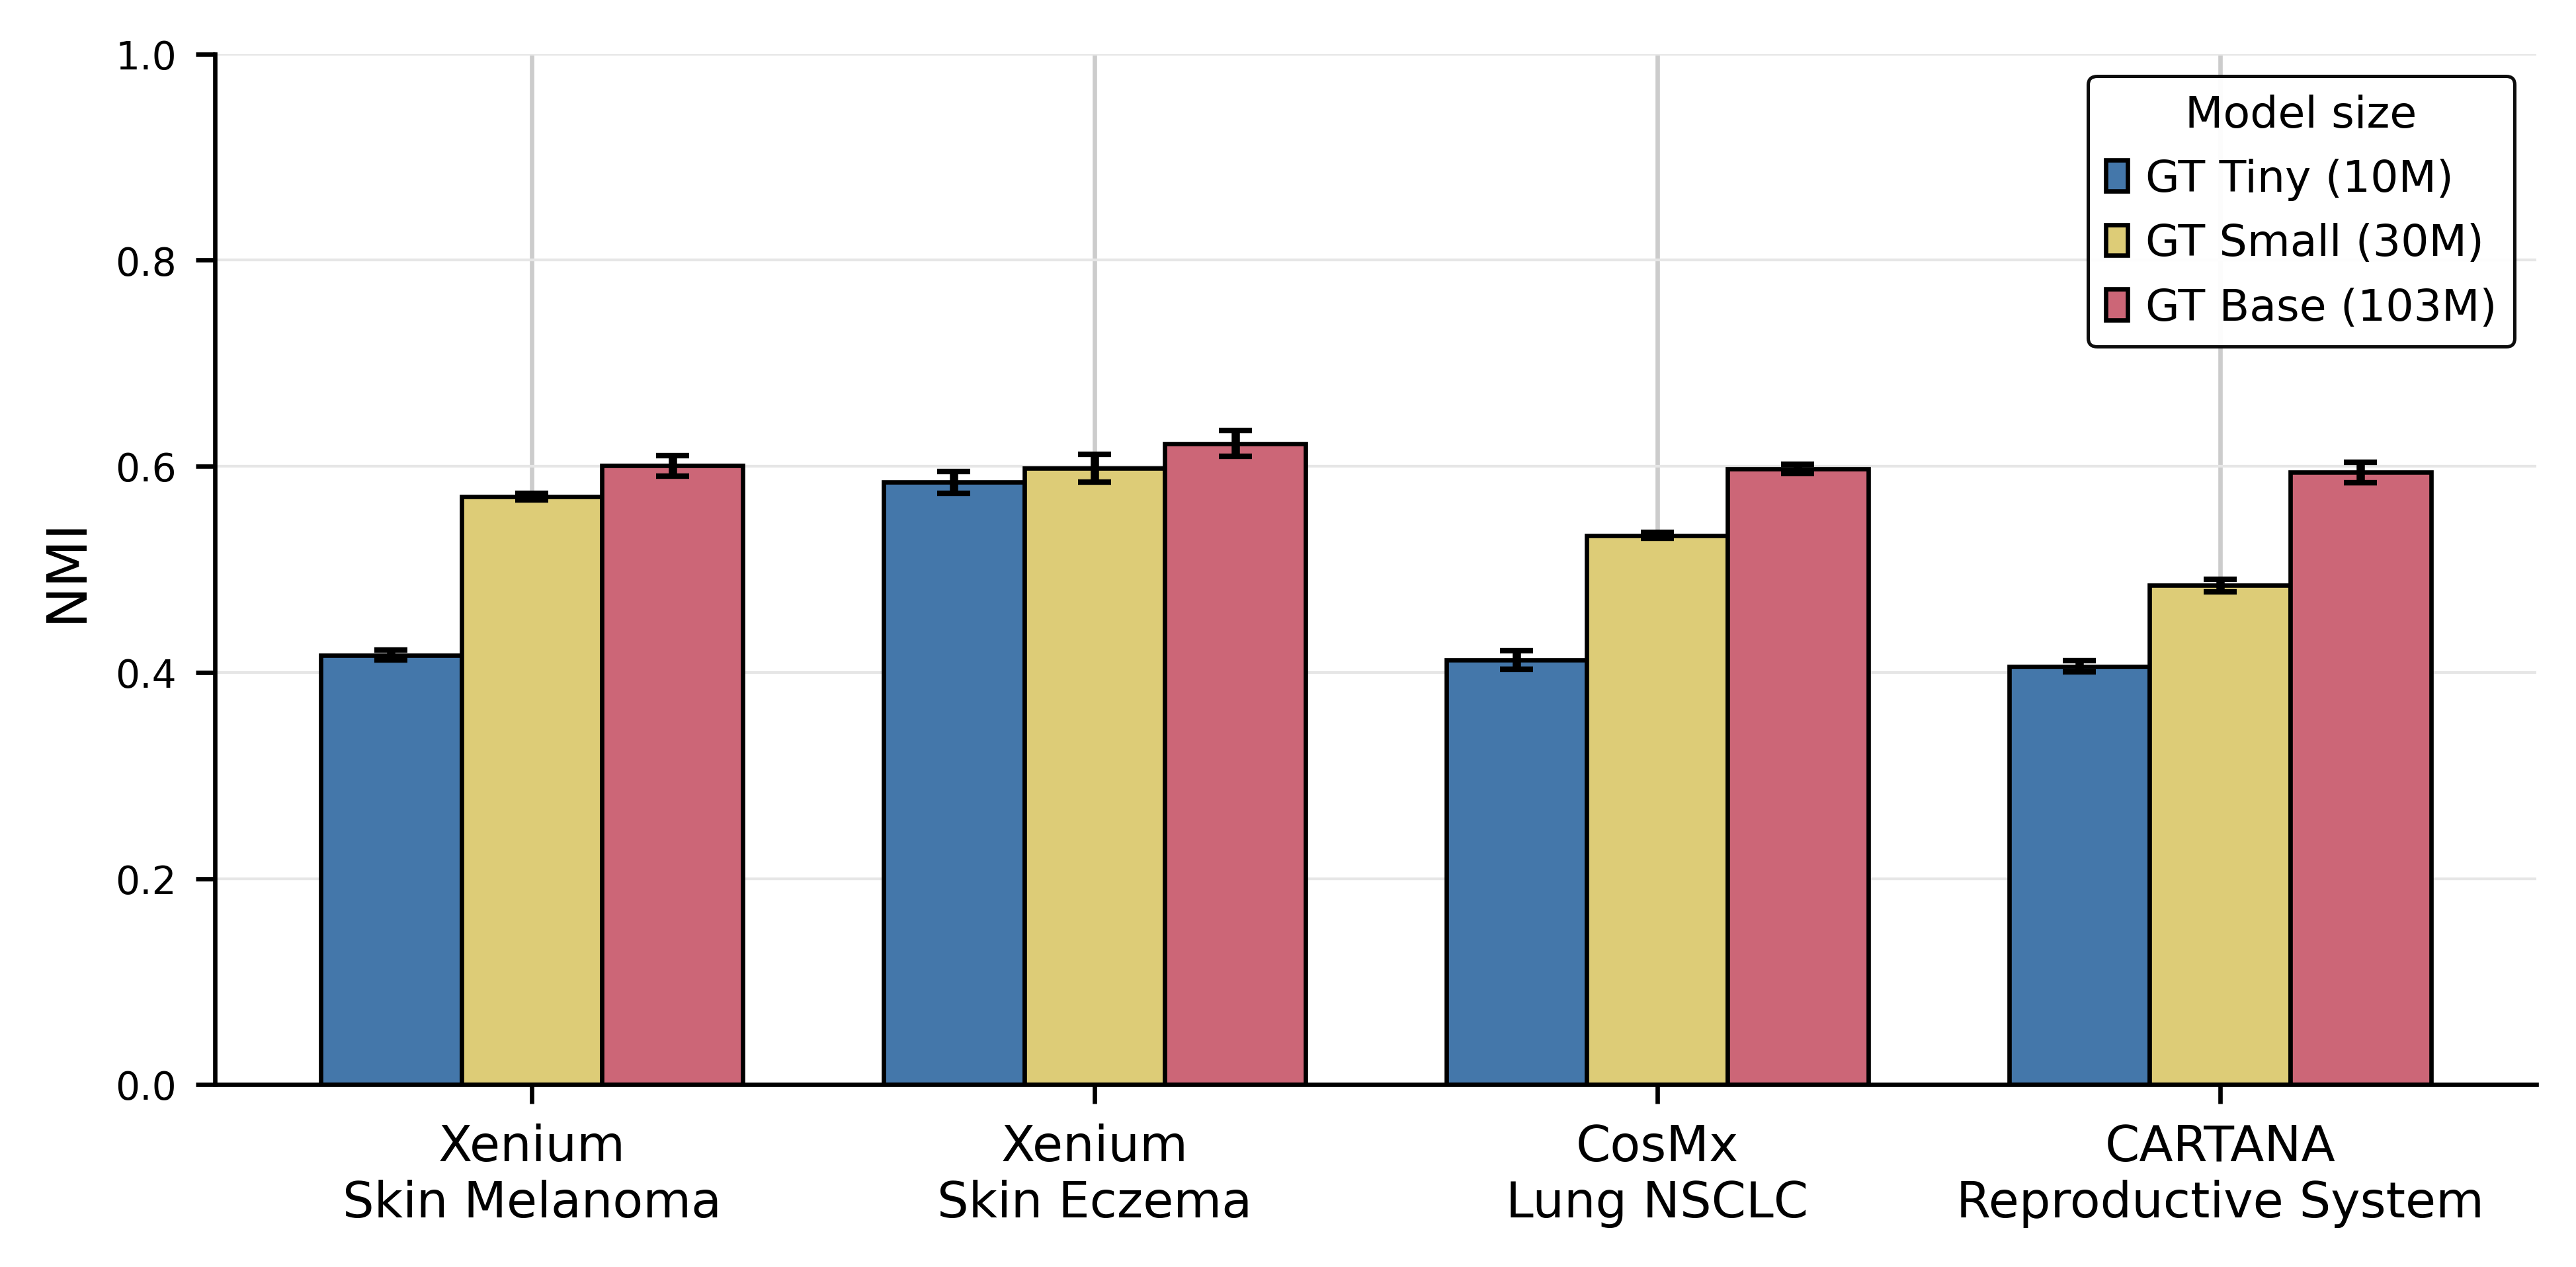

In [253]:
# --- Filter only NMI metric ---
df_nmi = df_neb[df_neb["metric"] == "NMI"]

# --- Compute mean and std per dataset × config ---
stats = (
    df_nmi.groupby(["dataset", "config"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)

# --- Enforce dataset order ---
desired_order = [
    "Xenium Skin Melanoma",
    "Xenium Skin Eczema",
    "CosMx Lung NSCLC",
    "CARTANA Reproductive System",
]
stats["dataset"] = pd.Categorical(stats["dataset"], categories=desired_order, ordered=True)
stats = stats.sort_values("dataset").reset_index(drop=True)

# --- Configuration ---
configs = ["gt_tiny", "gt_small", "gt_base"]
config_labels = {
    "gt_tiny": "GT Tiny (10M)",
    "gt_small": "GT Small (30M)",
    "gt_base": "GT Base (103M)",
}
colors = ["#4477AA", "#DDCC77", "#CC6677"]

datasets = stats["dataset"].unique()
bar_width = 0.25
x = range(len(datasets))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=300)

# --- Plot bars for each configuration ---
for i, cfg in enumerate(configs):
    subset = stats[stats["config"] == cfg]
    ax.bar(
        [xi + (i - 1) * bar_width for xi in x],
        subset["mean"],
        yerr=subset["std"],
        width=bar_width,
        label=config_labels[cfg],
        color=colors[i],
        edgecolor="black",
        linewidth=0.8,
        capsize=3,
    )

# --- Wrap labels after the first word ---
def wrap_after_first_word(label):
    parts = label.split(" ", 1)
    return "\n".join(parts) if len(parts) > 1 else label

wrapped_labels = [wrap_after_first_word(ds) for ds in datasets]

ax.set_xticks(x)
ax.set_xticklabels(wrapped_labels, fontsize=9, ha="center")

# --- Aesthetics ---
ax.set_ylabel("NMI", fontsize=10)
ax.set_ylim(0, 1.0)

# Boxed legend (clean, professional look)
legend = ax.legend(
    frameon=True,
    fontsize=8,
    loc="upper right",
    framealpha=0.95,
    fancybox=True,
    edgecolor="black",
    title="Model size",
    title_fontsize=8,
)
legend.get_frame().set_linewidth(0.6)

# Clean spines and grid
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="0.9", linestyle="-", linewidth=0.5)
ax.set_axisbelow(True)

save_path = os.path.join(sc.settings.figdir, "model_size_niche_nmi_comparison.svg")
plt.savefig(save_path, bbox_inches="tight", format="svg")
print(f"✅ Figure saved to: {save_path}")

plt.tight_layout()
plt.show()

✅ Figure saved to: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/ablation/figures/model_size_niche_ari_comparison.svg


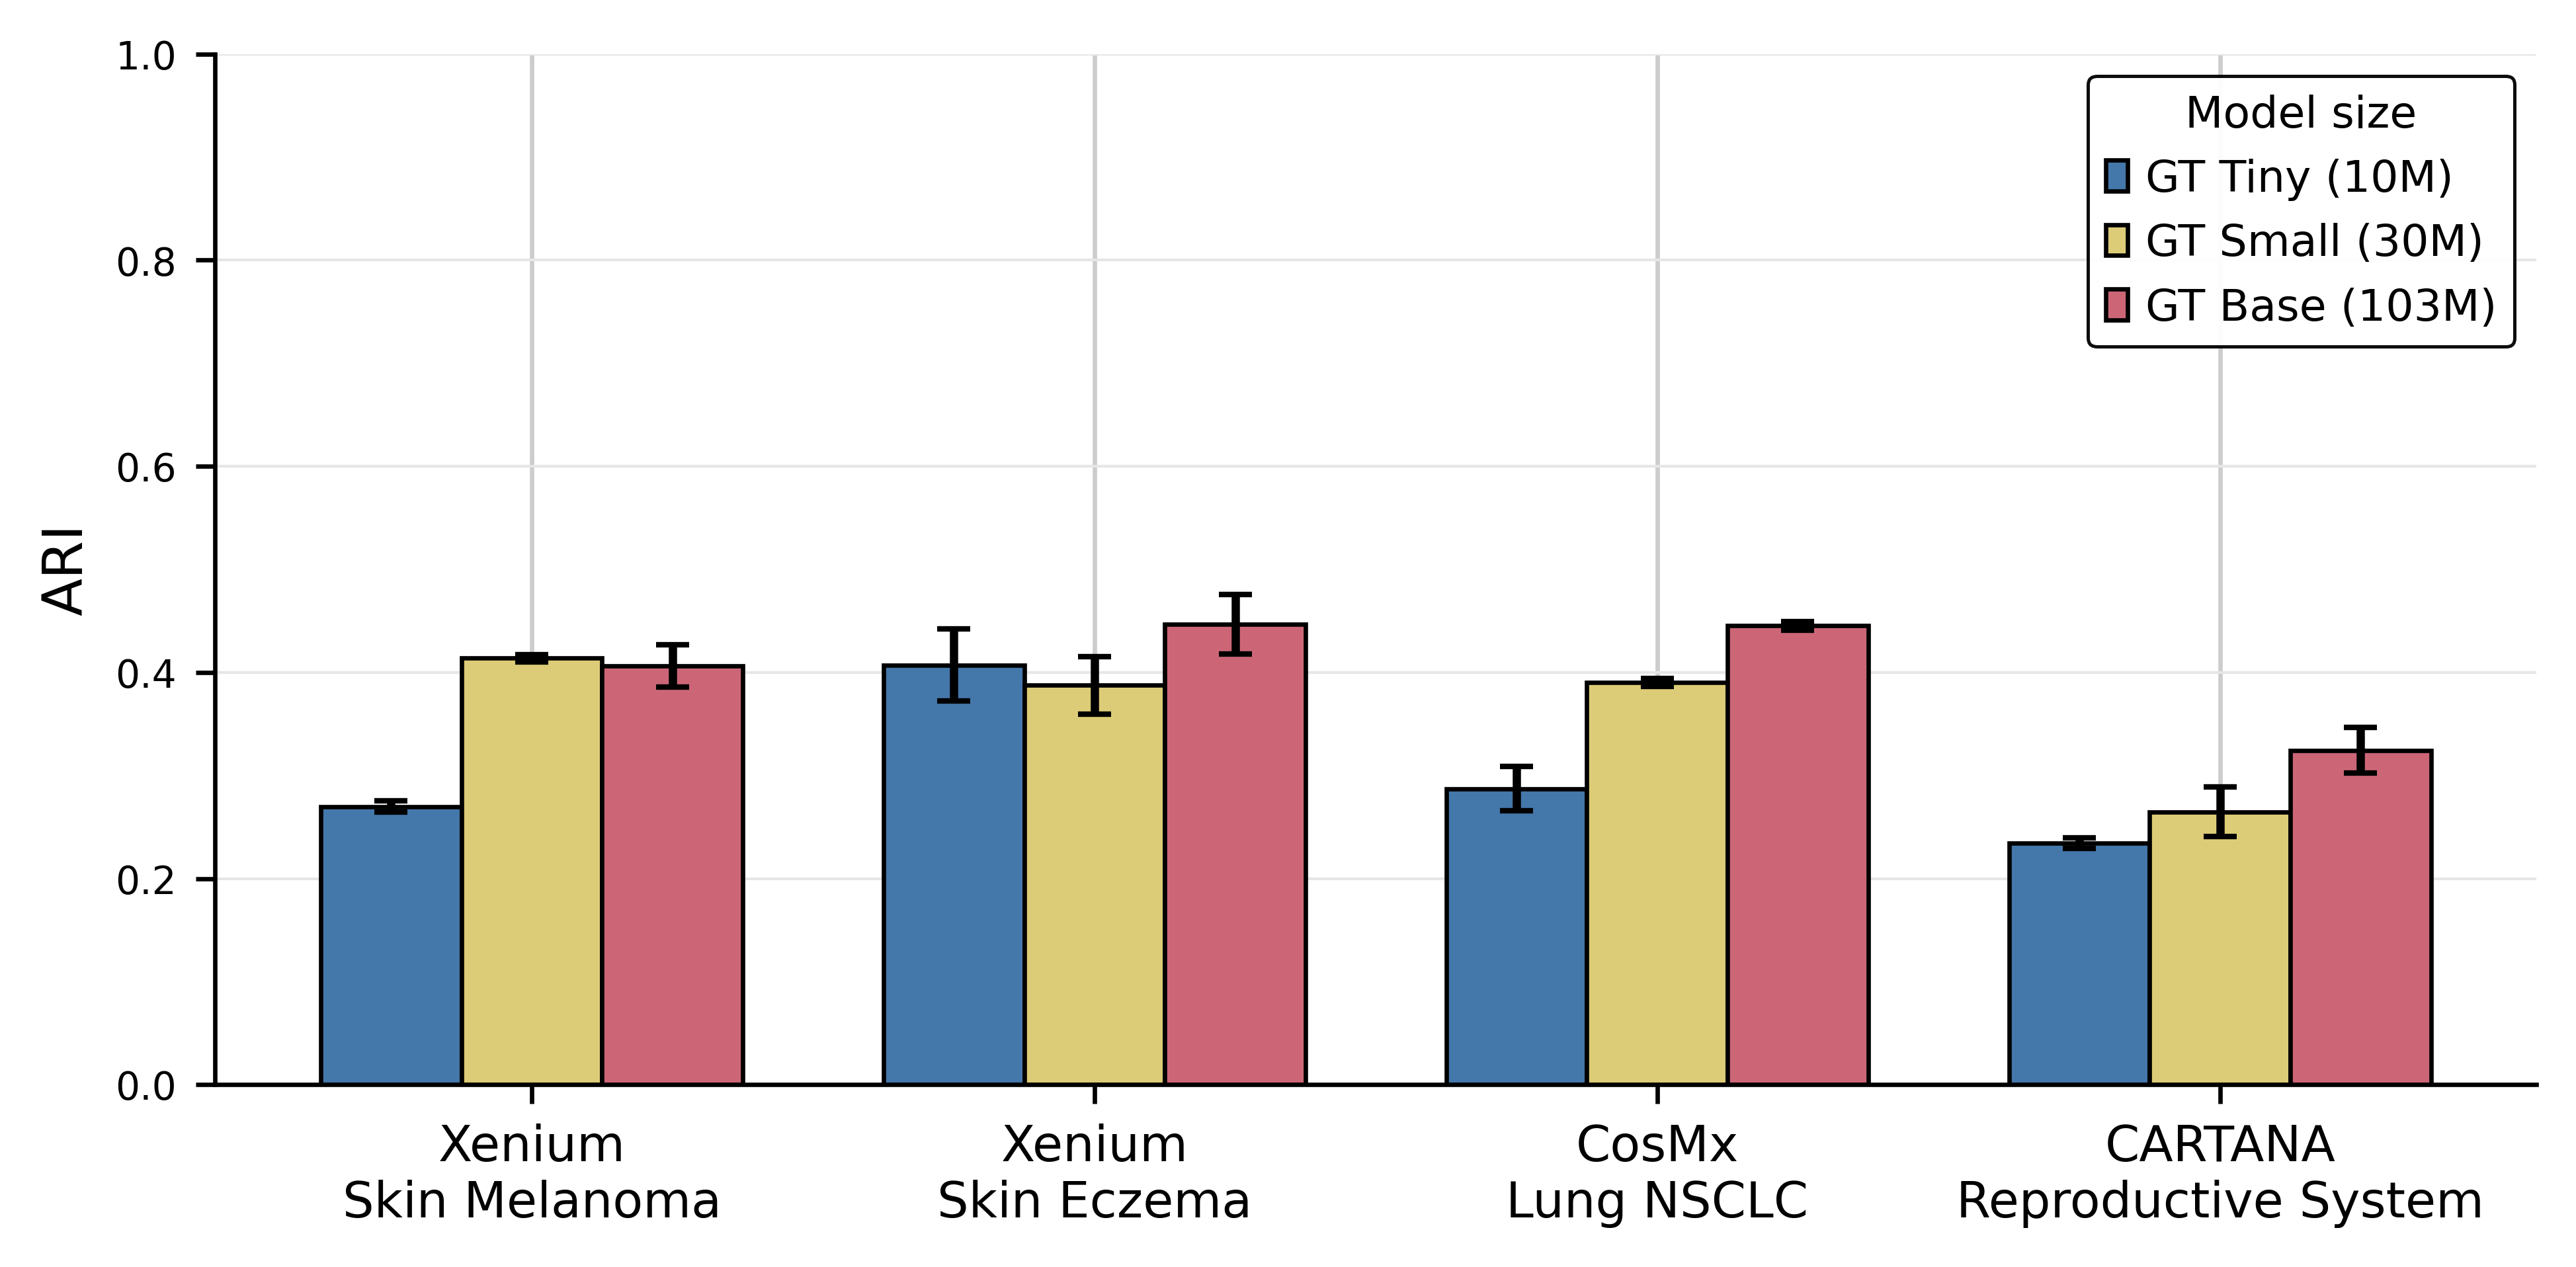

In [254]:
# --- Filter only ARI metric ---
df_nmi = df_neb[df_neb["metric"] == "ARI"]

# --- Compute mean and std per dataset × config ---
stats = (
    df_nmi.groupby(["dataset", "config"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)

# --- Enforce dataset order ---
desired_order = [
    "Xenium Skin Melanoma",
    "Xenium Skin Eczema",
    "CosMx Lung NSCLC",
    "CARTANA Reproductive System",
]
stats["dataset"] = pd.Categorical(stats["dataset"], categories=desired_order, ordered=True)
stats = stats.sort_values("dataset").reset_index(drop=True)

# --- Configuration ---
configs = ["gt_tiny", "gt_small", "gt_base"]
config_labels = {
    "gt_tiny": "GT Tiny (10M)",
    "gt_small": "GT Small (30M)",
    "gt_base": "GT Base (103M)",
}
colors = ["#4477AA", "#DDCC77", "#CC6677"]

datasets = stats["dataset"].unique()
bar_width = 0.25
x = range(len(datasets))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=300)

# --- Plot bars for each configuration ---
for i, cfg in enumerate(configs):
    subset = stats[stats["config"] == cfg]
    ax.bar(
        [xi + (i - 1) * bar_width for xi in x],
        subset["mean"],
        yerr=subset["std"],
        width=bar_width,
        label=config_labels[cfg],
        color=colors[i],
        edgecolor="black",
        linewidth=0.8,
        capsize=3,
    )

# --- Wrap labels after the first word ---
def wrap_after_first_word(label):
    parts = label.split(" ", 1)
    return "\n".join(parts) if len(parts) > 1 else label

wrapped_labels = [wrap_after_first_word(ds) for ds in datasets]

ax.set_xticks(x)
ax.set_xticklabels(wrapped_labels, fontsize=9, ha="center")

# --- Aesthetics ---
ax.set_ylabel("ARI", fontsize=10)
ax.set_ylim(0, 1.0)

# Boxed legend (clean, professional look)
legend = ax.legend(
    frameon=True,
    fontsize=8,
    loc="upper right",
    framealpha=0.95,
    fancybox=True,
    edgecolor="black",
    title="Model size",
    title_fontsize=8,
)
legend.get_frame().set_linewidth(0.6)

# Clean spines and grid
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="0.9", linestyle="-", linewidth=0.5)
ax.set_axisbelow(True)

save_path = os.path.join(sc.settings.figdir, "model_size_niche_ari_comparison.svg")
plt.savefig(save_path, bbox_inches="tight", format="svg")
print(f"✅ Figure saved to: {save_path}")

plt.tight_layout()
plt.show()

✅ Figure saved to: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/ablation/figures/model_size_cell_type_nmi_comparison.svg


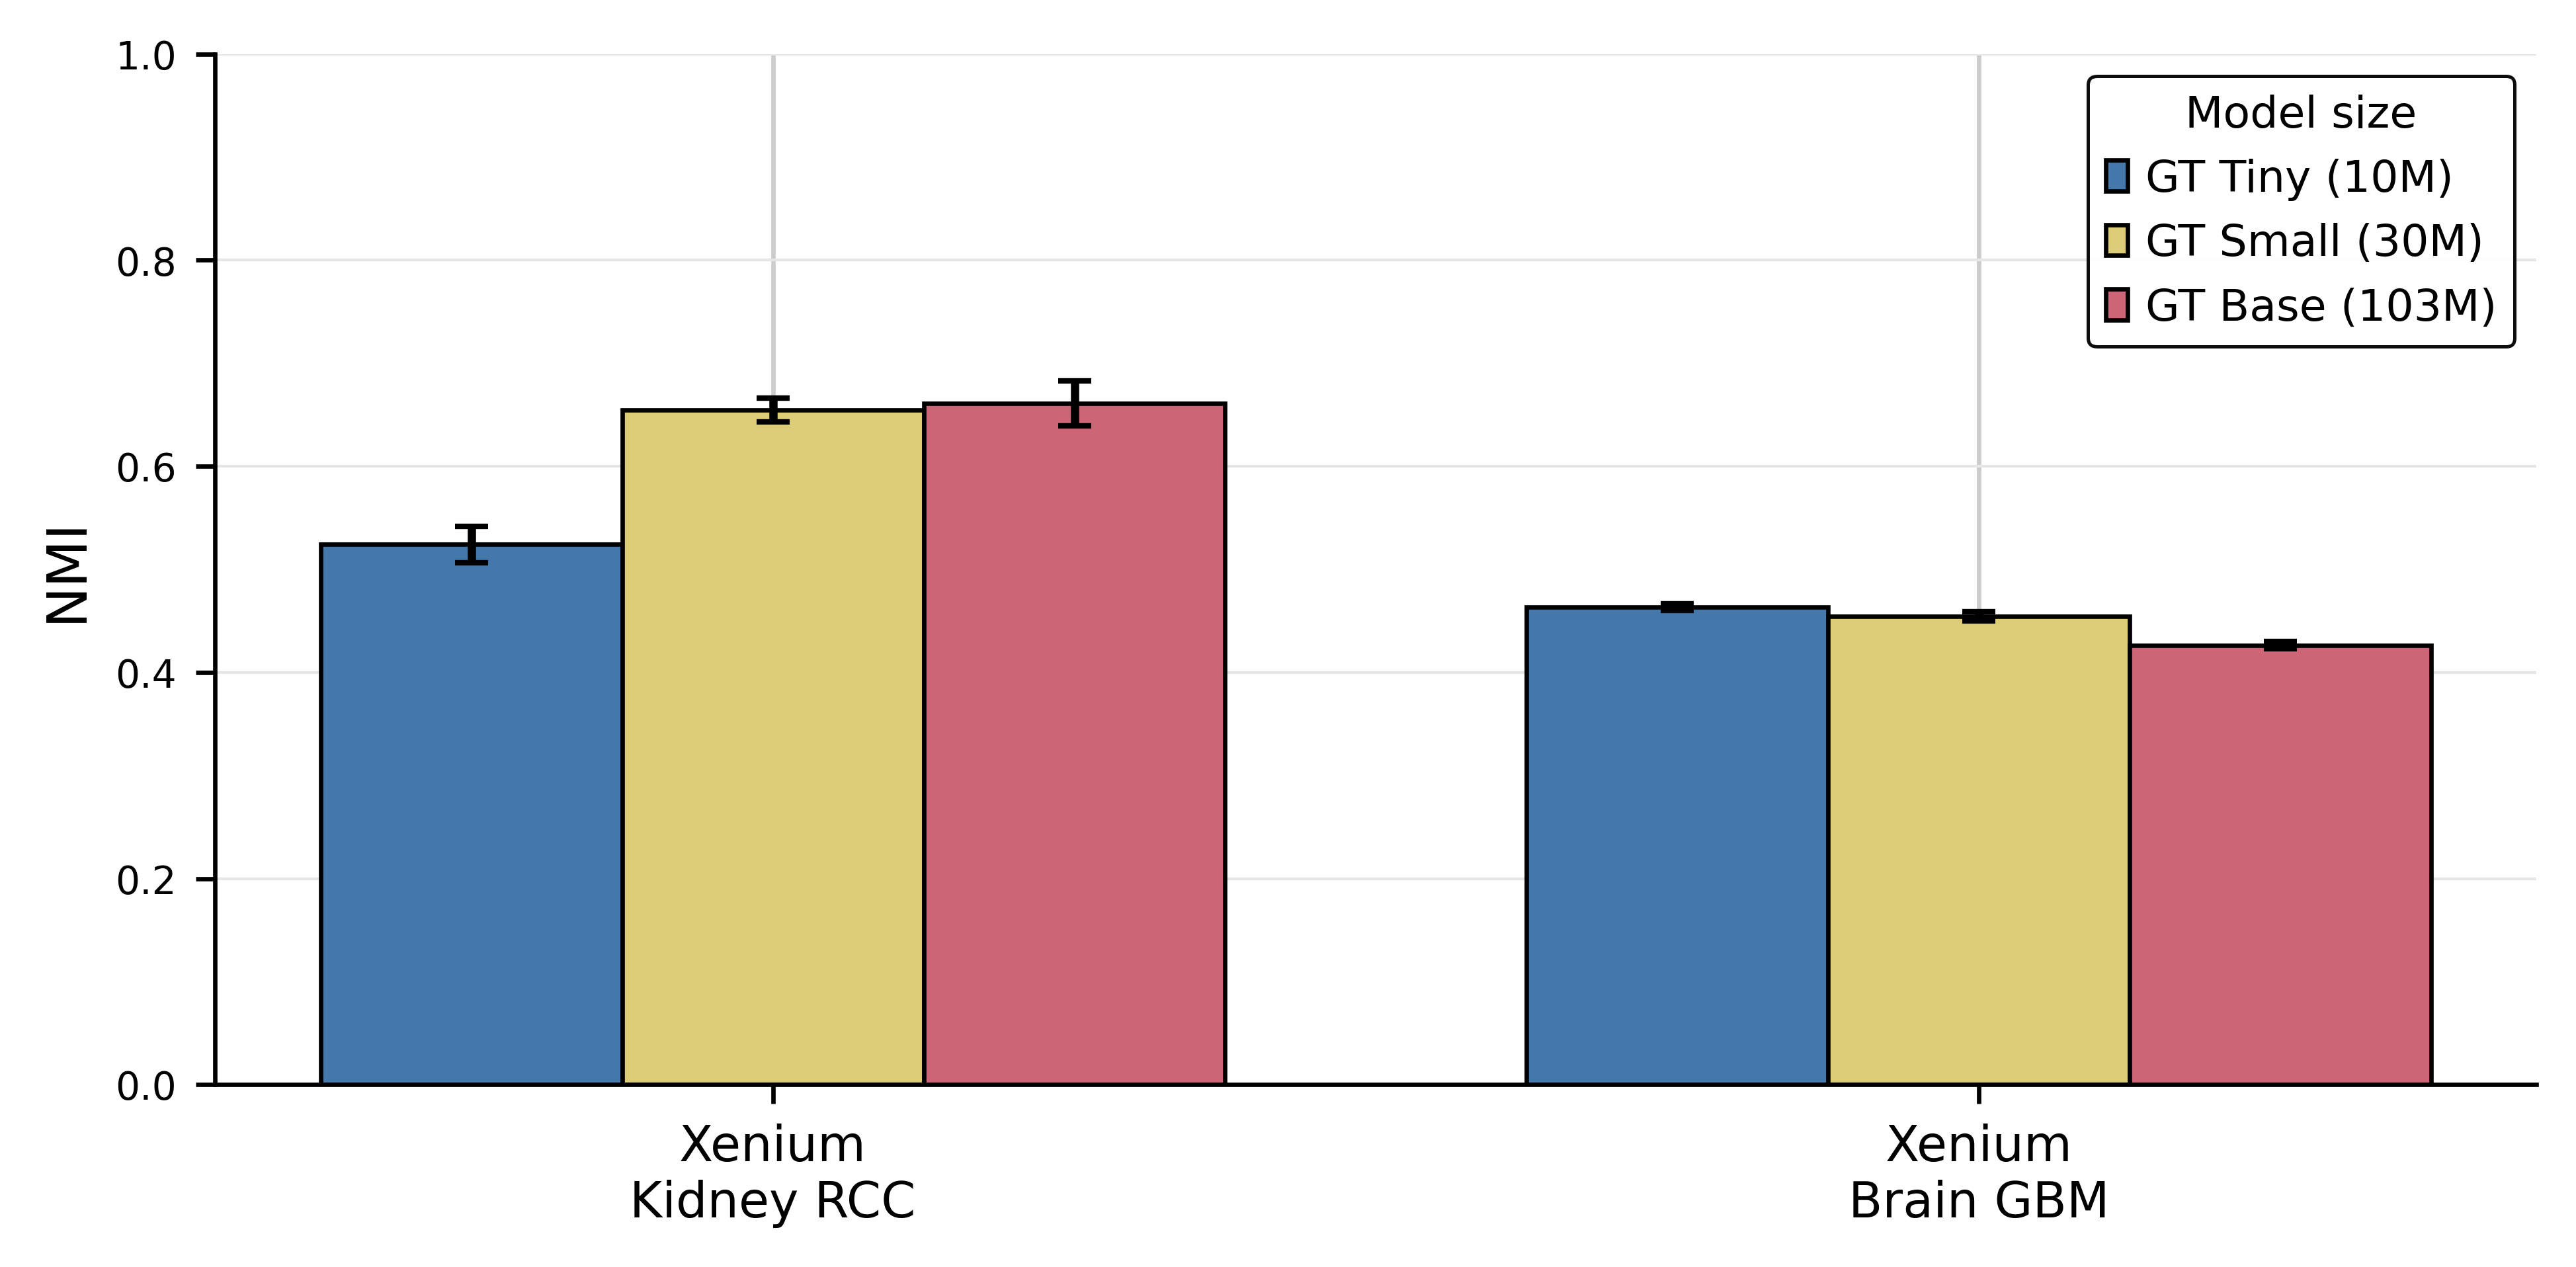

In [278]:
# --- Filter only NMI metric ---
df_nmi = df_cell[df_cell["metric"] == "NMI"]

# --- Compute mean and std per dataset × config ---
stats = (
    df_nmi.groupby(["dataset", "config"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)

# --- Enforce dataset order ---
desired_order = [
    "Xenium Kidney RCC",
    "Xenium Brain GBM",
]
stats["dataset"] = pd.Categorical(stats["dataset"], categories=desired_order, ordered=True)
stats = stats.sort_values("dataset").reset_index(drop=True)

# --- Configuration ---
configs = ["gt_tiny", "gt_small", "gt_base"]
config_labels = {
    "gt_tiny": "GT Tiny (10M)",
    "gt_small": "GT Small (30M)",
    "gt_base": "GT Base (103M)",
}
colors = ["#4477AA", "#DDCC77", "#CC6677"]

datasets = stats["dataset"].unique()
bar_width = 0.25
x = range(len(datasets))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=300)

# --- Plot bars for each configuration ---
for i, cfg in enumerate(configs):
    subset = stats[stats["config"] == cfg]
    ax.bar(
        [xi + (i - 1) * bar_width for xi in x],
        subset["mean"],
        yerr=subset["std"],
        width=bar_width,
        label=config_labels[cfg],
        color=colors[i],
        edgecolor="black",
        linewidth=0.8,
        capsize=3,
    )

# --- Wrap labels after the first word ---
def wrap_after_first_word(label):
    parts = label.split(" ", 1)
    return "\n".join(parts) if len(parts) > 1 else label

wrapped_labels = [wrap_after_first_word(ds) for ds in datasets]

ax.set_xticks(x)
ax.set_xticklabels(wrapped_labels, fontsize=9, ha="center")

# --- Aesthetics ---
ax.set_ylabel("NMI", fontsize=10)
ax.set_ylim(0, 1.0)

# Boxed legend (clean, professional look)
legend = ax.legend(
    frameon=True,
    fontsize=8,
    loc="upper right",
    framealpha=0.95,
    fancybox=True,
    edgecolor="black",
    title="Model size",
    title_fontsize=8,
)
legend.get_frame().set_linewidth(0.6)

# Clean spines and grid
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="0.9", linestyle="-", linewidth=0.5)
ax.set_axisbelow(True)

save_path = os.path.join(sc.settings.figdir, "model_size_cell_type_nmi_comparison.svg")
plt.savefig(save_path, bbox_inches="tight", format="svg")
print(f"✅ Figure saved to: {save_path}")

plt.tight_layout()
plt.show()

✅ Figure saved to: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/ablation/figures/model_size_cell_type_ari_comparison.svg


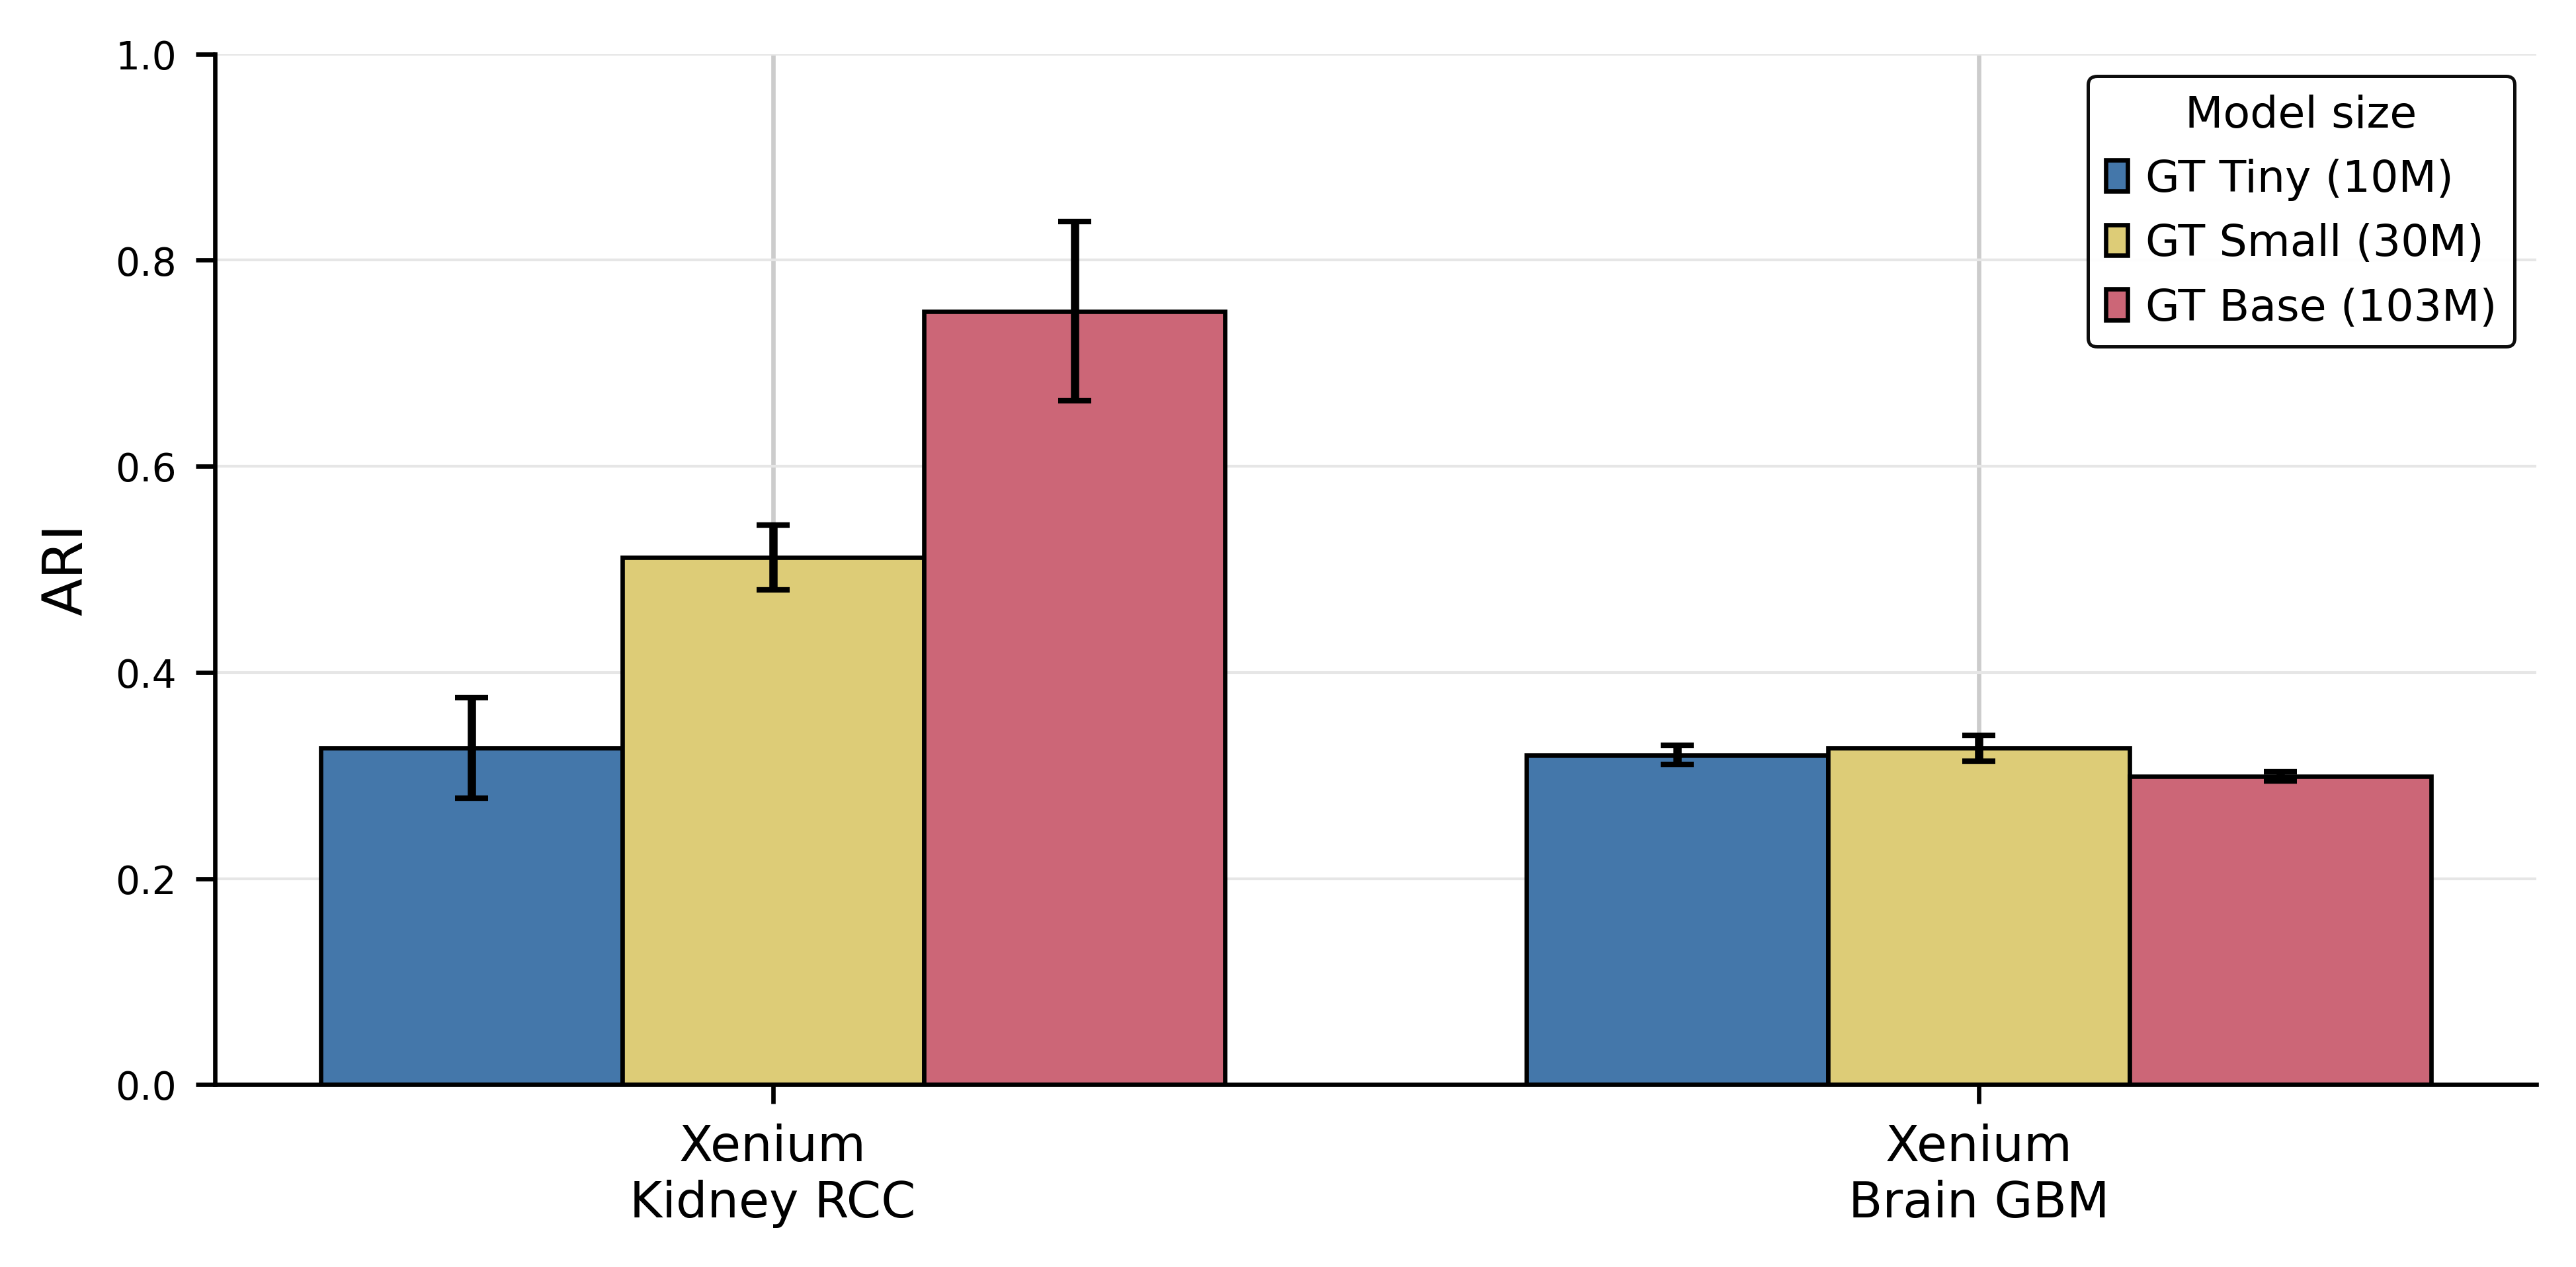

In [279]:
# --- Filter only ARI metric ---
df_nmi = df_cell[df_cell["metric"] == "ARI"]

# --- Compute mean and std per dataset × config ---
stats = (
    df_nmi.groupby(["dataset", "config"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)

# --- Enforce dataset order ---
desired_order = [
    "Xenium Kidney RCC",
    "Xenium Brain GBM",
]
stats["dataset"] = pd.Categorical(stats["dataset"], categories=desired_order, ordered=True)
stats = stats.sort_values("dataset").reset_index(drop=True)

# --- Configuration ---
configs = ["gt_tiny", "gt_small", "gt_base"]
config_labels = {
    "gt_tiny": "GT Tiny (10M)",
    "gt_small": "GT Small (30M)",
    "gt_base": "GT Base (103M)",
}
colors = ["#4477AA", "#DDCC77", "#CC6677"]

datasets = stats["dataset"].unique()
bar_width = 0.25
x = range(len(datasets))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=300)

# --- Plot bars for each configuration ---
for i, cfg in enumerate(configs):
    subset = stats[stats["config"] == cfg]
    ax.bar(
        [xi + (i - 1) * bar_width for xi in x],
        subset["mean"],
        yerr=subset["std"],
        width=bar_width,
        label=config_labels[cfg],
        color=colors[i],
        edgecolor="black",
        linewidth=0.8,
        capsize=3,
    )

# --- Wrap labels after the first word ---
def wrap_after_first_word(label):
    parts = label.split(" ", 1)
    return "\n".join(parts) if len(parts) > 1 else label

wrapped_labels = [wrap_after_first_word(ds) for ds in datasets]

ax.set_xticks(x)
ax.set_xticklabels(wrapped_labels, fontsize=9, ha="center")

# --- Aesthetics ---
ax.set_ylabel("ARI", fontsize=10)
ax.set_ylim(0, 1.0)

# Boxed legend (clean, professional look)
legend = ax.legend(
    frameon=True,
    fontsize=8,
    loc="upper right",
    framealpha=0.95,
    fancybox=True,
    edgecolor="black",
    title="Model size",
    title_fontsize=8,
)
legend.get_frame().set_linewidth(0.6)

# Clean spines and grid
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="0.9", linestyle="-", linewidth=0.5)
ax.set_axisbelow(True)

save_path = os.path.join(sc.settings.figdir, "model_size_cell_type_ari_comparison.svg")
plt.savefig(save_path, bbox_inches="tight", format="svg")
print(f"✅ Figure saved to: {save_path}")

plt.tight_layout()
plt.show()

## 2.2 Dataset Size Ablation

### 2.2.1 xhs49-1b_1p (Xenium Human Skin Melanoma)

In [21]:
# Define dataset config
dataset_name = 'xhs49-1b_1p'
obsm_key = 'neighborhood_emb_layer_12'
label_col = 'niche_name'

#### 2.2.1.1 1 Percent Sample

In [22]:
config_name = '1_pct_sample'
load_timestamp = '12112025_132402_667'
read_checkpoint = 'nichejepa-ep199.pth.tar'
start_latent_leiden_resolution = 0.4

In [23]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 98749 × 0
    obs: 'niche_name', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_399', 'neighborhood_emb_leiden_res0_398', 'neighborhood_emb_leiden_res0_397', 'neighborhood_emb_leiden_res0_396'
    uns: 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_396', 'neighborhood_emb_leiden_res0_396_colors', 'neighborhood_emb_leiden_res0_397', 'neighborhood_emb_leiden_res0_398', 'neighborhood_emb_leiden_res0_399', 'neighborhood_emb_leiden_res0_4', 'neighborhood_umap', 'niche_name_colors', 'neighborhood_emb_layer_12'
    obsm: 'X_umap', 'cell_emb_layer_12', 'cell_umap', 'neighborhood_emb_layer_12', 'neighborhood_umap', 'spatial'
    obsp: 'cell_connectivities', 'cell_distances', 'neighborhood_connectivities', 'neighborhood_distances'
Target number of unique values: 8.
Leiden resolution: 0.4.
Number of latent clusters 8.
NMI is 0.4677269186119995. ARI is 0.3371337556749283.
NMI is 0.4715338660901721

#### 2.2.1.2 10 Percent Sample

In [24]:
config_name = '10_pct_sample'
load_timestamp = '08112025_183353_702'
read_checkpoint = 'nichejepa-ep19.pth.tar'
start_latent_leiden_resolution = 0.4

In [25]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 98749 × 0
    obs: 'niche_name', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_38', 'neighborhood_emb_leiden_res0_379', 'neighborhood_emb_leiden_res0_378', 'neighborhood_emb_leiden_res0_377', 'neighborhood_emb_leiden_res0_376', 'neighborhood_emb_leiden_res0_375', 'neighborhood_emb_leiden_res0_355', 'neighborhood_emb_leiden_res0_354', 'neighborhood_emb_leiden_res0_353', 'neighborhood_emb_leiden_res0_352', 'neighborhood_emb_leiden_res0_351', 'neighborhood_emb_leiden_res0_35', 'neighborhood_emb_leiden_res0_349', 'neighborhood_emb_leiden_res0_348', 'neighborhood_emb_leiden_res0_347', 'neighborhood_emb_leiden_res0_346', 'neighborhood_emb_leiden_res0_345', 'neighborhood_emb_leiden_res0_344', 'neighborhood_emb_leiden_res0_34299999999999997', 'neighborhood_emb_leiden_res0_34199999999999997', 'neighborhood_emb_leiden_res0_34099999999999997', 'neighborhood_emb_leiden_res0_33999999999999997', 'neighborhood_emb_leid

#### 2.2.1.3 25 Percent Sample

In [26]:
config_name = '25_pct_sample'
load_timestamp = '10112025_185828_463'
read_checkpoint = 'nichejepa-ep7.pth.tar'
start_latent_leiden_resolution = 0.4

In [27]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 98749 × 0
    obs: 'niche_name', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_38', 'neighborhood_emb_leiden_res0_36', 'neighborhood_emb_leiden_res0_359', 'neighborhood_emb_leiden_res0_358', 'neighborhood_emb_leiden_res0_357', 'neighborhood_emb_leiden_res0_356', 'neighborhood_emb_leiden_res0_355', 'neighborhood_emb_leiden_res0_354', 'neighborhood_emb_leiden_res0_353', 'neighborhood_emb_leiden_res0_352', 'neighborhood_emb_leiden_res0_351', 'neighborhood_emb_leiden_res0_35', 'neighborhood_emb_leiden_res0_349', 'neighborhood_emb_leiden_res0_348', 'neighborhood_emb_leiden_res0_347', 'neighborhood_emb_leiden_res0_346', 'neighborhood_emb_leiden_res0_345', 'neighborhood_emb_leiden_res0_344', 'neighborhood_emb_leiden_res0_34299999999999997', 'neighborhood_emb_leiden_res0_34199999999999997', 'neighborhood_emb_leiden_res0_34099999999999997', 'neighborhood_emb_leiden_res0_33999999999999997', 'neighborhood_emb_leide

#### 2.2.1.4 50 Percent Sample

In [29]:
config_name = '50_pct_sample'
load_timestamp = '09112025_190730_770'
read_checkpoint = 'nichejepa-ep5.pth.tar'
start_latent_leiden_resolution = 0.4

In [30]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 98749 × 0
    obs: 'niche_name', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_35000000000000003', 'neighborhood_emb_leiden_res0_33', 'neighborhood_emb_leiden_res0_329', 'neighborhood_emb_leiden_res0_309', 'neighborhood_emb_leiden_res0_308', 'neighborhood_emb_leiden_res0_307', 'neighborhood_emb_leiden_res0_306', 'neighborhood_emb_leiden_res0_305', 'neighborhood_emb_leiden_res0_304', 'neighborhood_emb_leiden_res0_303', 'neighborhood_emb_leiden_res0_302', 'neighborhood_emb_leiden_res0_301', 'neighborhood_emb_leiden_res0_3', 'neighborhood_emb_leiden_res0_299', 'neighborhood_emb_leiden_res0_298', 'neighborhood_emb_leiden_res0_297', 'neighborhood_emb_leiden_res0_296', 'neighborhood_emb_leiden_res0_295', 'neighborhood_emb_leiden_res0_294', 'neighborhood_emb_leiden_res0_293', 'neighborhood_emb_leiden_res0_292', 'neighborhood_emb_leiden_res0_291', 'neighborhood_emb_leiden_res0_29', 'neighborhood_emb_leiden_res0_

#### 2.2.1.5 100 Percent Sample

In [31]:
config_name = '100_pct_sample'
load_timestamp = '01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [32]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 98749 × 0
    obs: 'niche_name', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_35000000000000003', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_28', 'neighborhood_emb_leiden_res0_26', 'neighborhood_emb_leiden_res0_259', 'neighborhood_emb_leiden_res0_23900000000000002', 'neighborhood_emb_leiden_res0_23800000000000002', 'neighborhood_emb_leiden_res0_23700000000000002', 'neighborhood_emb_leiden_res0_23600000000000002', 'neighborhood_emb_leiden_res0_23500000000000001', 'neighborhood_emb_leiden_res0_234', 'neighborhood_emb_leiden_res0_233', 'neighborhood_emb_leiden_res0_232', 'neighborhood_emb_leiden_res0_231', 'neighborhood_emb_leiden_res0_23', 'neighborhood_emb_leiden_res0_229', 'neighborhood_emb_leiden_res0_228', 'neighborhood_emb_leiden_res0_227', 'neighborhood_emb_leiden_res0_226', 'neighborhood_emb_leiden_res0_225', 'neighborhood_emb_leiden_res0_224', 'neighborhood_emb

### 2.2.2 xhs1000-39b_1p (Xenium Human Skin Eczema)

In [33]:
# Define dataset config
dataset_name = 'xhs1000-39b_1p'
obsm_key = 'neighborhood_emb_layer_12'
label_col = 'niche_type'

#### 2.2.2.1 1 Percent Sample

In [34]:
config_name = '1_pct_sample'
load_timestamp = '12112025_132402_667'
read_checkpoint = 'nichejepa-ep199.pth.tar'
start_latent_leiden_resolution = 0.4

In [35]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 53655 × 0
    obs: 'niche_type', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_35000000000000003', 'neighborhood_emb_leiden_res0_33', 'neighborhood_emb_leiden_res0_28', 'neighborhood_emb_leiden_res0_26', 'neighborhood_emb_leiden_res0_259', 'neighborhood_emb_leiden_res0_258', 'neighborhood_emb_leiden_res0_257', 'neighborhood_emb_leiden_res0_256', 'neighborhood_emb_leiden_res0_255', 'neighborhood_emb_leiden_res0_254', 'neighborhood_emb_leiden_res0_253', 'neighborhood_emb_leiden_res0_252', 'neighborhood_emb_leiden_res0_251', 'neighborhood_emb_leiden_res0_25', 'neighborhood_emb_leiden_res0_249', 'neighborhood_emb_leiden_res0_248', 'neighborhood_emb_leiden_res0_247', 'neighborhood_emb_leiden_res0_246', 'neighborhood_emb_leiden_res0_245'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_245', 'neighborhood_emb_leiden_res0_245_colors', 'neighborhood_emb_leiden_res0_246'

#### 2.2.2.2 10 Percent Sample

In [36]:
config_name = '10_pct_sample'
load_timestamp = '08112025_183353_702'
read_checkpoint = 'nichejepa-ep19.pth.tar'
start_latent_leiden_resolution = 0.4

In [37]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 53655 × 0
    obs: 'niche_type', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_35000000000000003', 'neighborhood_emb_leiden_res0_34900000000000003', 'neighborhood_emb_leiden_res0_29900000000000004', 'neighborhood_emb_leiden_res0_279', 'neighborhood_emb_leiden_res0_259', 'neighborhood_emb_leiden_res0_23900000000000002', 'neighborhood_emb_leiden_res0_21900000000000003', 'neighborhood_emb_leiden_res0_21800000000000003', 'neighborhood_emb_leiden_res0_21700000000000003', 'neighborhood_emb_leiden_res0_21600000000000003', 'neighborhood_emb_leiden_res0_21500000000000002', 'neighborhood_emb_leiden_res0_21400000000000002', 'neighborhood_emb_leiden_res0_21300000000000002', 'neighborhood_emb_leiden_res0_21200000000000002', 'neighborhood_emb_leiden_res0_21100000000000002', 'neighborhood_emb_leiden_res0_21000000000000002', 'neighborhood_emb_leiden_res0_21150786470953947'
    uns: 'batch_colors', 'cell', 'cell_umap', '

#### 2.2.2.3 25 Percent Sample

In [38]:
config_name = '25_pct_sample'
load_timestamp = '10112025_185828_463'
read_checkpoint = 'nichejepa-ep7.pth.tar'
start_latent_leiden_resolution = 0.4

In [39]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 53655 × 0
    obs: 'niche_type', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_35000000000000003', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_28', 'neighborhood_emb_leiden_res0_26', 'neighborhood_emb_leiden_res0_259', 'neighborhood_emb_leiden_res0_258', 'neighborhood_emb_leiden_res0_257', 'neighborhood_emb_leiden_res0_23700000000000002'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_23700000000000002', 'neighborhood_emb_leiden_res0_23700000000000002_colors', 'neighborhood_emb_leiden_res0_257', 'neighborhood_emb_leiden_res0_258', 'neighborhood_emb_leiden_res0_259', 'neighborhood_emb_leiden_res0_26', 'neighborhood_emb_leiden_res0_28', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_35000000000000003', 'neighborhood_emb_leiden_res0_4', 'neighborhood_umap', 'niche_type_colors', 'neighborhood_emb_

#### 2.2.2.4 50 Percent Sample

In [40]:
config_name = '50_pct_sample'
load_timestamp = '09112025_190730_770'
read_checkpoint = 'nichejepa-ep5.pth.tar'
start_latent_leiden_resolution = 0.4

In [41]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 53655 × 0
    obs: 'niche_type', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_20000000000000004', 'neighborhood_emb_leiden_res0_15000000000000002', 'neighborhood_emb_leiden_res0_10000000000000002', 'neighborhood_emb_leiden_res0_09900000000000002'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_09900000000000002', 'neighborhood_emb_leiden_res0_09900000000000002_colors', 'neighborhood_emb_leiden_res0_10000000000000002', 'neighborhood_emb_leiden_res0_15000000000000002', 'neighborhood_emb_leiden_res0_20000000000000004', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_4', 'neighborhood_umap', 'niche_type_colors', 'neighborhood_emb_layer_12'
    obsm: 'X_umap', 'cell_emb_layer_12', 'cell_umap', 'neighborhood_emb_layer_12', 'neighborhood_umap', 'spatial'
    obsp: 'cell_connectivities',

#### 2.2.2.5 100 Percent Sample

In [42]:
config_name = '100_pct_sample'
load_timestamp = '01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [43]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 53655 × 0
    obs: 'niche_type', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_20000000000000004', 'neighborhood_emb_leiden_res0_10000000000000003', 'neighborhood_emb_leiden_res0_08000000000000003', 'neighborhood_emb_leiden_res0_07900000000000003', 'neighborhood_emb_leiden_res0_07800000000000003', 'neighborhood_emb_leiden_res0_07700000000000003'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_07700000000000003', 'neighborhood_emb_leiden_res0_07700000000000003_colors', 'neighborhood_emb_leiden_res0_07800000000000003', 'neighborhood_emb_leiden_res0_07900000000000003', 'neighborhood_emb_leiden_res0_08000000000000003', 'neighborhood_emb_leiden_res0_10000000000000003', 'neighborhood_emb_leiden_res0_20000000000000004', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_4', 'neighborhood_um

### 2.2.3 xhk1007-41b_1p (Xenium Human Kidney RCC)

In [44]:
# Define dataset config
dataset_name = 'xhk1007-41b_1p'
obsm_key = 'cell_emb_layer_12'
label_col = 'level_1_cell_type'

#### 2.2.3.1 1 Percent Sample

In [45]:
config_name = '1_pct_sample'
load_timestamp = '12112025_132402_667'
read_checkpoint = 'nichejepa-ep199.pth.tar'
start_latent_leiden_resolution = 0.4

In [46]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 135746 × 0
    obs: 'level_1_cell_type', 'gene_panel_size', 'batch', 'cell_emb_leiden_res0_75', 'cell_emb_leiden_res0_73', 'cell_emb_leiden_res0_6799999999999999', 'cell_emb_leiden_res0_6299999999999999', 'cell_emb_leiden_res0_6099999999999999', 'cell_emb_leiden_res0_5899999999999999', 'cell_emb_leiden_res0_5699999999999998', 'cell_emb_leiden_res0_5499999999999998', 'cell_emb_leiden_res0_5299999999999998', 'cell_emb_leiden_res0_5099999999999998', 'cell_emb_leiden_res0_48999999999999977', 'cell_emb_leiden_res0_48899999999999977', 'cell_emb_leiden_res0_48799999999999977', 'cell_emb_leiden_res0_46799999999999975', 'cell_emb_leiden_res0_46699999999999975', 'cell_emb_leiden_res0_46599999999999975', 'cell_emb_leiden_res0_46499999999999975', 'cell_emb_leiden_res0_46399999999999975', 'cell_emb_leiden_res0_46299999999999975', 'cell_emb_leiden_res0_46199999999999974', 'cell_emb_leiden_res0_46099999999999974', 'cell_emb_leiden_res0_4409999999999997', 'cell_emb

#### 2.2.3.2 10 Percent Sample

In [47]:
config_name = '10_pct_sample'
load_timestamp = '08112025_183353_702'
read_checkpoint = 'nichejepa-ep19.pth.tar'
start_latent_leiden_resolution = 0.4

In [48]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 135746 × 0
    obs: 'level_1_cell_type', 'gene_panel_size', 'batch', 'cell_emb_leiden_res0_75', 'cell_emb_leiden_res0_65', 'cell_emb_leiden_res0_6', 'cell_emb_leiden_res0_5499999999999999', 'cell_emb_leiden_res0_49999999999999994', 'cell_emb_leiden_res0_44999999999999996', 'cell_emb_leiden_res0_39999999999999997', 'cell_emb_leiden_res0_37999999999999995', 'cell_emb_leiden_res0_35999999999999993', 'cell_emb_leiden_res0_35899999999999993', 'cell_emb_leiden_res0_35799999999999993', 'cell_emb_leiden_res0_3379999999999999', 'cell_emb_leiden_res0_3369999999999999', 'cell_emb_leiden_res0_3359999999999999', 'cell_emb_leiden_res0_3349999999999999', 'cell_emb_leiden_res0_3339999999999999', 'cell_emb_leiden_res0_3329999999999999', 'cell_emb_leiden_res0_3319999999999999', 'cell_emb_leiden_res0_3309999999999999', 'cell_emb_leiden_res0_3299999999999999', 'cell_emb_leiden_res0_3289999999999999', 'cell_emb_leiden_res0_3279999999999999', 'cell_emb_leiden_res0_326999

#### 2.2.3.3 25 Percent Sample

In [49]:
config_name = '25_pct_sample'
load_timestamp = '10112025_185828_463'
read_checkpoint = 'nichejepa-ep7.pth.tar'
start_latent_leiden_resolution = 0.4

In [50]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 135746 × 0
    obs: 'level_1_cell_type', 'gene_panel_size', 'batch', 'cell_emb_leiden_res0_75', 'cell_emb_leiden_res0_65', 'cell_emb_leiden_res0_55', 'cell_emb_leiden_res0_5', 'cell_emb_leiden_res0_45', 'cell_emb_leiden_res0_4', 'cell_emb_leiden_res0_38', 'cell_emb_leiden_res0_36', 'cell_emb_leiden_res0_33999999999999997', 'cell_emb_leiden_res0_33899999999999997', 'cell_emb_leiden_res0_33799999999999997', 'cell_emb_leiden_res0_33699999999999997', 'cell_emb_leiden_res0_33599999999999997', 'cell_emb_leiden_res0_33499999999999996', 'cell_emb_leiden_res0_33399999999999996', 'cell_emb_leiden_res0_33299999999999996', 'cell_emb_leiden_res0_33199999999999996', 'cell_emb_leiden_res0_33099999999999996', 'cell_emb_leiden_res0_32999999999999996', 'cell_emb_leiden_res0_32899999999999996', 'cell_emb_leiden_res0_32799999999999996', 'cell_emb_leiden_res0_32699999999999996', 'cell_emb_leiden_res0_32599999999999996', 'cell_emb_leiden_res0_32499999999999996', 'cell_em

#### 2.2.3.4 50 Percent Sample

In [51]:
config_name = '50_pct_sample'
load_timestamp = '09112025_190730_770'
read_checkpoint = 'nichejepa-ep5.pth.tar'
start_latent_leiden_resolution = 0.4

In [52]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 135746 × 0
    obs: 'level_1_cell_type', 'gene_panel_size', 'batch', 'cell_emb_leiden_res0_75', 'cell_emb_leiden_res0_65', 'cell_emb_leiden_res0_55', 'cell_emb_leiden_res0_45000000000000007', 'cell_emb_leiden_res0_4000000000000001', 'cell_emb_leiden_res0_3500000000000001', 'cell_emb_leiden_res0_3000000000000001', 'cell_emb_leiden_res0_2500000000000001', 'cell_emb_leiden_res0_20000000000000012', 'cell_emb_leiden_res0_19900000000000012', 'cell_emb_leiden_res0_19800000000000012', 'cell_emb_leiden_res0_19700000000000012', 'cell_emb_leiden_res0_19600000000000012', 'cell_emb_leiden_res0_19500000000000012', 'cell_emb_leiden_res0_19400000000000012', 'cell_emb_leiden_res0_19300000000000012', 'cell_emb_leiden_res0_19200000000000012', 'cell_emb_leiden_res0_19100000000000011', 'cell_emb_leiden_res0_1900000000000001', 'cell_emb_leiden_res0_1890000000000001', 'cell_emb_leiden_res0_1880000000000001', 'cell_emb_leiden_res0_1870000000000001', 'cell_emb_leiden_res0_1

#### 2.2.3.5 100 Percent Sample

In [53]:
config_name = '100_pct_sample'
load_timestamp = '01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [54]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 135746 × 0
    obs: 'level_1_cell_type', 'gene_panel_size', 'batch', 'cell_emb_leiden_res0_75', 'cell_emb_leiden_res0_65', 'cell_emb_leiden_res0_6', 'cell_emb_leiden_res0_5499999999999999', 'cell_emb_leiden_res0_49999999999999994', 'cell_emb_leiden_res0_44999999999999996', 'cell_emb_leiden_res0_39999999999999997', 'cell_emb_leiden_res0_37999999999999995', 'cell_emb_leiden_res0_35999999999999993', 'cell_emb_leiden_res0_3399999999999999', 'cell_emb_leiden_res0_3199999999999999', 'cell_emb_leiden_res0_2999999999999999', 'cell_emb_leiden_res0_27999999999999986', 'cell_emb_leiden_res0_27899999999999986', 'cell_emb_leiden_res0_27799999999999986', 'cell_emb_leiden_res0_27699999999999986', 'cell_emb_leiden_res0_27599999999999986', 'cell_emb_leiden_res0_25599999999999984', 'cell_emb_leiden_res0_25499999999999984', 'cell_emb_leiden_res0_25399999999999984', 'cell_emb_leiden_res0_25299999999999984', 'cell_emb_leiden_res0_25199999999999984', 'cell_emb_leiden_res

### 2.2.4 xhb1002-75b_3p (Xenium Human Brain GBM)

In [55]:
# Define dataset config
dataset_name = 'xhb1002-75b_3p'
obsm_key = 'cell_emb_layer_12'
label_col = 'leiden_log1pnorm_res-1'

#### 2.2.4.1 1 Percent Sample

In [56]:
config_name = '1_pct_sample'
load_timestamp = '12112025_132402_667'
read_checkpoint = 'nichejepa-ep199.pth.tar'
start_latent_leiden_resolution = 0.4

In [57]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 243416 × 0
    obs: 'leiden_log1pnorm_res-1', 'gene_panel_size', 'batch', 'cell_emb_leiden_res1_0', 'cell_emb_leiden_res0_999', 'cell_emb_leiden_res0_998', 'cell_emb_leiden_res0_978', 'cell_emb_leiden_res0_958', 'cell_emb_leiden_res0_957', 'cell_emb_leiden_res0_956', 'cell_emb_leiden_res0_955', 'cell_emb_leiden_res0_954', 'cell_emb_leiden_res0_9339999999999999', 'cell_emb_leiden_res0_9329999999999999', 'cell_emb_leiden_res0_9319999999999999', 'cell_emb_leiden_res0_9309999999999999', 'cell_emb_leiden_res0_9299999999999999', 'cell_emb_leiden_res0_9289999999999999', 'cell_emb_leiden_res0_9279999999999999', 'cell_emb_leiden_res0_9269999999999999', 'cell_emb_leiden_res0_9259999999999999', 'cell_emb_leiden_res0_9249999999999999', 'cell_emb_leiden_res0_9239999999999999', 'cell_emb_leiden_res0_9229999999999999', 'cell_emb_leiden_res0_9219999999999999', 'cell_emb_leiden_res0_9209999999999999', 'cell_emb_leiden_res0_9199999999999999', 'cell_emb_leiden_res0_91

#### 2.2.4.2 10 Percent Sample

In [58]:
config_name = '10_pct_sample'
load_timestamp = '08112025_183353_702'
read_checkpoint = 'nichejepa-ep19.pth.tar'
start_latent_leiden_resolution = 0.4

In [59]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 243416 × 0
    obs: 'leiden_log1pnorm_res-1', 'gene_panel_size', 'batch', 'cell_emb_leiden_res1_0'
    uns: 'cell', 'cell_emb_leiden_res1_0', 'cell_emb_leiden_res1_0_colors', 'cell_umap', 'leiden_log1pnorm_res-1_colors', 'neighborhood', 'neighborhood_umap', 'cell_emb_layer_12'
    obsm: 'X_umap', 'cell_emb_layer_12', 'cell_umap', 'neighborhood_emb_layer_12', 'neighborhood_umap', 'spatial'
    obsp: 'cell_connectivities', 'cell_distances', 'neighborhood_connectivities', 'neighborhood_distances'
Target number of unique values: 14.
Leiden resolution: 0.4.
Number of latent clusters 10.
Leiden resolution: 0.42000000000000004.
Number of latent clusters 10.
Leiden resolution: 0.44000000000000006.
Number of latent clusters 9.
Leiden resolution: 0.4600000000000001.
Number of latent clusters 12.
Leiden resolution: 0.4610000000000001.
Number of latent clusters 11.
Leiden resolution: 0.4620000000000001.
Number of latent clusters 11.
Leiden resolution: 0.4630000

#### 2.2.4.3 25 Percent Sample

In [60]:
config_name = '25_pct_sample'
load_timestamp = '10112025_185828_463'
read_checkpoint = 'nichejepa-ep7.pth.tar'
start_latent_leiden_resolution = 0.4

In [61]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 243416 × 0
    obs: 'leiden_log1pnorm_res-1', 'gene_panel_size', 'batch', 'cell_emb_leiden_res1_0', 'cell_emb_leiden_res0_98', 'cell_emb_leiden_res0_979', 'cell_emb_leiden_res0_978', 'cell_emb_leiden_res0_977', 'cell_emb_leiden_res0_976', 'cell_emb_leiden_res0_975', 'cell_emb_leiden_res0_974', 'cell_emb_leiden_res0_973', 'cell_emb_leiden_res0_972', 'cell_emb_leiden_res0_971', 'cell_emb_leiden_res0_97', 'cell_emb_leiden_res0_969', 'cell_emb_leiden_res0_968', 'cell_emb_leiden_res0_967', 'cell_emb_leiden_res0_966', 'cell_emb_leiden_res0_965', 'cell_emb_leiden_res0_964', 'cell_emb_leiden_res0_963', 'cell_emb_leiden_res0_962', 'cell_emb_leiden_res0_961', 'cell_emb_leiden_res0_96', 'cell_emb_leiden_res0_959', 'cell_emb_leiden_res0_958', 'cell_emb_leiden_res0_957', 'cell_emb_leiden_res0_956', 'cell_emb_leiden_res0_955', 'cell_emb_leiden_res0_9349999999999999', 'cell_emb_leiden_res0_9339999999999999', 'cell_emb_leiden_res0_9329999999999999', 'cell_emb_leide

#### 2.2.4.4 50 Percent Sample

In [62]:
config_name = '50_pct_sample'
load_timestamp = '09112025_190730_770'
read_checkpoint = 'nichejepa-ep5.pth.tar'
start_latent_leiden_resolution = 0.4

In [63]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 243416 × 0
    obs: 'leiden_log1pnorm_res-1', 'gene_panel_size', 'batch', 'cell_emb_leiden_res1_0', 'cell_emb_leiden_res0_98', 'cell_emb_leiden_res0_979', 'cell_emb_leiden_res0_959', 'cell_emb_leiden_res0_939', 'cell_emb_leiden_res0_938', 'cell_emb_leiden_res0_9369999999999999', 'cell_emb_leiden_res0_9169999999999999', 'cell_emb_leiden_res0_9159999999999999', 'cell_emb_leiden_res0_9149999999999999', 'cell_emb_leiden_res0_9139999999999999', 'cell_emb_leiden_res0_9129999999999999', 'cell_emb_leiden_res0_9119999999999999', 'cell_emb_leiden_res0_9109999999999999', 'cell_emb_leiden_res0_9099999999999999', 'cell_emb_leiden_res0_9089999999999999', 'cell_emb_leiden_res0_9079999999999999', 'cell_emb_leiden_res0_9069999999999999', 'cell_emb_leiden_res0_9059999999999999', 'cell_emb_leiden_res0_9049999999999999', 'cell_emb_leiden_res0_9039999999999999', 'cell_emb_leiden_res0_9029999999999999', 'cell_emb_leiden_res0_9019999999999999', 'cell_emb_leiden_res0_90099

#### 2.2.4.5 100 Percent Sample

In [64]:
config_name = '100_pct_sample'
load_timestamp = '01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [65]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 243416 × 0
    obs: 'leiden_log1pnorm_res-1', 'gene_panel_size', 'batch', 'cell_emb_leiden_res1_0', 'cell_emb_leiden_res0_999', 'cell_emb_leiden_res0_998', 'cell_emb_leiden_res0_997', 'cell_emb_leiden_res0_996', 'cell_emb_leiden_res0_995', 'cell_emb_leiden_res0_994', 'cell_emb_leiden_res0_993', 'cell_emb_leiden_res0_992', 'cell_emb_leiden_res0_991', 'cell_emb_leiden_res0_99', 'cell_emb_leiden_res0_989', 'cell_emb_leiden_res0_988', 'cell_emb_leiden_res0_987', 'cell_emb_leiden_res0_967', 'cell_emb_leiden_res0_966', 'cell_emb_leiden_res0_965', 'cell_emb_leiden_res0_945', 'cell_emb_leiden_res0_944', 'cell_emb_leiden_res0_943', 'cell_emb_leiden_res0_942'
    uns: 'cell', 'cell_emb_leiden_res0_942', 'cell_emb_leiden_res0_942_colors', 'cell_emb_leiden_res0_943', 'cell_emb_leiden_res0_944', 'cell_emb_leiden_res0_945', 'cell_emb_leiden_res0_965', 'cell_emb_leiden_res0_966', 'cell_emb_leiden_res0_967', 'cell_emb_leiden_res0_987', 'cell_emb_leiden_res0_988', '

### 2.2.5 chl59-8b_1p (NanoString CosMx Human Lung NSCLC)

In [66]:
# Define dataset config
dataset_name = 'chl59-8b_1p'
obsm_key = 'neighborhood_emb_layer_12'
label_col = 'niche'

#### 2.2.5.1 1 Percent Sample

In [67]:
config_name = '1_pct_sample'
load_timestamp = '12112025_132402_667'
read_checkpoint = 'nichejepa-ep199.pth.tar'
start_latent_leiden_resolution = 0.4

In [68]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 533961 × 0
    obs: 'niche', 'gene_panel_size', 'batch'
    uns: 'cell', 'cell_umap', 'neighborhood', 'neighborhood_umap', 'neighborhood_emb_layer_12'
    obsm: 'cell_emb_layer_12', 'cell_umap', 'neighborhood_emb_layer_12', 'neighborhood_umap', 'spatial'
    obsp: 'cell_connectivities', 'cell_distances', 'neighborhood_connectivities', 'neighborhood_distances'
Target number of unique values: 12.
Leiden resolution: 0.4.
Number of latent clusters 6.
Leiden resolution: 0.45.
Number of latent clusters 6.
Leiden resolution: 0.5.
Number of latent clusters 6.
Leiden resolution: 0.55.
Number of latent clusters 8.
Leiden resolution: 0.5700000000000001.
Number of latent clusters 8.
Leiden resolution: 0.5900000000000001.
Number of latent clusters 7.
Leiden resolution: 0.6100000000000001.
Number of latent clusters 7.
Leiden resolution: 0.6300000000000001.
Number of latent clusters 8.
Leiden resolution: 0.6500000000000001.
Number of latent clusters 9.
Leiden reso

#### 2.2.5.2 10 Percent Sample

In [69]:
config_name = '10_pct_sample'
load_timestamp = '08112025_183353_702'
read_checkpoint = 'nichejepa-ep19.pth.tar'
start_latent_leiden_resolution = 0.4

In [70]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 533961 × 0
    obs: 'niche', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_6'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_6', 'neighborhood_emb_leiden_res0_6_colors', 'neighborhood_umap', 'niche_colors', 'neighborhood_emb_layer_12'
    obsm: 'X_umap', 'cell_emb_layer_12', 'cell_umap', 'neighborhood_emb_layer_12', 'neighborhood_umap', 'spatial'
    obsp: 'cell_connectivities', 'cell_distances', 'neighborhood_connectivities', 'neighborhood_distances'
Target number of unique values: 12.
Leiden resolution: 0.4.
Number of latent clusters 9.
Leiden resolution: 0.401.
Number of latent clusters 9.
Leiden resolution: 0.402.
Number of latent clusters 9.
Leiden resolution: 0.403.
Number of latent clusters 9.
Leiden resolution: 0.404.
Number of latent clusters 8.
Leiden resolution: 0.42400000000000004.
Number of latent clusters 9.
Leiden resolution: 0.42500000000000004.
Number of latent clusters 9.
Lei

#### 2.2.5.3 25 Percent Sample

In [71]:
config_name = '25_pct_sample'
load_timestamp = '10112025_185828_463'
read_checkpoint = 'nichejepa-ep7.pth.tar'
start_latent_leiden_resolution = 0.4

In [72]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 533961 × 0
    obs: 'niche', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_6', 'neighborhood_emb_leiden_res0_601', 'neighborhood_emb_leiden_res0_602', 'neighborhood_emb_leiden_res0_603', 'neighborhood_emb_leiden_res0_604', 'neighborhood_emb_leiden_res0_605', 'neighborhood_emb_leiden_res0_606', 'neighborhood_emb_leiden_res0_607', 'neighborhood_emb_leiden_res0_608', 'neighborhood_emb_leiden_res0_609', 'neighborhood_emb_leiden_res0_61', 'neighborhood_emb_leiden_res0_611', 'neighborhood_emb_leiden_res0_612', 'neighborhood_emb_leiden_res0_613', 'neighborhood_emb_leiden_res0_614', 'neighborhood_emb_leiden_res0_615', 'neighborhood_emb_leiden_res0_616', 'neighborhood_emb_leiden_res0_617', 'neighborhood_emb_leiden_res0_618', 'neighborhood_emb_leiden_res0_619', 'neighborhood_emb_leiden_res0_62', 'neighborhood_emb_leiden_res0_621', 'neighborhood_emb_leiden_res0_622', 'neighborhood_emb_leiden_res0_623', 'neighborhood_emb_leiden_res0_624', 'neighborh

#### 2.2.5.4 50 Percent Sample

In [73]:
config_name = '50_pct_sample'
load_timestamp = '09112025_190730_770'
read_checkpoint = 'nichejepa-ep5.pth.tar'
start_latent_leiden_resolution = 0.4

In [74]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 533961 × 0
    obs: 'niche', 'gene_panel_size', 'batch'
    uns: 'cell', 'cell_umap', 'neighborhood', 'neighborhood_umap', 'neighborhood_emb_layer_12'
    obsm: 'cell_emb_layer_12', 'cell_umap', 'neighborhood_emb_layer_12', 'neighborhood_umap', 'spatial'
    obsp: 'cell_connectivities', 'cell_distances', 'neighborhood_connectivities', 'neighborhood_distances'
Target number of unique values: 12.
Leiden resolution: 0.4.
Number of latent clusters 10.
Leiden resolution: 0.401.
Number of latent clusters 11.
Leiden resolution: 0.402.
Number of latent clusters 10.
Leiden resolution: 0.403.
Number of latent clusters 10.
Leiden resolution: 0.404.
Number of latent clusters 9.
Leiden resolution: 0.405.
Number of latent clusters 10.
Leiden resolution: 0.406.
Number of latent clusters 11.
Leiden resolution: 0.40700000000000003.
Number of latent clusters 10.
Leiden resolution: 0.40800000000000003.
Number of latent clusters 11.
Leiden resolution: 0.409000000000000

#### 2.2.5.5 100 Percent Sample

In [75]:
config_name = '100_pct_sample'
load_timestamp = '01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [76]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 533961 × 0
    obs: 'niche', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_6', 'neighborhood_emb_leiden_res0_599'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_599', 'neighborhood_emb_leiden_res0_599_colors', 'neighborhood_emb_leiden_res0_6', 'neighborhood_umap', 'niche_colors', 'neighborhood_emb_layer_12'
    obsm: 'X_umap', 'cell_emb_layer_12', 'cell_umap', 'neighborhood_emb_layer_12', 'neighborhood_umap', 'spatial'
    obsp: 'cell_connectivities', 'cell_distances', 'neighborhood_connectivities', 'neighborhood_distances'
Target number of unique values: 12.
Leiden resolution: 0.4.
Number of latent clusters 8.
Leiden resolution: 0.42000000000000004.
Number of latent clusters 8.
Leiden resolution: 0.44000000000000006.
Number of latent clusters 9.
Leiden resolution: 0.44100000000000006.
Number of latent clusters 12.
NMI is 0.5605093309340314. ARI is 0.4432348866616612.
9
12
NMI is 0.55802403705

### 2.2.6 chr78-11b_1p (ISS Cartana Human Reproductive Tract)

In [77]:
# Define dataset config
dataset_name = 'chr78-11b_1p'
obsm_key = 'neighborhood_emb_layer_12'
label_col = 'broad_anatomy'

#### 2.2.6.1 1 Percent Sample

In [78]:
config_name = '1_pct_sample'
load_timestamp = '12112025_132402_667'
read_checkpoint = 'nichejepa-ep199.pth.tar'
start_latent_leiden_resolution = 0.4

In [79]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 325816 × 0
    obs: 'broad_anatomy', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_5', 'neighborhood_emb_leiden_res0_55', 'neighborhood_emb_leiden_res0_6000000000000001', 'neighborhood_emb_leiden_res0_6500000000000001', 'neighborhood_emb_leiden_res0_7000000000000002', 'neighborhood_emb_leiden_res0_7200000000000002', 'neighborhood_emb_leiden_res0_7700000000000002', 'neighborhood_emb_leiden_res0_7710000000000002', 'neighborhood_emb_leiden_res0_7720000000000002', 'neighborhood_emb_leiden_res0_7730000000000002', 'neighborhood_emb_leiden_res0_7740000000000002', 'neighborhood_emb_leiden_res0_7750000000000002', 'neighborhood_emb_leiden_res0_7760000000000002', 'neighborhood_emb_leiden_res0_7770000000000002', 'neighborhood_emb_leiden_res0_7780000000000002', 'neighborhood_emb_leiden_res0_7790000000000002', 'neighborhood_emb_leiden_res0_7800000000000002', 'neighborhood_emb_leiden_res0_7810000000000002', 'neighborho

#### 2.2.6.2 10 Percent Sample

In [80]:
config_name = '10_pct_sample'
load_timestamp = '08112025_183353_702'
read_checkpoint = 'nichejepa-ep19.pth.tar'
start_latent_leiden_resolution = 0.4

In [81]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 325816 × 0
    obs: 'broad_anatomy', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_5', 'neighborhood_emb_leiden_res0_52', 'neighborhood_emb_leiden_res0_5700000000000001', 'neighborhood_emb_leiden_res0_5900000000000001', 'neighborhood_emb_leiden_res0_6100000000000001', 'neighborhood_emb_leiden_res0_6300000000000001', 'neighborhood_emb_leiden_res0_6500000000000001', 'neighborhood_emb_leiden_res0_6510000000000001', 'neighborhood_emb_leiden_res0_6520000000000001', 'neighborhood_emb_leiden_res0_6530000000000001', 'neighborhood_emb_leiden_res0_6540000000000001', 'neighborhood_emb_leiden_res0_6550000000000001', 'neighborhood_emb_leiden_res0_6560000000000001', 'neighborhood_emb_leiden_res0_6570000000000001', 'neighborhood_emb_leiden_res0_6580000000000001', 'neighborhood_emb_leiden_res0_6590000000000001', 'neighborhood_emb_leiden_res0_6600000000000001', 'neighborhood_emb_leiden_res0_6610000000000001', 'neighborho

#### 2.2.6.3 25 Percent Sample

In [82]:
config_name = '25_pct_sample'
load_timestamp = '10112025_185828_463'
read_checkpoint = 'nichejepa-ep7.pth.tar'
start_latent_leiden_resolution = 0.4

In [83]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 325816 × 0
    obs: 'broad_anatomy', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_45', 'neighborhood_emb_leiden_res0_5', 'neighborhood_emb_leiden_res0_55', 'neighborhood_emb_leiden_res0_6000000000000001', 'neighborhood_emb_leiden_res0_6200000000000001', 'neighborhood_emb_leiden_res0_6210000000000001', 'neighborhood_emb_leiden_res0_6410000000000001', 'neighborhood_emb_leiden_res0_6420000000000001', 'neighborhood_emb_leiden_res0_6620000000000001', 'neighborhood_emb_leiden_res0_6820000000000002', 'neighborhood_emb_leiden_res0_6830000000000002', 'neighborhood_emb_leiden_res0_6840000000000002', 'neighborhood_emb_leiden_res0_6850000000000002', 'neighborhood_emb_leiden_res0_6860000000000002', 'neighborhood_emb_leiden_res0_6870000000000002', 'neighborhood_emb_leiden_res0_6880000000000002', 'neighborhood_emb_leiden_res0_6890000000000002', 'neighborhood_emb_leiden_res0_6900000000000002', 'neighborhood_emb_leiden_

#### 2.2.6.4 50 Percent Sample

In [84]:
config_name = '50_pct_sample'
load_timestamp = '09112025_190730_770'
read_checkpoint = 'nichejepa-ep5.pth.tar'
start_latent_leiden_resolution = 0.4

In [85]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 325816 × 0
    obs: 'broad_anatomy', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_42000000000000004', 'neighborhood_emb_leiden_res0_44000000000000006', 'neighborhood_emb_leiden_res0_44100000000000006', 'neighborhood_emb_leiden_res0_44200000000000006', 'neighborhood_emb_leiden_res0_44300000000000006', 'neighborhood_emb_leiden_res0_4630000000000001', 'neighborhood_emb_leiden_res0_4640000000000001', 'neighborhood_emb_leiden_res0_4650000000000001', 'neighborhood_emb_leiden_res0_4660000000000001', 'neighborhood_emb_leiden_res0_4670000000000001', 'neighborhood_emb_leiden_res0_4680000000000001', 'neighborhood_emb_leiden_res0_4690000000000001', 'neighborhood_emb_leiden_res0_4700000000000001', 'neighborhood_emb_leiden_res0_4710000000000001', 'neighborhood_emb_leiden_res0_4720000000000001', 'neighborhood_emb_leiden_res0_4920000000000001', 'neighborhood_emb_leiden_res0_5120000000000001', 'neighborhood_emb_leiden_r

#### 2.2.6.5 100 Percent Sample

In [86]:
config_name = '100_pct_sample'
load_timestamp = '01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [88]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 325816 × 0
    obs: 'broad_anatomy', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_45', 'neighborhood_emb_leiden_res0_47000000000000003', 'neighborhood_emb_leiden_res0_49000000000000005', 'neighborhood_emb_leiden_res0_51', 'neighborhood_emb_leiden_res0_53', 'neighborhood_emb_leiden_res0_55', 'neighborhood_emb_leiden_res0_551', 'neighborhood_emb_leiden_res0_5710000000000001', 'neighborhood_emb_leiden_res0_5910000000000001', 'neighborhood_emb_leiden_res0_5920000000000001', 'neighborhood_emb_leiden_res0_5930000000000001', 'neighborhood_emb_leiden_res0_5940000000000001', 'neighborhood_emb_leiden_res0_5950000000000001', 'neighborhood_emb_leiden_res0_5960000000000001', 'neighborhood_emb_leiden_res0_5970000000000001', 'neighborhood_emb_leiden_res0_5980000000000001', 'neighborhood_emb_leiden_res0_5990000000000001', 'neighborhood_emb_leiden_res0_6000000000000001', 'neighborhood_emb_leiden_res0_6010000000000001', 

### 2.2.7 Compare & Visualize

In [365]:
df_xhs49_1_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/12112025_132402_667/ep199_xhs49-1b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs49_10_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/08112025_183353_702/ep19_xhs49-1b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs49_25_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/10112025_185828_463/ep7_xhs49-1b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs49_50_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/09112025_190730_770/ep5_xhs49-1b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs49_100_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614/ep2_xhs49-1b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs49_100_pct_sample['config'] = '100_pct_sample'

df_xhs1000_1_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/12112025_132402_667/ep199_xhs1000-39b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs1000_10_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/08112025_183353_702/ep19_xhs1000-39b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs1000_25_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/10112025_185828_463/ep7_xhs1000-39b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs1000_50_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/09112025_190730_770/ep5_xhs1000-39b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs1000_100_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614/ep2_xhs1000-39b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs1000_100_pct_sample['config'] = '100_pct_sample'

df_chl59_1_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/12112025_132402_667/ep199_chl59-8b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chl59_10_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/08112025_183353_702/ep19_chl59-8b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chl59_25_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/10112025_185828_463/ep7_chl59-8b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chl59_50_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/09112025_190730_770/ep5_chl59-8b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chl59_100_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614/ep2_chl59-8b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chl59_100_pct_sample['config'] = '100_pct_sample'

df_chr78_1_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/12112025_132402_667/ep199_chr78-11b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chr78_10_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/08112025_183353_702/ep19_chr78-11b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chr78_25_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/10112025_185828_463/ep7_chr78-11b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chr78_50_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/09112025_190730_770/ep5_chr78-11b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chr78_100_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614/ep2_chr78-11b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chr78_100_pct_sample['config'] = '100_pct_sample'

In [366]:
df_xhs49 = pd.concat([df_xhs49_100_pct_sample, df_xhs49_50_pct_sample, df_xhs49_25_pct_sample, df_xhs49_10_pct_sample, df_xhs49_1_pct_sample], ignore_index=True)
df_xhs49['dataset'] = 'Xenium Skin Melanoma'
df_xhs1000 = pd.concat([df_xhs1000_100_pct_sample, df_xhs1000_50_pct_sample, df_xhs1000_25_pct_sample, df_xhs1000_10_pct_sample, df_xhs1000_1_pct_sample], ignore_index=True)
df_xhs1000['dataset'] = 'Xenium Skin Eczema'
df_chl59 = pd.concat([df_chl59_100_pct_sample, df_chl59_50_pct_sample, df_chl59_25_pct_sample, df_chl59_10_pct_sample, df_chl59_1_pct_sample], ignore_index=True)
df_chl59['dataset'] = 'CosMx Lung NSCLC'
df_chr78 = pd.concat([df_chr78_100_pct_sample, df_chr78_50_pct_sample, df_chr78_25_pct_sample, df_chr78_10_pct_sample, df_chr78_1_pct_sample], ignore_index=True)
df_chr78['dataset'] = 'CARTANA Reproductive System'

In [367]:
df_neb = pd.concat([df_xhs49, df_xhs1000, df_chl59, df_chr78], ignore_index=True)

In [368]:
df_xhk1007_1_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/12112025_132402_667/ep199_xhk1007-41b_1p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhk1007_10_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/08112025_183353_702/ep19_xhk1007-41b_1p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhk1007_25_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/10112025_185828_463/ep7_xhk1007-41b_1p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhk1007_50_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/09112025_190730_770/ep5_xhk1007-41b_1p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhk1007_100_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614/ep2_xhk1007-41b_1p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhk1007_100_pct_sample['config'] = '100_pct_sample'


df_xhb1002_1_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/12112025_132402_667/ep199_xhb1002-75b_3p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhb1002_10_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/08112025_183353_702/ep19_xhb1002-75b_3p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhb1002_25_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/10112025_185828_463/ep7_xhb1002-75b_3p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhb1002_50_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/09112025_190730_770/ep5_xhb1002-75b_3p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhb1002_100_pct_sample = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614/ep2_xhb1002-75b_3p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhb1002_100_pct_sample['config'] = '100_pct_sample'

In [369]:
df_xhk1007 = pd.concat([df_xhk1007_100_pct_sample, df_xhk1007_50_pct_sample, df_xhk1007_25_pct_sample, df_xhk1007_10_pct_sample, df_xhk1007_1_pct_sample], ignore_index=True)
df_xhk1007['dataset'] = 'Xenium Kidney RCC'
df_xhb1002 = pd.concat([df_xhb1002_100_pct_sample, df_xhb1002_50_pct_sample, df_xhb1002_25_pct_sample, df_xhb1002_10_pct_sample, df_xhb1002_1_pct_sample], ignore_index=True)
df_xhb1002['dataset'] = 'Xenium Brain GBM'

In [370]:
df_cell = pd.concat([df_xhk1007, df_xhb1002], ignore_index=True)

/tmp/ipykernel_3221656/1445345404.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("viridis", len(configs))


✅ Figure saved to: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/ablation/figures/dataset_size_niche_nmi_comparison.svg


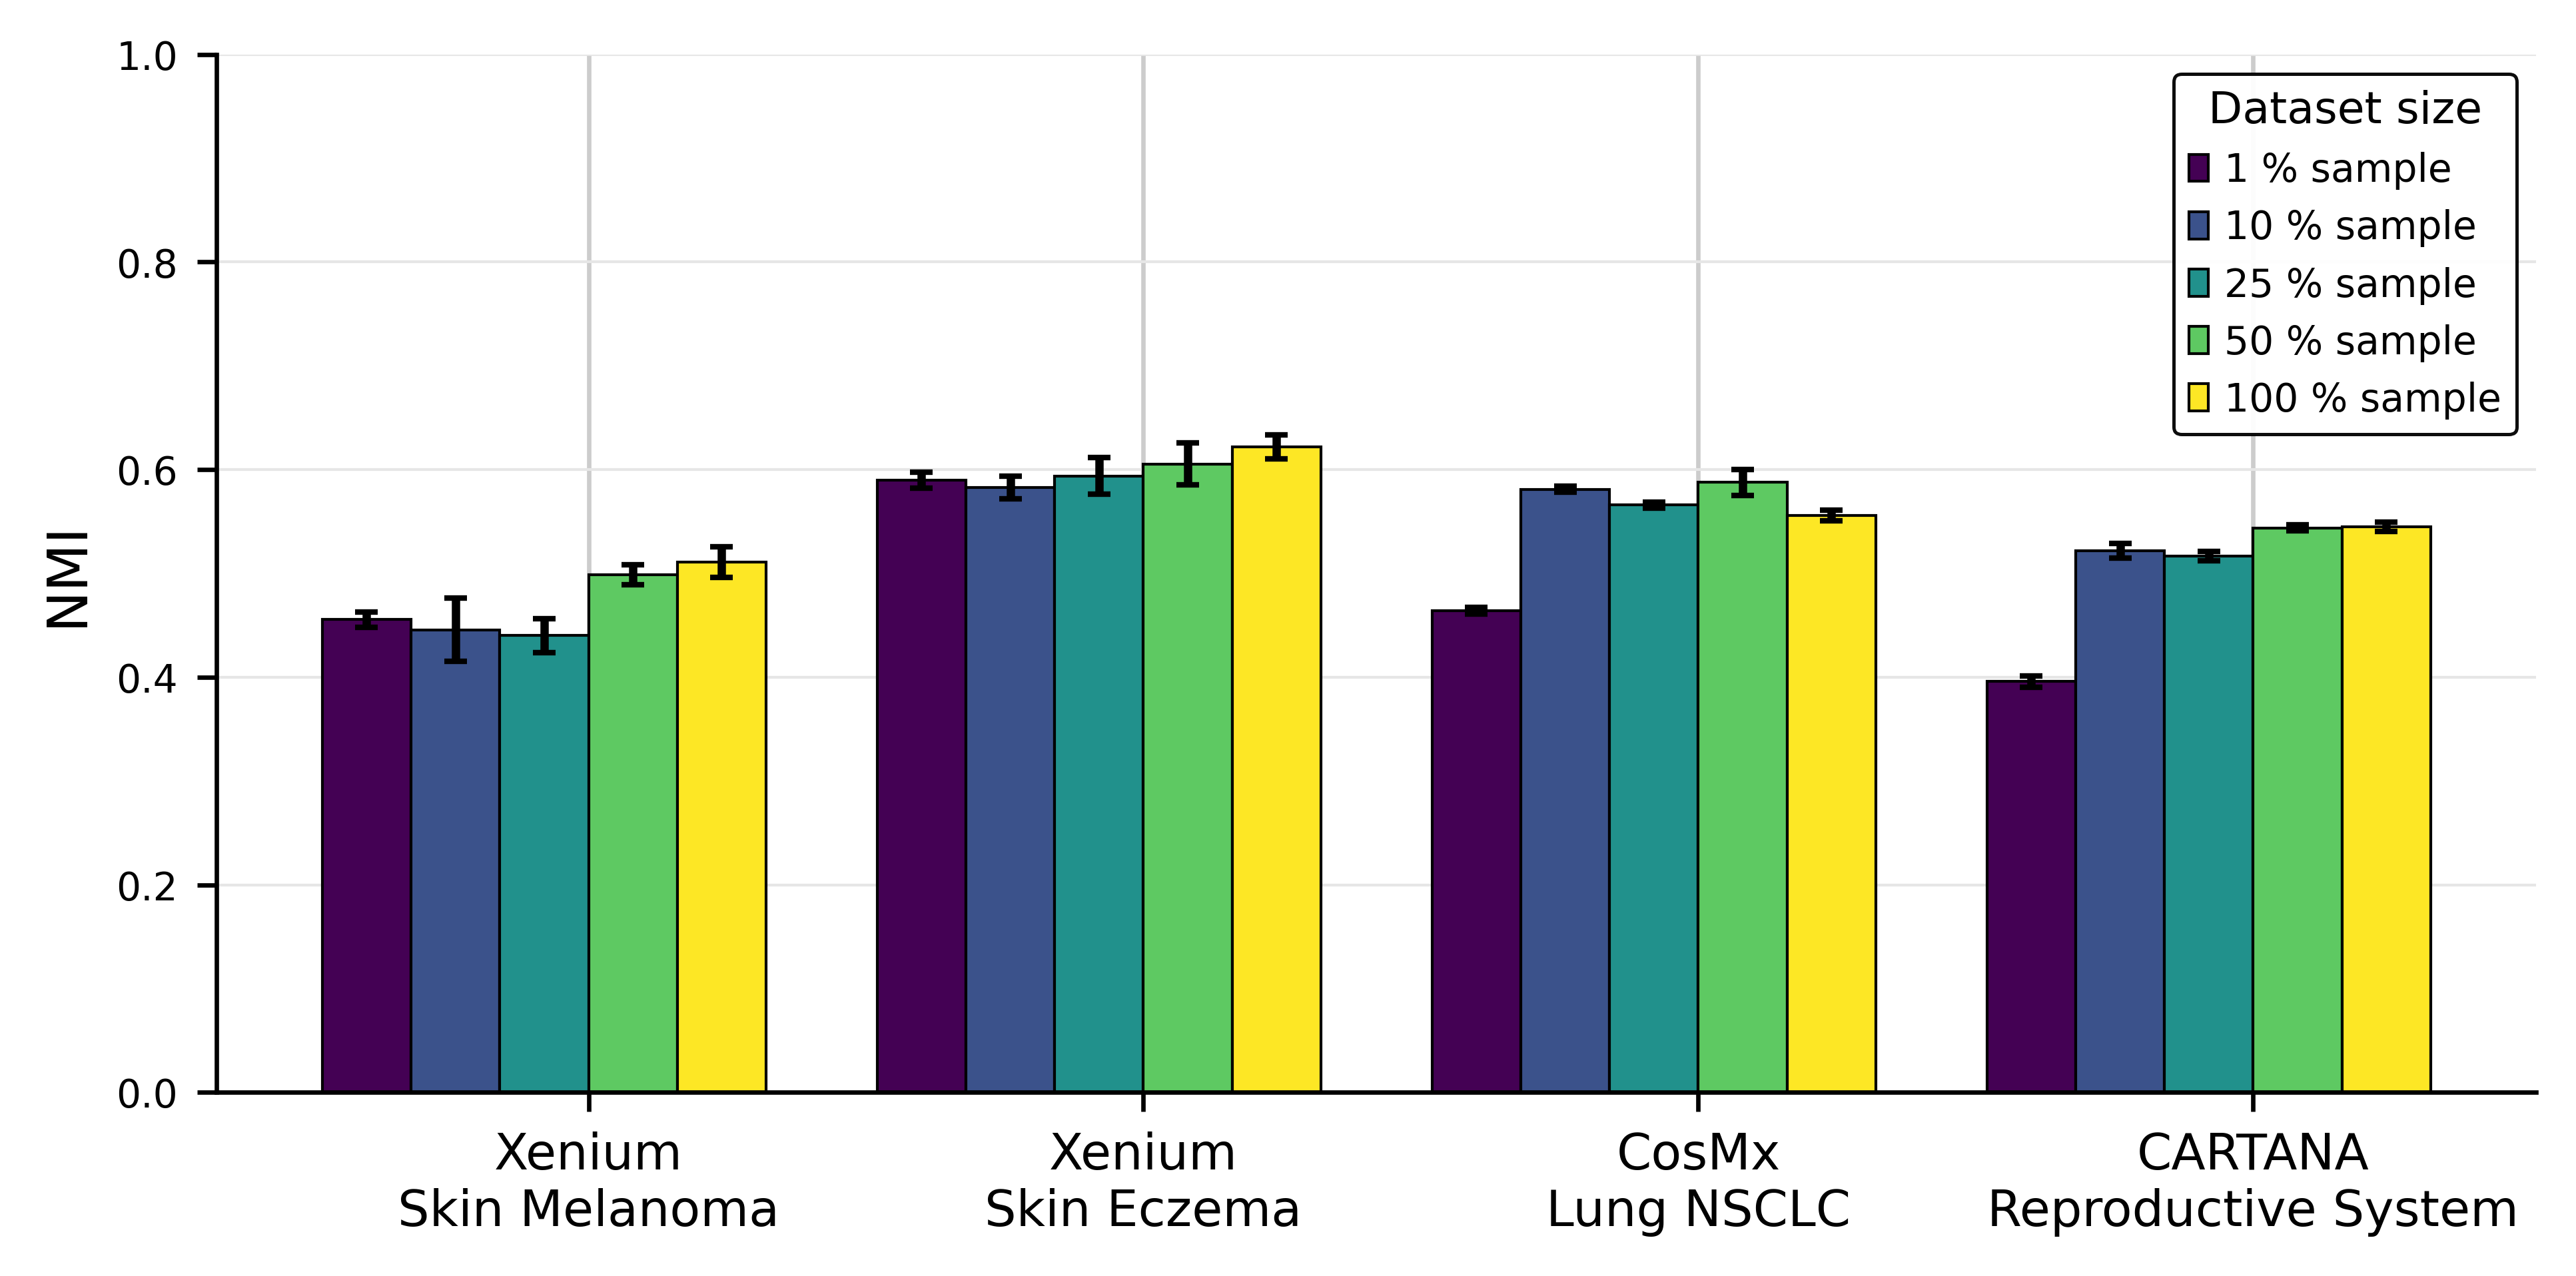

In [371]:
# --- Filter only NMI metric ---
df_nmi = df_neb[df_neb["metric"] == "NMI"]

# --- Compute mean and std per dataset × config ---
stats = (
    df_nmi.groupby(["dataset", "config"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)

# --- Enforce dataset order ---
desired_order = [
    "Xenium Skin Melanoma",
    "Xenium Skin Eczema",
    "CosMx Lung NSCLC",
    "CARTANA Reproductive System",
]
stats["dataset"] = pd.Categorical(stats["dataset"], categories=desired_order, ordered=True)
stats = stats.sort_values("dataset").reset_index(drop=True)

# --- Configurations ---
configs = sorted(stats["config"].unique(), key=lambda x: float(x.split("_")[0]))  # e.g. "1_pct_sample" → 1.0
config_labels = [cfg.replace("_", " ").replace("pct", "%").capitalize() for cfg in configs]

# --- Continuous colormap (light→dark gradient) ---
cmap = cm.get_cmap("viridis", len(configs))
colors = [cmap(i) for i in range(len(configs))]

datasets = stats["dataset"].unique()
bar_width = 0.8 / len(configs)  # keep bars compact
x = range(len(datasets))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=300)

# --- Plot bars for each configuration ---
for i, cfg in enumerate(configs):
    subset = stats[stats["config"] == cfg]
    ax.bar(
        [xi + (i - len(configs)/2) * bar_width for xi in x],
        subset["mean"],
        yerr=subset["std"],
        width=bar_width,
        label=config_labels[i],
        color=colors[i],
        edgecolor="black",
        linewidth=0.5,
        capsize=2,
    )

# --- Wrap labels after the first word ---
def wrap_after_first_word(label):
    label = str(label)
    parts = label.split(" ", 1)
    return "\n".join(parts) if len(parts) > 1 else label

wrapped_labels = [wrap_after_first_word(ds) for ds in datasets]
ax.set_xticks(x)
ax.set_xticklabels(wrapped_labels, fontsize=9, ha="center")

# --- Aesthetics ---
ax.set_ylabel("NMI", fontsize=10)
ax.set_ylim(0, 1.0)

# --- Legend with colormap box ---
legend = ax.legend(
    frameon=True,
    fontsize=7,
    loc="upper right",
    framealpha=0.95,
    fancybox=True,
    edgecolor="black",
    title="Dataset size",
    title_fontsize=8,
)
legend.get_frame().set_linewidth(0.6)

# --- Clean spines and grid ---
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="0.9", linestyle="-", linewidth=0.5)
ax.set_axisbelow(True)

# --- Save figure ---
save_path = os.path.join(sc.settings.figdir, "dataset_size_niche_nmi_comparison.svg")
plt.savefig(save_path, bbox_inches="tight", format="svg")
print(f"✅ Figure saved to: {save_path}")

plt.tight_layout()
plt.show()

/tmp/ipykernel_3221656/1503479021.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("viridis", len(configs))


✅ Figure saved to: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/ablation/figures/dataset_size_niche_ari_comparison.svg


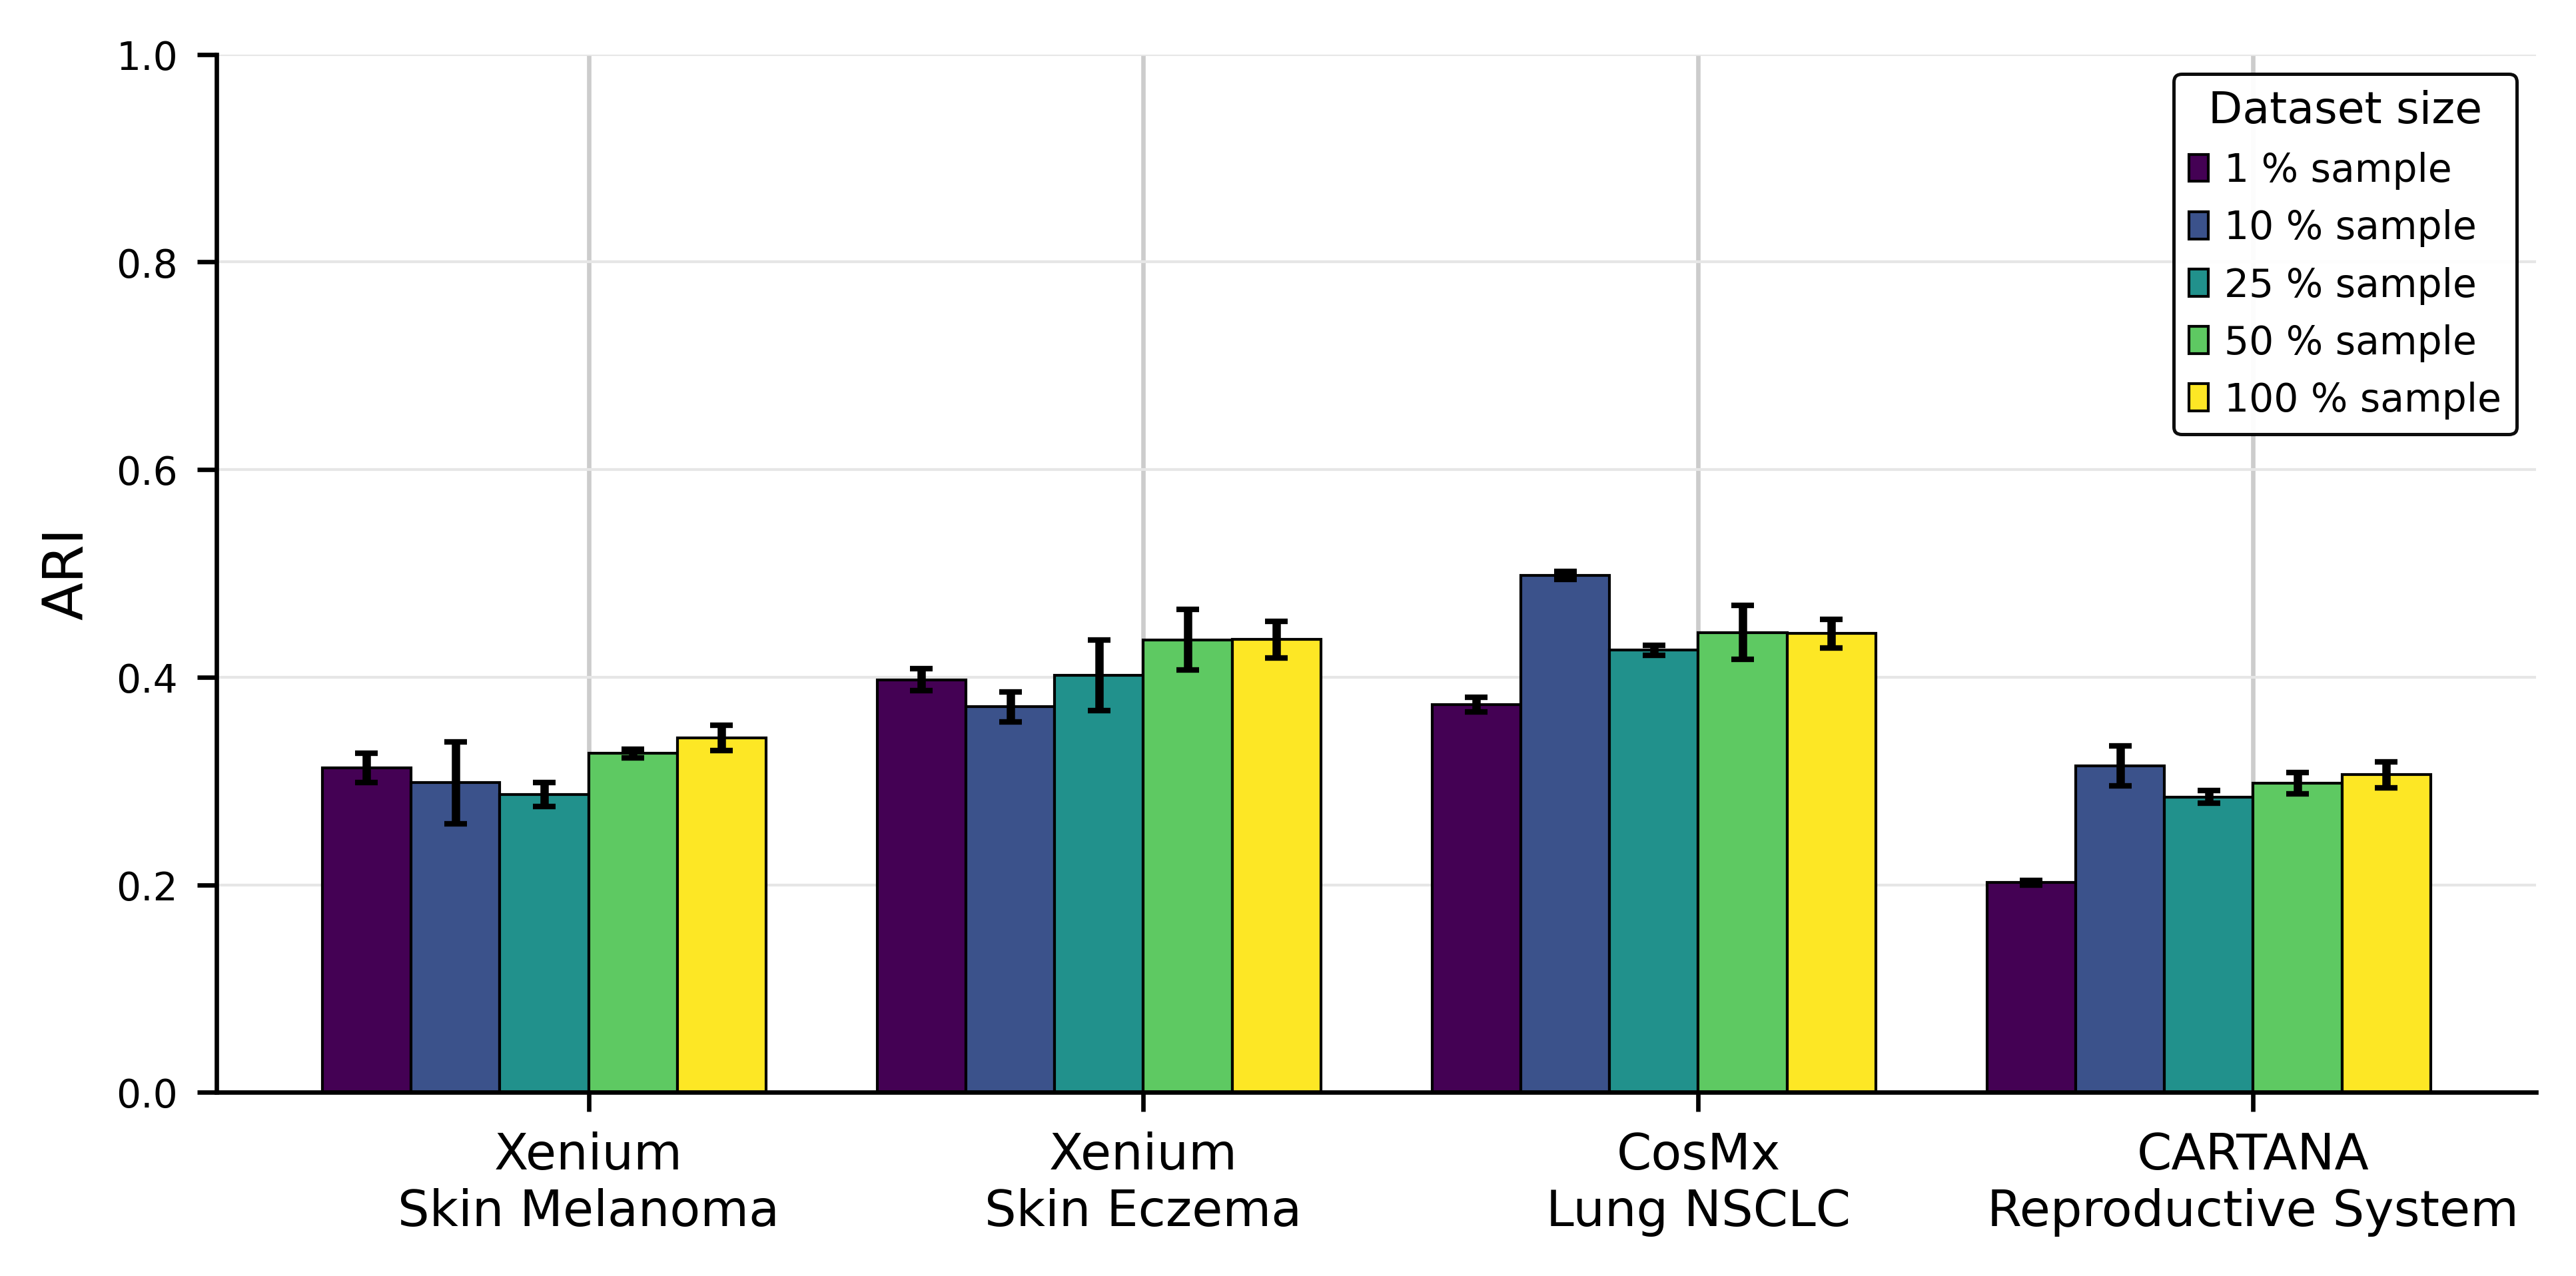

In [372]:
# --- Filter only ARI metric ---
df_ari = df_neb[df_neb["metric"] == "ARI"]

# --- Compute mean and std per dataset × config ---
stats = (
    df_ari.groupby(["dataset", "config"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)

# --- Enforce dataset order ---
desired_order = [
    "Xenium Skin Melanoma",
    "Xenium Skin Eczema",
    "CosMx Lung NSCLC",
    "CARTANA Reproductive System",
]
stats["dataset"] = pd.Categorical(stats["dataset"], categories=desired_order, ordered=True)
stats = stats.sort_values("dataset").reset_index(drop=True)

# --- Configurations ---
configs = sorted(stats["config"].unique(), key=lambda x: float(x.split("_")[0]))  # e.g. "1_pct_sample" → 1.0
config_labels = [cfg.replace("_", " ").replace("pct", "%").capitalize() for cfg in configs]

# --- Continuous colormap (light→dark gradient) ---
cmap = cm.get_cmap("viridis", len(configs))
colors = [cmap(i) for i in range(len(configs))]

datasets = stats["dataset"].unique()
bar_width = 0.8 / len(configs)  # keep bars compact
x = range(len(datasets))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=300)

# --- Plot bars for each configuration ---
for i, cfg in enumerate(configs):
    subset = stats[stats["config"] == cfg]
    ax.bar(
        [xi + (i - len(configs)/2) * bar_width for xi in x],
        subset["mean"],
        yerr=subset["std"],
        width=bar_width,
        label=config_labels[i],
        color=colors[i],
        edgecolor="black",
        linewidth=0.5,
        capsize=2,
    )

# --- Wrap labels after the first word ---
def wrap_after_first_word(label):
    label = str(label)
    parts = label.split(" ", 1)
    return "\n".join(parts) if len(parts) > 1 else label

wrapped_labels = [wrap_after_first_word(ds) for ds in datasets]
ax.set_xticks(x)
ax.set_xticklabels(wrapped_labels, fontsize=9, ha="center")

# --- Aesthetics ---
ax.set_ylabel("ARI", fontsize=10)
ax.set_ylim(0, 1.0)

# --- Legend with colormap box ---
legend = ax.legend(
    frameon=True,
    fontsize=7,
    loc="upper right",
    framealpha=0.95,
    fancybox=True,
    edgecolor="black",
    title="Dataset size",
    title_fontsize=8,
)
legend.get_frame().set_linewidth(0.6)

# --- Clean spines and grid ---
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="0.9", linestyle="-", linewidth=0.5)
ax.set_axisbelow(True)

# --- Save figure ---
save_path = os.path.join(sc.settings.figdir, "dataset_size_niche_ari_comparison.svg")
plt.savefig(save_path, bbox_inches="tight", format="svg")
print(f"✅ Figure saved to: {save_path}")

plt.tight_layout()
plt.show()

/tmp/ipykernel_3221656/3083299534.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("viridis", len(configs))


✅ Figure saved to: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/ablation/figures/dataset_size_cell_type_nmi_comparison.svg


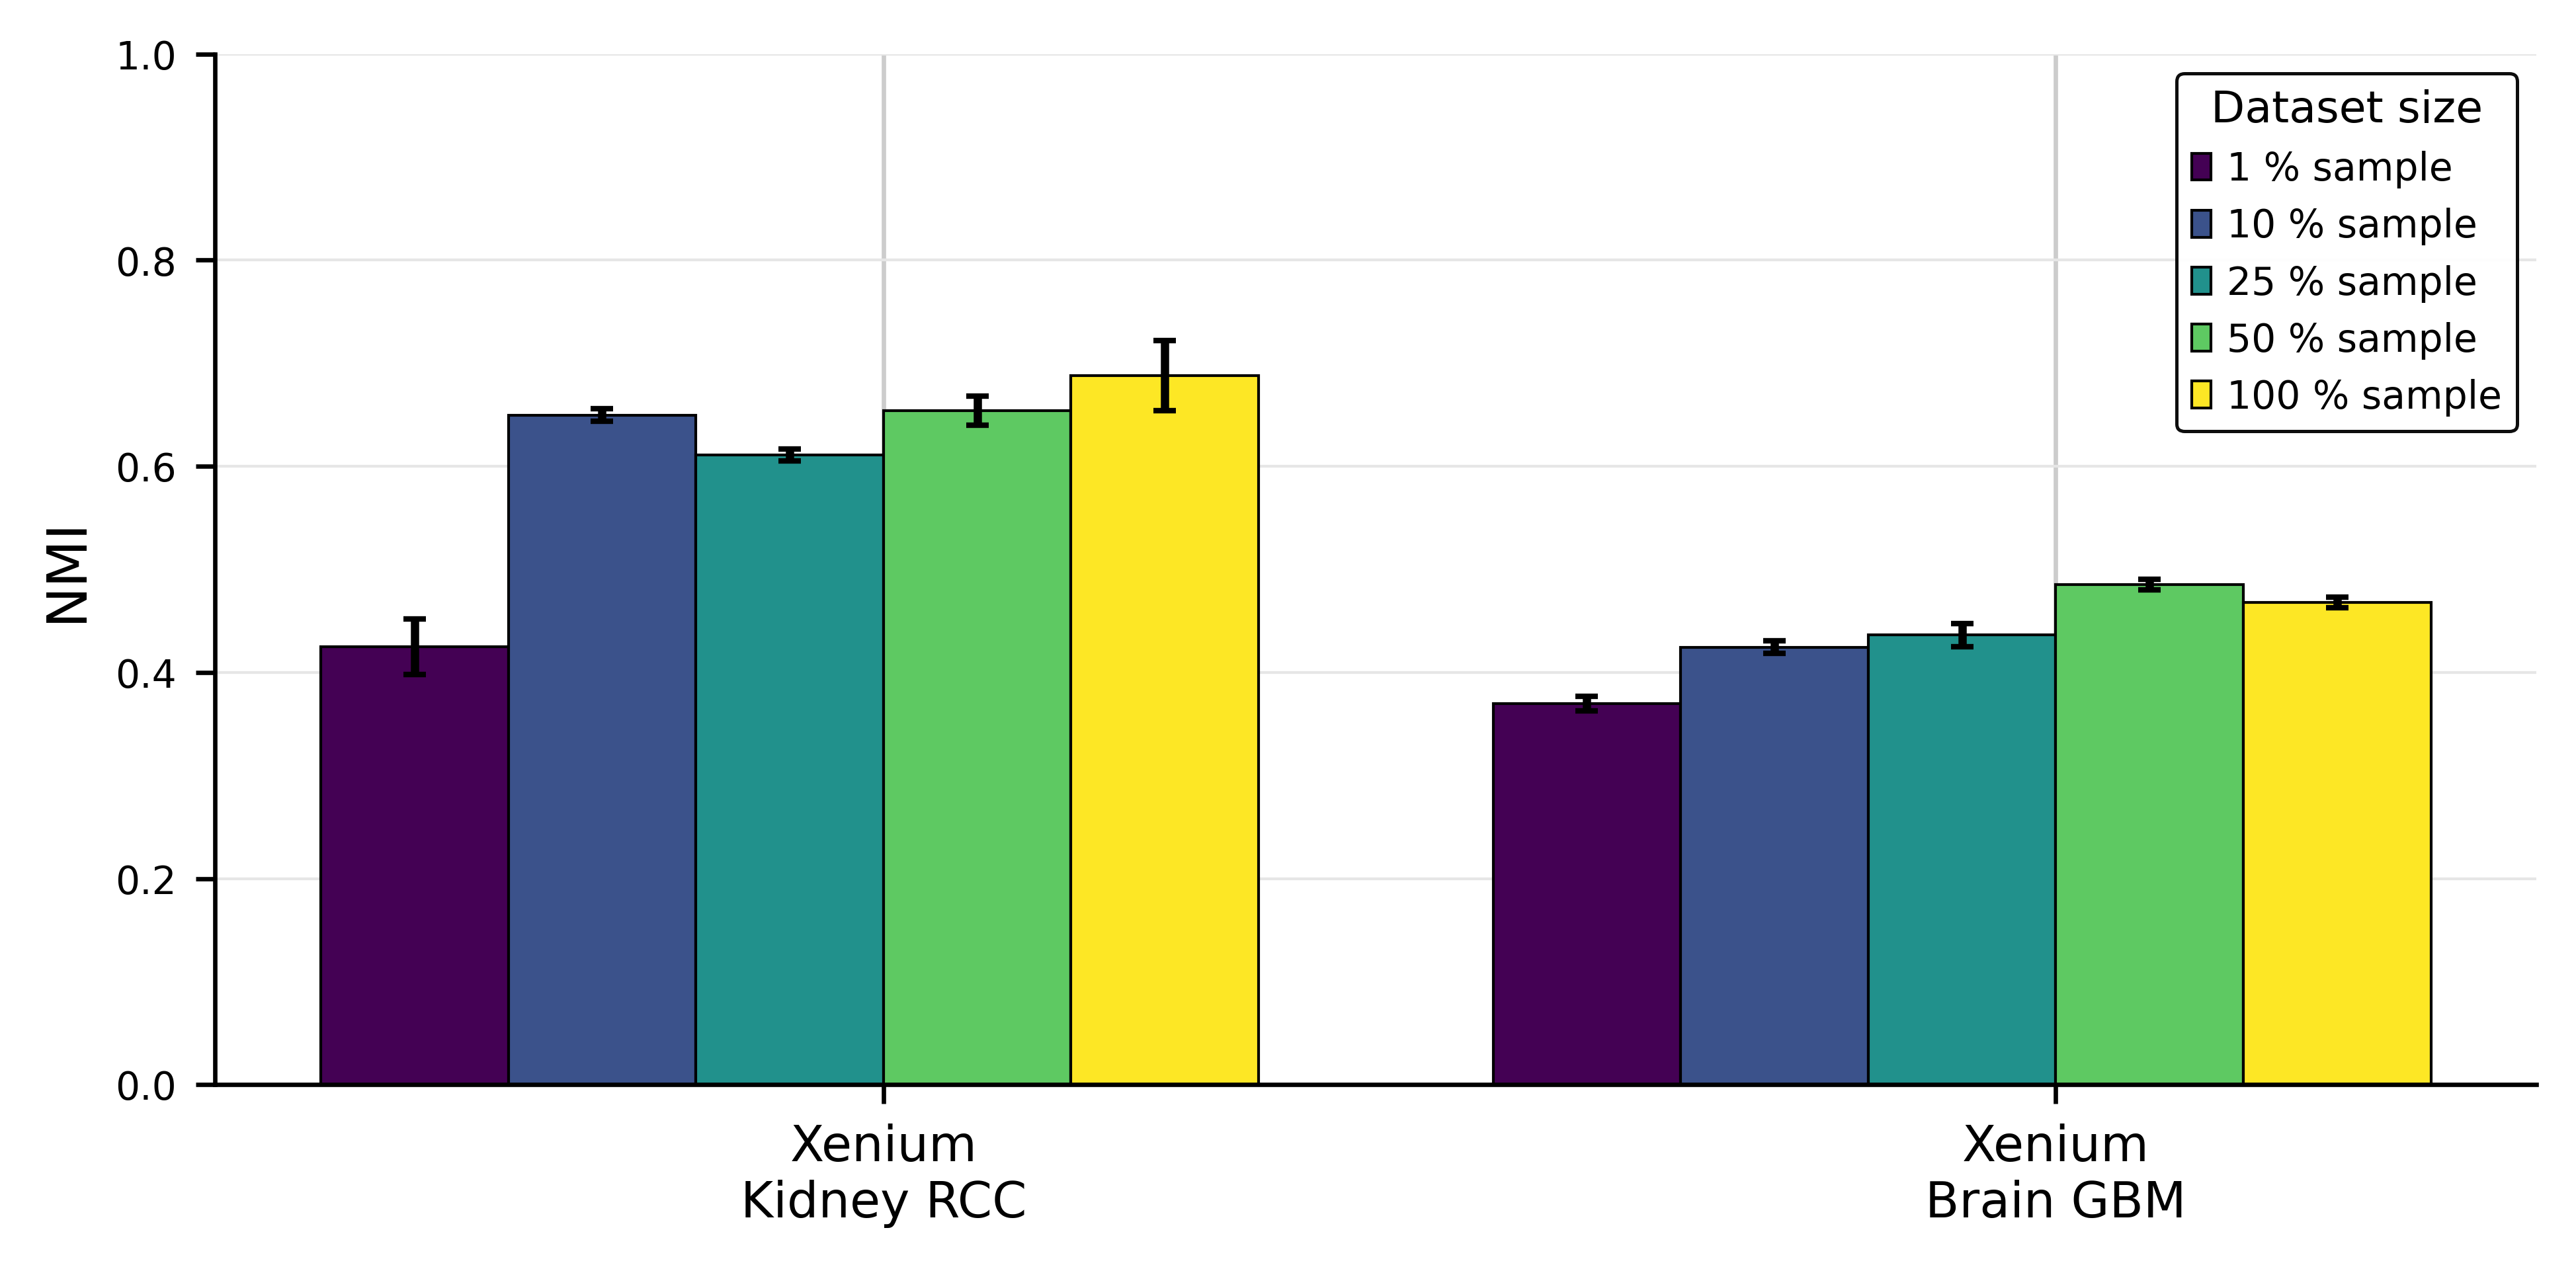

In [124]:
# --- Filter only NMI metric ---
df_nmi = df_cell[df_cell["metric"] == "NMI"]

# --- Compute mean and std per dataset × config ---
stats = (
    df_nmi.groupby(["dataset", "config"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)

# --- Enforce dataset order ---
desired_order = [
    "Xenium Kidney RCC",
    "Xenium Brain GBM"
]
stats["dataset"] = pd.Categorical(stats["dataset"], categories=desired_order, ordered=True)
stats = stats.sort_values("dataset").reset_index(drop=True)

# --- Configurations ---
configs = sorted(stats["config"].unique(), key=lambda x: float(x.split("_")[0]))  # e.g. "1_pct_sample" → 1.0
config_labels = [cfg.replace("_", " ").replace("pct", "%").capitalize() for cfg in configs]

# --- Continuous colormap (light→dark gradient) ---
cmap = cm.get_cmap("viridis", len(configs))
colors = [cmap(i) for i in range(len(configs))]

datasets = stats["dataset"].unique()
bar_width = 0.8 / len(configs)  # keep bars compact
x = range(len(datasets))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=300)

# --- Plot bars for each configuration ---
for i, cfg in enumerate(configs):
    subset = stats[stats["config"] == cfg]
    ax.bar(
        [xi + (i - len(configs)/2) * bar_width for xi in x],
        subset["mean"],
        yerr=subset["std"],
        width=bar_width,
        label=config_labels[i],
        color=colors[i],
        edgecolor="black",
        linewidth=0.5,
        capsize=2,
    )

# --- Wrap labels after the first word ---
def wrap_after_first_word(label):
    label = str(label)
    parts = label.split(" ", 1)
    return "\n".join(parts) if len(parts) > 1 else label

wrapped_labels = [wrap_after_first_word(ds) for ds in datasets]
ax.set_xticks(x)
ax.set_xticklabels(wrapped_labels, fontsize=9, ha="center")

# --- Aesthetics ---
ax.set_ylabel("NMI", fontsize=10)
ax.set_ylim(0, 1.0)

# --- Legend with colormap box ---
legend = ax.legend(
    frameon=True,
    fontsize=7,
    loc="upper right",
    framealpha=0.95,
    fancybox=True,
    edgecolor="black",
    title="Dataset size",
    title_fontsize=8,
)
legend.get_frame().set_linewidth(0.6)

# --- Clean spines and grid ---
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="0.9", linestyle="-", linewidth=0.5)
ax.set_axisbelow(True)

# --- Save figure ---
save_path = os.path.join(sc.settings.figdir, "dataset_size_cell_type_nmi_comparison.svg")
plt.savefig(save_path, bbox_inches="tight", format="svg")
print(f"✅ Figure saved to: {save_path}")

plt.tight_layout()
plt.show()

/tmp/ipykernel_3221656/1143645957.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("viridis", len(configs))


✅ Figure saved to: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/ablation/figures/dataset_size_cell_type_ari_comparison.svg


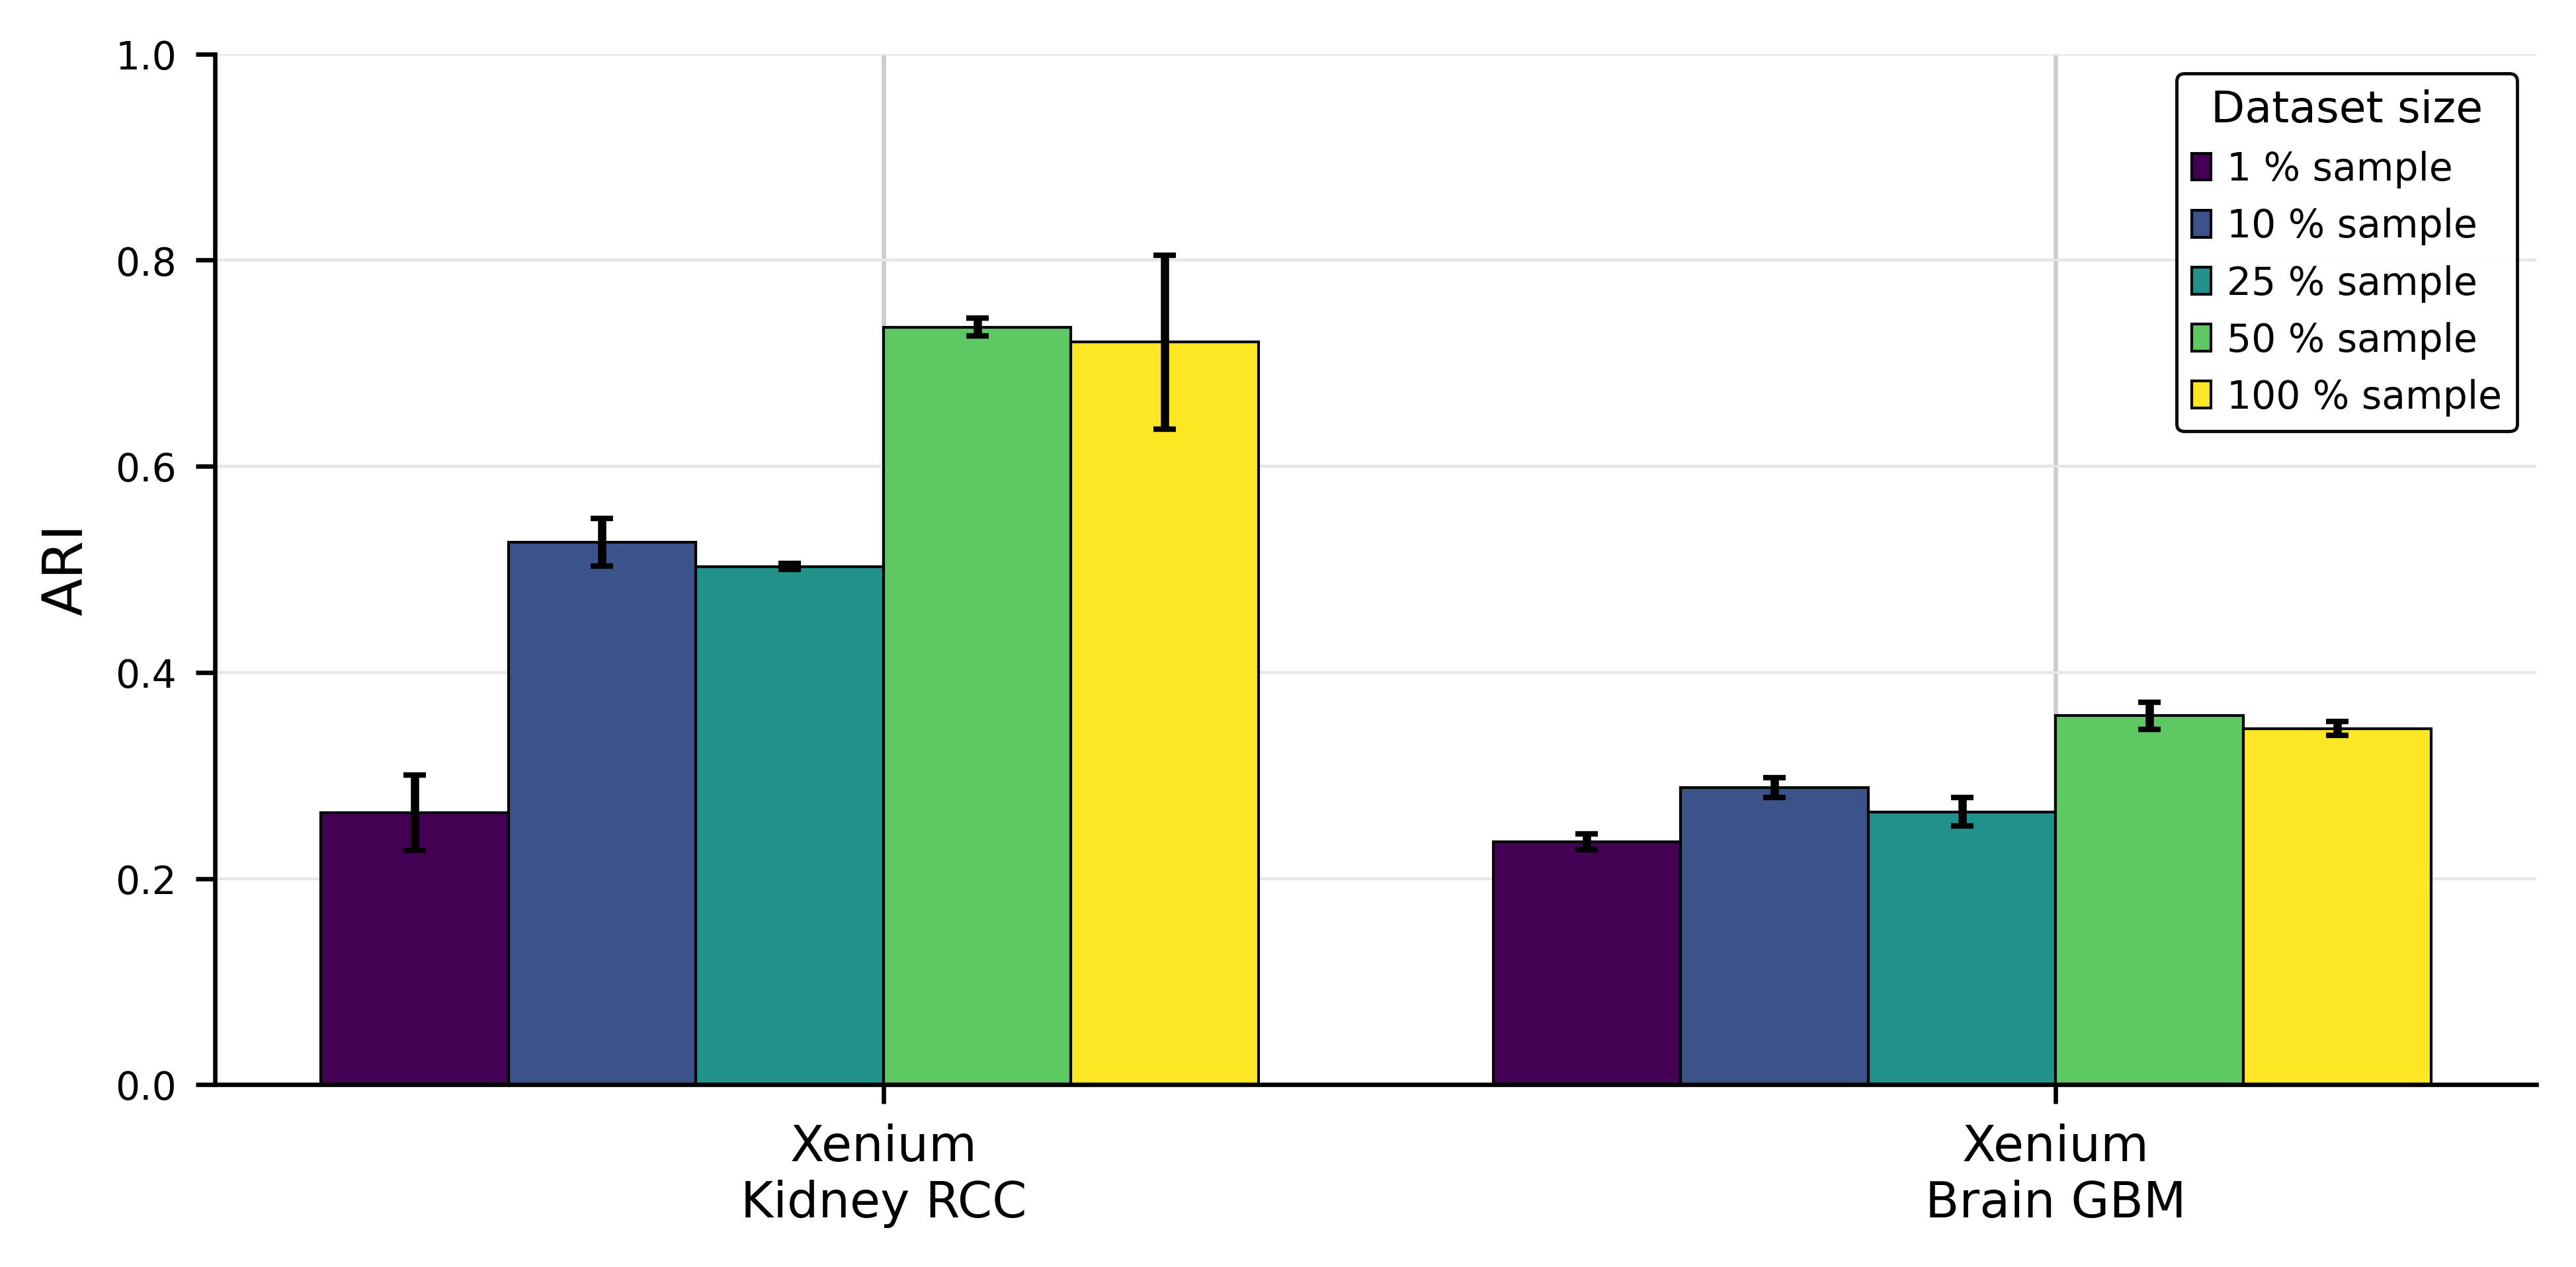

In [125]:
# --- Filter only ARI metric ---
df_ari = df_cell[df_cell["metric"] == "ARI"]

# --- Compute mean and std per dataset × config ---
stats = (
    df_ari.groupby(["dataset", "config"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)

# --- Enforce dataset order ---
desired_order = [
    "Xenium Kidney RCC",
    "Xenium Brain GBM"
]
stats["dataset"] = pd.Categorical(stats["dataset"], categories=desired_order, ordered=True)
stats = stats.sort_values("dataset").reset_index(drop=True)

# --- Configurations ---
configs = sorted(stats["config"].unique(), key=lambda x: float(x.split("_")[0]))  # e.g. "1_pct_sample" → 1.0
config_labels = [cfg.replace("_", " ").replace("pct", "%").capitalize() for cfg in configs]

# --- Continuous colormap (light→dark gradient) ---
cmap = cm.get_cmap("viridis", len(configs))
colors = [cmap(i) for i in range(len(configs))]

datasets = stats["dataset"].unique()
bar_width = 0.8 / len(configs)  # keep bars compact
x = range(len(datasets))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=300)

# --- Plot bars for each configuration ---
for i, cfg in enumerate(configs):
    subset = stats[stats["config"] == cfg]
    ax.bar(
        [xi + (i - len(configs)/2) * bar_width for xi in x],
        subset["mean"],
        yerr=subset["std"],
        width=bar_width,
        label=config_labels[i],
        color=colors[i],
        edgecolor="black",
        linewidth=0.5,
        capsize=2,
    )

# --- Wrap labels after the first word ---
def wrap_after_first_word(label):
    label = str(label)
    parts = label.split(" ", 1)
    return "\n".join(parts) if len(parts) > 1 else label

wrapped_labels = [wrap_after_first_word(ds) for ds in datasets]
ax.set_xticks(x)
ax.set_xticklabels(wrapped_labels, fontsize=9, ha="center")

# --- Aesthetics ---
ax.set_ylabel("ARI", fontsize=10)
ax.set_ylim(0, 1.0)

# --- Legend with colormap box ---
legend = ax.legend(
    frameon=True,
    fontsize=7,
    loc="upper right",
    framealpha=0.95,
    fancybox=True,
    edgecolor="black",
    title="Dataset size",
    title_fontsize=8,
)
legend.get_frame().set_linewidth(0.6)

# --- Clean spines and grid ---
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="0.9", linestyle="-", linewidth=0.5)
ax.set_axisbelow(True)

# --- Save figure ---
save_path = os.path.join(sc.settings.figdir, "dataset_size_cell_type_ari_comparison.svg")
plt.savefig(save_path, bbox_inches="tight", format="svg")
print(f"✅ Figure saved to: {save_path}")

plt.tight_layout()
plt.show()

## 2.3 Masking Ablation

### 2.3.1 xhs49-1b_1p (Xenium Human Skin Melanoma)

In [126]:
# Define dataset config
dataset_name = 'xhs49-1b_1p'
obsm_key = 'neighborhood_emb_layer_12'
label_col = 'niche_name'

#### 2.3.1.1 0.5 Masking Ratio

In [127]:
config_name = '50_pct_masking'
load_timestamp = '02112025_043501_781'
read_checkpoint = 'nichejepa-ep1.pth.tar'
start_latent_leiden_resolution = 0.4

In [128]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 98749 × 0
    obs: 'niche_name', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_28', 'neighborhood_emb_leiden_res0_279', 'neighborhood_emb_leiden_res0_278', 'neighborhood_emb_leiden_res0_277', 'neighborhood_emb_leiden_res0_276', 'neighborhood_emb_leiden_res0_275', 'neighborhood_emb_leiden_res0_274', 'neighborhood_emb_leiden_res0_273', 'neighborhood_emb_leiden_res0_272', 'neighborhood_emb_leiden_res0_271', 'neighborhood_emb_leiden_res0_27', 'neighborhood_emb_leiden_res0_269', 'neighborhood_emb_leiden_res0_268', 'neighborhood_emb_leiden_res0_267', 'neighborhood_emb_leiden_res0_266', 'neighborhood_emb_leiden_res0_265', 'neighborhood_emb_leiden_res0_264', 'neighborhood_emb_leiden_res0_263', 'neighborhood_emb_leiden_res0_262', 'neighborhood_emb_leiden_res0_261', 'neighborhood_emb_leiden_res0_26', 'neighborhood_emb_leiden_res0_259', 'neighborhood_emb_leiden_res0

#### 2.3.1.2 0.6 Masking Ratio

In [129]:
config_name = '60_pct_masking'
load_timestamp = '29102025_142759_837'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [130]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 98749 × 0
    obs: 'niche_name', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_20000000000000004', 'neighborhood_emb_leiden_res0_18000000000000005', 'neighborhood_emb_leiden_res0_16000000000000006', 'neighborhood_emb_leiden_res0_14000000000000007', 'neighborhood_emb_leiden_res0_12000000000000006', 'neighborhood_emb_leiden_res0_11900000000000006'
    uns: 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_11900000000000006', 'neighborhood_emb_leiden_res0_11900000000000006_colors', 'neighborhood_emb_leiden_res0_12000000000000006', 'neighborhood_emb_leiden_res0_14000000000000007', 'neighborhood_emb_leiden_res0_16000000000000006', 'neighborhood_emb_leiden_res0_18000000000000005', 'neighborhood_emb_leiden_res0_20000000000000004', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_4', 'neighborhood_umap', 'niche_name

#### 2.3.1.3 0.7 Masking Ratio

In [131]:
config_name = '70_pct_masking'
load_timestamp = '30102025_112358_100'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [132]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 98749 × 0
    obs: 'niche_name', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_25000000000000006', 'neighborhood_emb_leiden_res0_23000000000000007', 'neighborhood_emb_leiden_res0_21000000000000008', 'neighborhood_emb_leiden_res0_20900000000000007', 'neighborhood_emb_leiden_res0_20800000000000007', 'neighborhood_emb_leiden_res0_20700000000000007', 'neighborhood_emb_leiden_res0_18700000000000008', 'neighborhood_emb_leiden_res0_18600000000000008', 'neighborhood_emb_leiden_res0_18500000000000008', 'neighborhood_emb_leiden_res0_18400000000000008', 'neighborhood_emb_leiden_res0_18300000000000008', 'neighborhood_emb_leiden_res0_18200000000000008', 'neighborhood_emb_leiden_res0_18100000000000008', 'neighborhood_emb_leiden_res0_18000000000000008', 'neighborhood_emb_leiden_res0_17900000000000008', 'neighborhood_emb_leiden_res0_17800000000000007', 'neighborhood_emb_

#### 2.3.1.4 0.8 Masking Ratio

In [133]:
config_name = '80_pct_masking'
load_timestamp = '01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [134]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 98749 × 0
    obs: 'niche_name', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_35000000000000003', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_28', 'neighborhood_emb_leiden_res0_26', 'neighborhood_emb_leiden_res0_259', 'neighborhood_emb_leiden_res0_23900000000000002', 'neighborhood_emb_leiden_res0_23800000000000002', 'neighborhood_emb_leiden_res0_23700000000000002', 'neighborhood_emb_leiden_res0_23600000000000002', 'neighborhood_emb_leiden_res0_23500000000000001', 'neighborhood_emb_leiden_res0_234', 'neighborhood_emb_leiden_res0_233', 'neighborhood_emb_leiden_res0_232', 'neighborhood_emb_leiden_res0_231', 'neighborhood_emb_leiden_res0_23', 'neighborhood_emb_leiden_res0_229', 'neighborhood_emb_leiden_res0_228', 'neighborhood_emb_leiden_res0_227', 'neighborhood_emb_leiden_res0_226', 'neighborhood_emb_leiden_res0_225', 'neighborhood_emb_leiden_res0_224', 'neighborhood_emb

#### 2.3.1.5 0.9 Masking Ratio

In [135]:
config_name = '90_pct_masking'
load_timestamp = '03112025_004451_930'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [136]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 98749 × 0
    obs: 'niche_name', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_35000000000000003', 'neighborhood_emb_leiden_res0_34900000000000003', 'neighborhood_emb_leiden_res0_34800000000000003', 'neighborhood_emb_leiden_res0_34700000000000003', 'neighborhood_emb_leiden_res0_327', 'neighborhood_emb_leiden_res0_326', 'neighborhood_emb_leiden_res0_325', 'neighborhood_emb_leiden_res0_324', 'neighborhood_emb_leiden_res0_323', 'neighborhood_emb_leiden_res0_322', 'neighborhood_emb_leiden_res0_321', 'neighborhood_emb_leiden_res0_301', 'neighborhood_emb_leiden_res0_3', 'neighborhood_emb_leiden_res0_299', 'neighborhood_emb_leiden_res0_298', 'neighborhood_emb_leiden_res0_297', 'neighborhood_emb_leiden_res0_296', 'neighborhood_emb_leiden_res0_295', 'neighborhood_emb_leiden_res0_294', 'neighborhood_emb_leiden_res0_293', 'neighborhood_emb_leiden_res0_292', 'neighborhood_emb_leiden_res0_291', 'neighborhood_emb_leid

### 2.3.2 xhs1000-39b_1p (Xenium Human Skin Eczema)

In [148]:
# Define dataset config
dataset_name = 'xhs1000-39b_1p'
obsm_key = 'neighborhood_emb_layer_12'
label_col = 'niche_type'

#### 2.3.2.1 0.5 Masking Ratio

In [149]:
config_name = '50_pct_masking'
load_timestamp = '02112025_043501_781'
read_checkpoint = 'nichejepa-ep1.pth.tar'
start_latent_leiden_resolution = 0.4

In [150]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 53655 × 0
    obs: 'niche_type', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_20000000000000004', 'neighborhood_emb_leiden_res0_15000000000000002', 'neighborhood_emb_leiden_res0_10000000000000002', 'neighborhood_emb_leiden_res0_09900000000000002', 'neighborhood_emb_leiden_res0_09800000000000002', 'neighborhood_emb_leiden_res0_09700000000000002', 'neighborhood_emb_leiden_res0_09600000000000002', 'neighborhood_emb_leiden_res0_09500000000000001', 'neighborhood_emb_leiden_res0_09400000000000001', 'neighborhood_emb_leiden_res0_09300000000000001', 'neighborhood_emb_leiden_res0_09200000000000001', 'neighborhood_emb_leiden_res0_09100000000000001'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_09100000000000001', 'neighborhood_emb_leiden_res0_09100000000000001_colors', 'neighborhood_emb_leiden_res0_09200000000000001', 

#### 2.3.2.2 0.6 Masking Ratio

In [151]:
config_name = '60_pct_masking'
load_timestamp = '29102025_142759_837'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [152]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 53655 × 0
    obs: 'niche_type', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_20000000000000004', 'neighborhood_emb_leiden_res0_10000000000000003', 'neighborhood_emb_leiden_res0_08000000000000003', 'neighborhood_emb_leiden_res0_07900000000000003', 'neighborhood_emb_leiden_res0_07800000000000003', 'neighborhood_emb_leiden_res0_07700000000000003'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_07700000000000003', 'neighborhood_emb_leiden_res0_07700000000000003_colors', 'neighborhood_emb_leiden_res0_07800000000000003', 'neighborhood_emb_leiden_res0_07900000000000003', 'neighborhood_emb_leiden_res0_08000000000000003', 'neighborhood_emb_leiden_res0_10000000000000003', 'neighborhood_emb_leiden_res0_20000000000000004', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_4', 'neighborhood_um

#### 2.3.2.3 0.7 Masking Ratio

In [153]:
config_name = '70_pct_masking'
load_timestamp = '30102025_112358_100'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [154]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 53655 × 0
    obs: 'niche_type', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_20000000000000004', 'neighborhood_emb_leiden_res0_15000000000000002', 'neighborhood_emb_leiden_res0_10000000000000002', 'neighborhood_emb_leiden_res0_08000000000000002', 'neighborhood_emb_leiden_res0_07900000000000001', 'neighborhood_emb_leiden_res0_07800000000000001', 'neighborhood_emb_leiden_res0_07700000000000001', 'neighborhood_emb_leiden_res0_07600000000000001', 'neighborhood_emb_leiden_res0_07500000000000001'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_07500000000000001', 'neighborhood_emb_leiden_res0_07500000000000001_colors', 'neighborhood_emb_leiden_res0_07600000000000001', 'neighborhood_emb_leiden_res0_07700000000000001', 'neighborhood_emb_leiden_res0_07800000000000001', 'neighborhood_emb_leiden_res0_07900000000000001', 

#### 2.3.2.4 0.8 Masking Ratio

In [155]:
config_name = '80_pct_masking'
load_timestamp = '01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [156]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 53655 × 0
    obs: 'niche_type', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_20000000000000004', 'neighborhood_emb_leiden_res0_10000000000000003', 'neighborhood_emb_leiden_res0_08000000000000003', 'neighborhood_emb_leiden_res0_07900000000000003', 'neighborhood_emb_leiden_res0_07800000000000003', 'neighborhood_emb_leiden_res0_07700000000000003'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_07700000000000003', 'neighborhood_emb_leiden_res0_07700000000000003_colors', 'neighborhood_emb_leiden_res0_07800000000000003', 'neighborhood_emb_leiden_res0_07900000000000003', 'neighborhood_emb_leiden_res0_08000000000000003', 'neighborhood_emb_leiden_res0_10000000000000003', 'neighborhood_emb_leiden_res0_20000000000000004', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_4', 'neighborhood_um

#### 2.3.2.5 0.9 Masking Ratio

In [157]:
config_name = '90_pct_masking'
load_timestamp = '03112025_004451_930'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [158]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 53655 × 0
    obs: 'niche_type', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_30000000000000004', 'neighborhood_emb_leiden_res0_20000000000000004', 'neighborhood_emb_leiden_res0_15000000000000002', 'neighborhood_emb_leiden_res0_14900000000000002', 'neighborhood_emb_leiden_res0_14800000000000002', 'neighborhood_emb_leiden_res0_14700000000000002', 'neighborhood_emb_leiden_res0_14600000000000002', 'neighborhood_emb_leiden_res0_14500000000000002', 'neighborhood_emb_leiden_res0_14400000000000002', 'neighborhood_emb_leiden_res0_14300000000000002', 'neighborhood_emb_leiden_res0_14200000000000002', 'neighborhood_emb_leiden_res0_14100000000000001', 'neighborhood_emb_leiden_res0_14'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_14', 'neighborhood_emb_leiden_res0_14100000000000001', 'neighborhood_emb_leiden_res0_14200000000000002', 'neighborhood_emb_leiden_res0_1430000

### 2.3.3 xhk1007-41b_1p (Xenium Human Kidney RCC)

In [289]:
# Define dataset config
dataset_name = 'xhk1007-41b_1p'
obsm_key = 'cell_emb_layer_12'
label_col = 'level_1_cell_type'

#### 2.3.3.1 0.5 Masking Ratio

In [160]:
config_name = '50_pct_masking'
load_timestamp = '02112025_043501_781'
read_checkpoint = 'nichejepa-ep1.pth.tar'
start_latent_leiden_resolution = 0.4

In [161]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 135746 × 0
    obs: 'level_1_cell_type', 'gene_panel_size', 'batch', 'cell_emb_leiden_res0_75', 'cell_emb_leiden_res0_65', 'cell_emb_leiden_res0_55', 'cell_emb_leiden_res0_5', 'cell_emb_leiden_res0_45', 'cell_emb_leiden_res0_4', 'cell_emb_leiden_res0_35000000000000003', 'cell_emb_leiden_res0_30000000000000004', 'cell_emb_leiden_res0_25000000000000006', 'cell_emb_leiden_res0_23000000000000007', 'cell_emb_leiden_res0_21000000000000008', 'cell_emb_leiden_res0_20900000000000007', 'cell_emb_leiden_res0_20800000000000007', 'cell_emb_leiden_res0_20700000000000007', 'cell_emb_leiden_res0_20600000000000007', 'cell_emb_leiden_res0_20500000000000007', 'cell_emb_leiden_res0_20400000000000007', 'cell_emb_leiden_res0_20300000000000007', 'cell_emb_leiden_res0_20200000000000007', 'cell_emb_leiden_res0_20100000000000007', 'cell_emb_leiden_res0_20000000000000007', 'cell_emb_leiden_res0_19900000000000007', 'cell_emb_leiden_res0_19800000000000006', 'cell_emb_leiden_res

#### 2.3.3.2 0.6 Masking Ratio

In [290]:
config_name = '60_pct_masking'
load_timestamp = '29102025_142759_837'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [291]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 135746 × 0
    obs: 'level_1_cell_type', 'gene_panel_size', 'batch', 'cell_emb_leiden_res0_75', 'cell_emb_leiden_res0_65', 'cell_emb_leiden_res0_55', 'cell_emb_leiden_res0_45000000000000007', 'cell_emb_leiden_res0_4000000000000001', 'cell_emb_leiden_res0_3500000000000001', 'cell_emb_leiden_res0_3000000000000001', 'cell_emb_leiden_res0_2500000000000001', 'cell_emb_leiden_res0_23000000000000012', 'cell_emb_leiden_res0_21000000000000013', 'cell_emb_leiden_res0_19000000000000014', 'cell_emb_leiden_res0_17000000000000015', 'cell_emb_leiden_res0_15000000000000016', 'cell_emb_leiden_res0_14900000000000016', 'cell_emb_leiden_res0_14800000000000016', 'cell_emb_leiden_res0_14700000000000016', 'cell_emb_leiden_res0_14600000000000016', 'cell_emb_leiden_res0_14500000000000016', 'cell_emb_leiden_res0_14400000000000016', 'cell_emb_leiden_res0_14300000000000015', 'cell_emb_leiden_res0_14200000000000015', 'cell_emb_leiden_res0_14100000000000015', 'cell_emb_leiden_re

#### 2.3.3.3 0.7 Masking Ratio

In [167]:
config_name = '70_pct_masking'
load_timestamp = '30102025_112358_100'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [168]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 135746 × 0
    obs: 'level_1_cell_type', 'gene_panel_size', 'batch', 'cell_emb_leiden_res0_75', 'cell_emb_leiden_res0_65', 'cell_emb_leiden_res0_55', 'cell_emb_leiden_res0_45000000000000007', 'cell_emb_leiden_res0_3500000000000001', 'cell_emb_leiden_res0_33000000000000007', 'cell_emb_leiden_res0_31000000000000005', 'cell_emb_leiden_res0_30900000000000005', 'cell_emb_leiden_res0_30800000000000005', 'cell_emb_leiden_res0_30700000000000005', 'cell_emb_leiden_res0_30600000000000005', 'cell_emb_leiden_res0_30500000000000005', 'cell_emb_leiden_res0_30400000000000005', 'cell_emb_leiden_res0_30300000000000005', 'cell_emb_leiden_res0_30200000000000005', 'cell_emb_leiden_res0_30100000000000005', 'cell_emb_leiden_res0_30000000000000004', 'cell_emb_leiden_res0_29900000000000004', 'cell_emb_leiden_res0_29800000000000004', 'cell_emb_leiden_res0_29700000000000004', 'cell_emb_leiden_res0_29600000000000004', 'cell_emb_leiden_res0_29500000000000004', 'cell_emb_leiden

#### 2.3.3.4 0.8 Masking Ratio

In [169]:
config_name = '80_pct_masking'
load_timestamp = '01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [170]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 135746 × 0
    obs: 'level_1_cell_type', 'gene_panel_size', 'batch', 'cell_emb_leiden_res0_75', 'cell_emb_leiden_res0_65', 'cell_emb_leiden_res0_6', 'cell_emb_leiden_res0_5499999999999999', 'cell_emb_leiden_res0_49999999999999994', 'cell_emb_leiden_res0_44999999999999996', 'cell_emb_leiden_res0_39999999999999997', 'cell_emb_leiden_res0_37999999999999995', 'cell_emb_leiden_res0_35999999999999993', 'cell_emb_leiden_res0_3399999999999999', 'cell_emb_leiden_res0_3199999999999999', 'cell_emb_leiden_res0_2999999999999999', 'cell_emb_leiden_res0_27999999999999986', 'cell_emb_leiden_res0_27899999999999986', 'cell_emb_leiden_res0_27799999999999986', 'cell_emb_leiden_res0_27699999999999986', 'cell_emb_leiden_res0_27599999999999986', 'cell_emb_leiden_res0_25599999999999984', 'cell_emb_leiden_res0_25499999999999984', 'cell_emb_leiden_res0_25399999999999984', 'cell_emb_leiden_res0_25299999999999984', 'cell_emb_leiden_res0_25199999999999984', 'cell_emb_leiden_res

#### 2.3.3.5 0.9 Masking Ratio

In [171]:
config_name = '90_pct_masking'
load_timestamp = '03112025_004451_930'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [172]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 135746 × 0
    obs: 'level_1_cell_type', 'gene_panel_size', 'batch', 'cell_emb_leiden_res0_75', 'cell_emb_leiden_res0_7', 'cell_emb_leiden_res0_6499999999999999', 'cell_emb_leiden_res0_5999999999999999', 'cell_emb_leiden_res0_5499999999999998', 'cell_emb_leiden_res0_49999999999999983', 'cell_emb_leiden_res0_44999999999999984', 'cell_emb_leiden_res0_39999999999999986', 'cell_emb_leiden_res0_34999999999999987', 'cell_emb_leiden_res0_34899999999999987', 'cell_emb_leiden_res0_32899999999999985', 'cell_emb_leiden_res0_30899999999999983', 'cell_emb_leiden_res0_30799999999999983', 'cell_emb_leiden_res0_30699999999999983', 'cell_emb_leiden_res0_2869999999999998', 'cell_emb_leiden_res0_2859999999999998', 'cell_emb_leiden_res0_2849999999999998', 'cell_emb_leiden_res0_2839999999999998', 'cell_emb_leiden_res0_2829999999999998', 'cell_emb_leiden_res0_2819999999999998', 'cell_emb_leiden_res0_2809999999999998', 'cell_emb_leiden_res0_2799999999999998', 'cell_emb_le

### 2.3.4 xhb1002-75b_3p (Xenium Human Brain GBM)

In [173]:
# Define dataset config
dataset_name = 'xhb1002-75b_3p'
obsm_key = 'cell_emb_layer_12'
label_col = 'leiden_log1pnorm_res-1'

#### 2.3.4.1 0.5 Masking Ratio

In [174]:
config_name = '50_pct_masking'
load_timestamp = '02112025_043501_781'
read_checkpoint = 'nichejepa-ep1.pth.tar'
start_latent_leiden_resolution = 0.4

In [175]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 243416 × 0
    obs: 'leiden_log1pnorm_res-1', 'gene_panel_size', 'batch', 'cell_emb_leiden_res1_0', 'cell_emb_leiden_res0_98', 'cell_emb_leiden_res0_96', 'cell_emb_leiden_res0_94', 'cell_emb_leiden_res0_9199999999999999', 'cell_emb_leiden_res0_8999999999999999', 'cell_emb_leiden_res0_8799999999999999', 'cell_emb_leiden_res0_8599999999999999', 'cell_emb_leiden_res0_8399999999999999', 'cell_emb_leiden_res0_8199999999999998', 'cell_emb_leiden_res0_8189999999999998', 'cell_emb_leiden_res0_8179999999999998', 'cell_emb_leiden_res0_8169999999999998', 'cell_emb_leiden_res0_8159999999999998', 'cell_emb_leiden_res0_8149999999999998', 'cell_emb_leiden_res0_8139999999999998', 'cell_emb_leiden_res0_8129999999999998', 'cell_emb_leiden_res0_8119999999999998', 'cell_emb_leiden_res0_8109999999999998', 'cell_emb_leiden_res0_8099999999999998', 'cell_emb_leiden_res0_8089999999999998', 'cell_emb_leiden_res0_7889999999999998', 'cell_emb_leiden_res0_7879999999999998', 'ce

#### 2.3.4.2 0.6 Masking Ratio

In [176]:
config_name = '60_pct_masking'
load_timestamp = '29102025_142759_837'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [177]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 243416 × 0
    obs: 'leiden_log1pnorm_res-1', 'gene_panel_size', 'batch', 'cell_emb_leiden_res1_0', 'cell_emb_leiden_res0_98', 'cell_emb_leiden_res0_96', 'cell_emb_leiden_res0_9099999999999999', 'cell_emb_leiden_res0_8899999999999999', 'cell_emb_leiden_res0_8889999999999999', 'cell_emb_leiden_res0_8879999999999999', 'cell_emb_leiden_res0_8869999999999999', 'cell_emb_leiden_res0_8669999999999999', 'cell_emb_leiden_res0_8659999999999999', 'cell_emb_leiden_res0_8649999999999999', 'cell_emb_leiden_res0_8639999999999999', 'cell_emb_leiden_res0_8629999999999999', 'cell_emb_leiden_res0_8619999999999999', 'cell_emb_leiden_res0_8609999999999999', 'cell_emb_leiden_res0_8599999999999999', 'cell_emb_leiden_res0_8589999999999999', 'cell_emb_leiden_res0_8579999999999999', 'cell_emb_leiden_res0_8569999999999999', 'cell_emb_leiden_res0_8559999999999999', 'cell_emb_leiden_res0_8549999999999999', 'cell_emb_leiden_res0_8539999999999999', 'cell_emb_leiden_res0_85299999

#### 2.3.4.3 0.7 Masking Ratio

In [178]:
config_name = '70_pct_masking'
load_timestamp = '30102025_112358_100'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [179]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 243416 × 0
    obs: 'leiden_log1pnorm_res-1', 'gene_panel_size', 'batch', 'cell_emb_leiden_res1_0', 'cell_emb_leiden_res0_999', 'cell_emb_leiden_res0_998', 'cell_emb_leiden_res0_997', 'cell_emb_leiden_res0_996', 'cell_emb_leiden_res0_995', 'cell_emb_leiden_res0_994', 'cell_emb_leiden_res0_993', 'cell_emb_leiden_res0_992', 'cell_emb_leiden_res0_991', 'cell_emb_leiden_res0_99', 'cell_emb_leiden_res0_989', 'cell_emb_leiden_res0_969', 'cell_emb_leiden_res0_968', 'cell_emb_leiden_res0_967', 'cell_emb_leiden_res0_966', 'cell_emb_leiden_res0_965', 'cell_emb_leiden_res0_964', 'cell_emb_leiden_res0_963', 'cell_emb_leiden_res0_962', 'cell_emb_leiden_res0_961', 'cell_emb_leiden_res0_96', 'cell_emb_leiden_res0_959', 'cell_emb_leiden_res0_958', 'cell_emb_leiden_res0_957', 'cell_emb_leiden_res0_956', 'cell_emb_leiden_res0_955', 'cell_emb_leiden_res0_954', 'cell_emb_leiden_res0_953', 'cell_emb_leiden_res0_952', 'cell_emb_leiden_res0_951', 'cell_emb_leiden_res0_95'

#### 2.3.4.4 0.8 Masking Ratio

In [180]:
config_name = '80_pct_masking'
load_timestamp = '01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [181]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 243416 × 0
    obs: 'leiden_log1pnorm_res-1', 'gene_panel_size', 'batch', 'cell_emb_leiden_res1_0', 'cell_emb_leiden_res0_999', 'cell_emb_leiden_res0_998', 'cell_emb_leiden_res0_997', 'cell_emb_leiden_res0_996', 'cell_emb_leiden_res0_995', 'cell_emb_leiden_res0_994', 'cell_emb_leiden_res0_993', 'cell_emb_leiden_res0_992', 'cell_emb_leiden_res0_991', 'cell_emb_leiden_res0_99', 'cell_emb_leiden_res0_989', 'cell_emb_leiden_res0_988', 'cell_emb_leiden_res0_987', 'cell_emb_leiden_res0_967', 'cell_emb_leiden_res0_966', 'cell_emb_leiden_res0_965', 'cell_emb_leiden_res0_945', 'cell_emb_leiden_res0_944', 'cell_emb_leiden_res0_943', 'cell_emb_leiden_res0_942'
    uns: 'cell', 'cell_emb_leiden_res0_942', 'cell_emb_leiden_res0_942_colors', 'cell_emb_leiden_res0_943', 'cell_emb_leiden_res0_944', 'cell_emb_leiden_res0_945', 'cell_emb_leiden_res0_965', 'cell_emb_leiden_res0_966', 'cell_emb_leiden_res0_967', 'cell_emb_leiden_res0_987', 'cell_emb_leiden_res0_988', '

#### 2.3.4.5 0.9 Masking Ratio

In [182]:
config_name = '90_pct_masking'
load_timestamp = '03112025_004451_930'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [183]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 243416 × 0
    obs: 'leiden_log1pnorm_res-1', 'gene_panel_size', 'batch', 'cell_emb_leiden_res1_0', 'cell_emb_leiden_res0_98', 'cell_emb_leiden_res0_979', 'cell_emb_leiden_res0_959', 'cell_emb_leiden_res0_958', 'cell_emb_leiden_res0_957', 'cell_emb_leiden_res0_956', 'cell_emb_leiden_res0_955', 'cell_emb_leiden_res0_954', 'cell_emb_leiden_res0_953', 'cell_emb_leiden_res0_952', 'cell_emb_leiden_res0_951', 'cell_emb_leiden_res0_95', 'cell_emb_leiden_res0_949', 'cell_emb_leiden_res0_9289999999999999', 'cell_emb_leiden_res0_9279999999999999', 'cell_emb_leiden_res0_9269999999999999', 'cell_emb_leiden_res0_9259999999999999', 'cell_emb_leiden_res0_9249999999999999', 'cell_emb_leiden_res0_9239999999999999', 'cell_emb_leiden_res0_9229999999999999', 'cell_emb_leiden_res0_9219999999999999', 'cell_emb_leiden_res0_9209999999999999', 'cell_emb_leiden_res0_9199999999999999', 'cell_emb_leiden_res0_9189999999999999', 'cell_emb_leiden_res0_9179999999999999', 'cell_emb

### 2.3.5 chl59-8b_1p (NanoString CosMx Human Lung NSCLC)

In [311]:
# Define dataset config
dataset_name = 'chl59-8b_1p'
obsm_key = 'neighborhood_emb_layer_12'
label_col = 'niche'

#### 2.3.5.1 0.5 Masking Ratio

In [185]:
config_name = '50_pct_masking'
load_timestamp = '02112025_043501_781'
read_checkpoint = 'nichejepa-ep1.pth.tar'
start_latent_leiden_resolution = 0.4

In [186]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 533961 × 0
    obs: 'niche', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_6'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_6', 'neighborhood_emb_leiden_res0_6_colors', 'neighborhood_umap', 'niche_colors', 'neighborhood_emb_layer_12'
    obsm: 'X_umap', 'cell_emb_layer_12', 'cell_umap', 'neighborhood_emb_layer_12', 'neighborhood_umap', 'spatial'
    obsp: 'cell_connectivities', 'cell_distances', 'neighborhood_connectivities', 'neighborhood_distances'
Target number of unique values: 12.
Leiden resolution: 0.4.
Number of latent clusters 11.
Leiden resolution: 0.401.
Number of latent clusters 10.
Leiden resolution: 0.402.
Number of latent clusters 10.
Leiden resolution: 0.403.
Number of latent clusters 10.
Leiden resolution: 0.404.
Number of latent clusters 8.
Leiden resolution: 0.42400000000000004.
Number of latent clusters 12.
9
12
NMI is 0.5656705534126862. ARI is 0.464392306601913.
10
12
NMI

#### 2.3.5.2 0.6 Masking Ratio

In [308]:
config_name = '60_pct_masking'
load_timestamp = '29102025_142759_837'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [309]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 533961 × 0
    obs: 'niche', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_6', 'neighborhood_emb_leiden_res0_599', 'neighborhood_emb_leiden_res0_598'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_598', 'neighborhood_emb_leiden_res0_598_colors', 'neighborhood_emb_leiden_res0_599', 'neighborhood_emb_leiden_res0_6', 'neighborhood_umap', 'niche_colors', 'neighborhood_emb_layer_12'
    obsm: 'X_umap', 'cell_emb_layer_12', 'cell_umap', 'neighborhood_emb_layer_12', 'neighborhood_umap', 'spatial'
    obsp: 'cell_connectivities', 'cell_distances', 'neighborhood_connectivities', 'neighborhood_distances'
Target number of unique values: 12.
Leiden resolution: 0.4.
Number of latent clusters 13.
Leiden resolution: 0.399.
Number of latent clusters 12.
NMI is 0.5512577504159486. ARI is 0.45115487253166847.
11
12
NMI is 0.5709322106475122. ARI is 0.47886193743175554.
NMI is 0.5554536042016768. ARI is 0.463187

#### 2.3.5.3 0.7 Masking Ratio

In [312]:
config_name = '70_pct_masking'
load_timestamp = '30102025_112358_100'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [313]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 533961 × 0
    obs: 'niche', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_6', 'neighborhood_emb_leiden_res0_599', 'neighborhood_emb_leiden_res0_598', 'neighborhood_emb_leiden_res0_597', 'neighborhood_emb_leiden_res0_596', 'neighborhood_emb_leiden_res0_595', 'neighborhood_emb_leiden_res0_594', 'neighborhood_emb_leiden_res0_593', 'neighborhood_emb_leiden_res0_592', 'neighborhood_emb_leiden_res0_591', 'neighborhood_emb_leiden_res0_59', 'neighborhood_emb_leiden_res0_589', 'neighborhood_emb_leiden_res0_588', 'neighborhood_emb_leiden_res0_587', 'neighborhood_emb_leiden_res0_586', 'neighborhood_emb_leiden_res0_585', 'neighborhood_emb_leiden_res0_584', 'neighborhood_emb_leiden_res0_583', 'neighborhood_emb_leiden_res0_582'
    uns: 'batch_colors', 'cell', 'cell_umap', 'neighborhood', 'neighborhood_emb_leiden_res0_582', 'neighborhood_emb_leiden_res0_582_colors', 'neighborhood_emb_leiden_res0_583', 'neighborhood_emb_leiden_res0_584', 'neighborhood

#### 2.3.5.4 0.8 Masking Ratio

In [ ]:
config_name = '80_pct_masking'
load_timestamp = '01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

#### 2.3.5.5 0.9 Masking Ratio

In [ ]:
config_name = '90_pct_masking'
load_timestamp = '03112025_004451_930'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [ ]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

### 2.3.6 chr78-11b_1p (ISS Cartana Human Reproductive Tract)

In [322]:
# Define dataset config
dataset_name = 'chr78-11b_1p'
obsm_key = 'neighborhood_emb_layer_12'
label_col = 'broad_anatomy'

#### 2.3.6.1 0.5 Masking Ratio

In [316]:
config_name = '50_pct_masking'
load_timestamp = '02112025_043501_781'
read_checkpoint = 'nichejepa-ep1.pth.tar'
start_latent_leiden_resolution = 0.4

In [317]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 325816 × 0
    obs: 'broad_anatomy', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_5', 'neighborhood_emb_leiden_res0_55', 'neighborhood_emb_leiden_res0_6000000000000001', 'neighborhood_emb_leiden_res0_6500000000000001', 'neighborhood_emb_leiden_res0_6700000000000002', 'neighborhood_emb_leiden_res0_6900000000000002', 'neighborhood_emb_leiden_res0_7100000000000002', 'neighborhood_emb_leiden_res0_7300000000000002', 'neighborhood_emb_leiden_res0_7500000000000002', 'neighborhood_emb_leiden_res0_7510000000000002', 'neighborhood_emb_leiden_res0_7520000000000002', 'neighborhood_emb_leiden_res0_7530000000000002', 'neighborhood_emb_leiden_res0_7730000000000002', 'neighborhood_emb_leiden_res0_7740000000000002', 'neighborhood_emb_leiden_res0_7750000000000002', 'neighborhood_emb_leiden_res0_7760000000000002', 'neighborhood_emb_leiden_res0_7770000000000002', 'neighborhood_emb_leiden_res0_7780000000000002', 'neighborho

#### 2.3.6.2 0.6 Masking Ratio

In [319]:
config_name = '60_pct_masking'
load_timestamp = '29102025_142759_837'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [320]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 325816 × 0
    obs: 'broad_anatomy', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_5', 'neighborhood_emb_leiden_res0_55', 'neighborhood_emb_leiden_res0_5700000000000001', 'neighborhood_emb_leiden_res0_5900000000000001', 'neighborhood_emb_leiden_res0_6100000000000001', 'neighborhood_emb_leiden_res0_6300000000000001', 'neighborhood_emb_leiden_res0_6500000000000001', 'neighborhood_emb_leiden_res0_6700000000000002', 'neighborhood_emb_leiden_res0_6710000000000002', 'neighborhood_emb_leiden_res0_6910000000000002', 'neighborhood_emb_leiden_res0_6920000000000002', 'neighborhood_emb_leiden_res0_6930000000000002', 'neighborhood_emb_leiden_res0_6940000000000002', 'neighborhood_emb_leiden_res0_6950000000000002', 'neighborhood_emb_leiden_res0_6960000000000002', 'neighborhood_emb_leiden_res0_6970000000000002', 'neighborhood_emb_leiden_res0_6980000000000002', 'neighborhood_emb_leiden_res0_6990000000000002', 'neighborho

#### 2.3.6.3 0.7 Masking Ratio

In [323]:
config_name = '70_pct_masking'
load_timestamp = '30102025_112358_100'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [324]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 325816 × 0
    obs: 'broad_anatomy', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_45', 'neighborhood_emb_leiden_res0_5', 'neighborhood_emb_leiden_res0_55', 'neighborhood_emb_leiden_res0_5700000000000001', 'neighborhood_emb_leiden_res0_5900000000000001', 'neighborhood_emb_leiden_res0_5910000000000001', 'neighborhood_emb_leiden_res0_5920000000000001', 'neighborhood_emb_leiden_res0_5930000000000001', 'neighborhood_emb_leiden_res0_6130000000000001', 'neighborhood_emb_leiden_res0_6140000000000001', 'neighborhood_emb_leiden_res0_6150000000000001', 'neighborhood_emb_leiden_res0_6160000000000001', 'neighborhood_emb_leiden_res0_6170000000000001', 'neighborhood_emb_leiden_res0_6180000000000001', 'neighborhood_emb_leiden_res0_6190000000000001', 'neighborhood_emb_leiden_res0_6200000000000001', 'neighborhood_emb_leiden_res0_6210000000000001', 'neighborhood_emb_leiden_res0_6220000000000001', 'neighborhood_emb_leiden_

#### 2.3.6.4 0.8 Masking Ratio

In [325]:
config_name = '80_pct_masking'
load_timestamp = '01112025_081731_614'
read_checkpoint = 'nichejepa-ep2.pth.tar'
start_latent_leiden_resolution = 0.4

In [326]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 325816 × 0
    obs: 'broad_anatomy', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_45', 'neighborhood_emb_leiden_res0_47000000000000003', 'neighborhood_emb_leiden_res0_49000000000000005', 'neighborhood_emb_leiden_res0_51', 'neighborhood_emb_leiden_res0_53', 'neighborhood_emb_leiden_res0_55', 'neighborhood_emb_leiden_res0_551', 'neighborhood_emb_leiden_res0_5710000000000001', 'neighborhood_emb_leiden_res0_5910000000000001', 'neighborhood_emb_leiden_res0_5920000000000001', 'neighborhood_emb_leiden_res0_5930000000000001', 'neighborhood_emb_leiden_res0_5940000000000001', 'neighborhood_emb_leiden_res0_5950000000000001', 'neighborhood_emb_leiden_res0_5960000000000001', 'neighborhood_emb_leiden_res0_5970000000000001', 'neighborhood_emb_leiden_res0_5980000000000001', 'neighborhood_emb_leiden_res0_5990000000000001', 'neighborhood_emb_leiden_res0_6000000000000001', 'neighborhood_emb_leiden_res0_6010000000000001', 

#### 2.3.6.5 0.9 Masking Ratio

In [327]:
config_name = '90_pct_masking'
load_timestamp = '03112025_004451_930'
read_checkpoint = 'nichejepa-ep3.pth.tar'
start_latent_leiden_resolution = 0.4

In [328]:
compute_metrics(
    cf=config_name,
    ts=load_timestamp,
    cp=read_checkpoint,
    obs_col=label_col,
    emb_key=obsm_key,
    start_res=start_latent_leiden_resolution
)

AnnData object with n_obs × n_vars = 325816 × 0
    obs: 'broad_anatomy', 'gene_panel_size', 'batch', 'neighborhood_emb_leiden_res0_4', 'neighborhood_emb_leiden_res0_45', 'neighborhood_emb_leiden_res0_5', 'neighborhood_emb_leiden_res0_55', 'neighborhood_emb_leiden_res0_5700000000000001', 'neighborhood_emb_leiden_res0_5900000000000001', 'neighborhood_emb_leiden_res0_6100000000000001', 'neighborhood_emb_leiden_res0_6300000000000001', 'neighborhood_emb_leiden_res0_6500000000000001', 'neighborhood_emb_leiden_res0_6700000000000002', 'neighborhood_emb_leiden_res0_6900000000000002', 'neighborhood_emb_leiden_res0_7100000000000002', 'neighborhood_emb_leiden_res0_7110000000000002', 'neighborhood_emb_leiden_res0_7310000000000002', 'neighborhood_emb_leiden_res0_7320000000000002', 'neighborhood_emb_leiden_res0_7330000000000002', 'neighborhood_emb_leiden_res0_7340000000000002', 'neighborhood_emb_leiden_res0_7350000000000002', 'neighborhood_emb_leiden_res0_7360000000000002', 'neighborhood_emb_leiden_

### 2.3.7 Compare & Visualize

In [373]:
df_xhs49_50_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/02112025_043501_781/ep1_xhs49-1b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs49_60_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/29102025_142759_837/ep2_xhs49-1b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs49_70_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/30102025_112358_100/ep2_xhs49-1b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs49_80_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614/ep2_xhs49-1b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs49_90_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/03112025_004451_930/ep3_xhs49-1b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs49_80_pct_masking['config'] = '80_pct_masking'
df_xhs49_90_pct_masking['config'] = '90_pct_masking'

df_xhs1000_50_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/02112025_043501_781/ep1_xhs1000-39b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs1000_60_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/29102025_142759_837/ep2_xhs1000-39b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs1000_70_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/30102025_112358_100/ep2_xhs1000-39b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs1000_80_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614/ep2_xhs1000-39b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs1000_90_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/03112025_004451_930/ep3_xhs1000-39b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_xhs1000_80_pct_masking['config'] = '80_pct_masking'
df_xhs1000_90_pct_masking['config'] = '90_pct_masking'

df_chl59_50_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/02112025_043501_781/ep1_chl59-8b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chl59_60_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/29102025_142759_837/ep2_chl59-8b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chl59_70_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/30102025_112358_100/ep2_chl59-8b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chl59_80_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614/ep2_chl59-8b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chl59_90_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/03112025_004451_930/ep3_chl59-8b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chl59_80_pct_masking['config'] = '80_pct_masking'
df_chl59_90_pct_masking['config'] = '90_pct_masking'

df_chr78_50_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/02112025_043501_781/ep1_chr78-11b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chr78_60_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/29102025_142759_837/ep2_chr78-11b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chr78_70_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/30102025_112358_100/ep2_chr78-11b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chr78_80_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614/ep2_chr78-11b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chr78_90_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/03112025_004451_930/ep3_chr78-11b_1p_neighborhood_emb_leiden_rapids_avg_metrics.csv')
df_chr78_80_pct_masking['config'] = '80_pct_masking'
df_chr78_90_pct_masking['config'] = '90_pct_masking'

In [374]:
df_xhs49 = pd.concat([df_xhs49_90_pct_masking, df_xhs49_80_pct_masking, df_xhs49_70_pct_masking, df_xhs49_60_pct_masking, df_xhs49_50_pct_masking], ignore_index=True)
df_xhs49['dataset'] = 'Xenium Skin Melanoma'
df_xhs1000 = pd.concat([df_xhs1000_90_pct_masking, df_xhs1000_80_pct_masking, df_xhs1000_70_pct_masking, df_xhs1000_60_pct_masking, df_xhs1000_50_pct_masking], ignore_index=True)
df_xhs1000['dataset'] = 'Xenium Skin Eczema'
df_chl59 = pd.concat([df_chl59_90_pct_masking, df_chl59_80_pct_masking, df_chl59_70_pct_masking, df_chl59_60_pct_masking, df_chl59_50_pct_masking], ignore_index=True)
df_chl59['dataset'] = 'CosMx Lung NSCLC'
df_chr78 = pd.concat([df_chr78_90_pct_masking, df_chr78_80_pct_masking, df_chr78_70_pct_masking, df_chr78_60_pct_masking, df_chr78_50_pct_masking], ignore_index=True)
df_chr78['dataset'] = 'CARTANA Reproductive System'

In [375]:
df_neb = pd.concat([df_xhs49, df_xhs1000, df_chl59, df_chr78], ignore_index=True)

In [376]:
df_xhk1007_50_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/02112025_043501_781/ep1_xhk1007-41b_1p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhk1007_60_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/29102025_142759_837/ep2_xhk1007-41b_1p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhk1007_70_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/30102025_112358_100/ep2_xhk1007-41b_1p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhk1007_80_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614/ep2_xhk1007-41b_1p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhk1007_90_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/03112025_004451_930/ep3_xhk1007-41b_1p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhk1007_80_pct_masking['config'] = '80_pct_masking'
df_xhk1007_90_pct_masking['config'] = '90_pct_masking'

df_xhb1002_50_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/02112025_043501_781/ep1_xhb1002-75b_3p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhb1002_60_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/29102025_142759_837/ep2_xhb1002-75b_3p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhb1002_70_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/30102025_112358_100/ep2_xhb1002-75b_3p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhb1002_80_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/01112025_081731_614/ep2_xhb1002-75b_3p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhb1002_90_pct_masking = pd.read_csv('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/03112025_004451_930/ep3_xhb1002-75b_3p_cell_emb_leiden_rapids_avg_metrics.csv')
df_xhb1002_80_pct_masking['config'] = '80_pct_masking'
df_xhb1002_90_pct_masking['config'] = '90_pct_masking'

In [377]:
df_xhk1007 = pd.concat([df_xhk1007_90_pct_masking, df_xhk1007_80_pct_masking, df_xhk1007_70_pct_masking, df_xhk1007_60_pct_masking, df_xhk1007_50_pct_masking], ignore_index=True)
df_xhk1007['dataset'] = 'Xenium Kidney RCC'
df_xhb1002 = pd.concat([df_xhb1002_90_pct_masking, df_xhb1002_80_pct_masking, df_xhb1002_70_pct_masking, df_xhb1002_60_pct_masking, df_xhb1002_50_pct_masking], ignore_index=True)
df_xhb1002['dataset'] = 'Xenium Brain GBM'

In [378]:
df_cell = pd.concat([df_xhk1007, df_xhb1002], ignore_index=True)

/tmp/ipykernel_3221656/200246284.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("magma", len(configs))


✅ Figure saved to: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/ablation/figures/masking_ratio_niche_nmi_comparison.svg


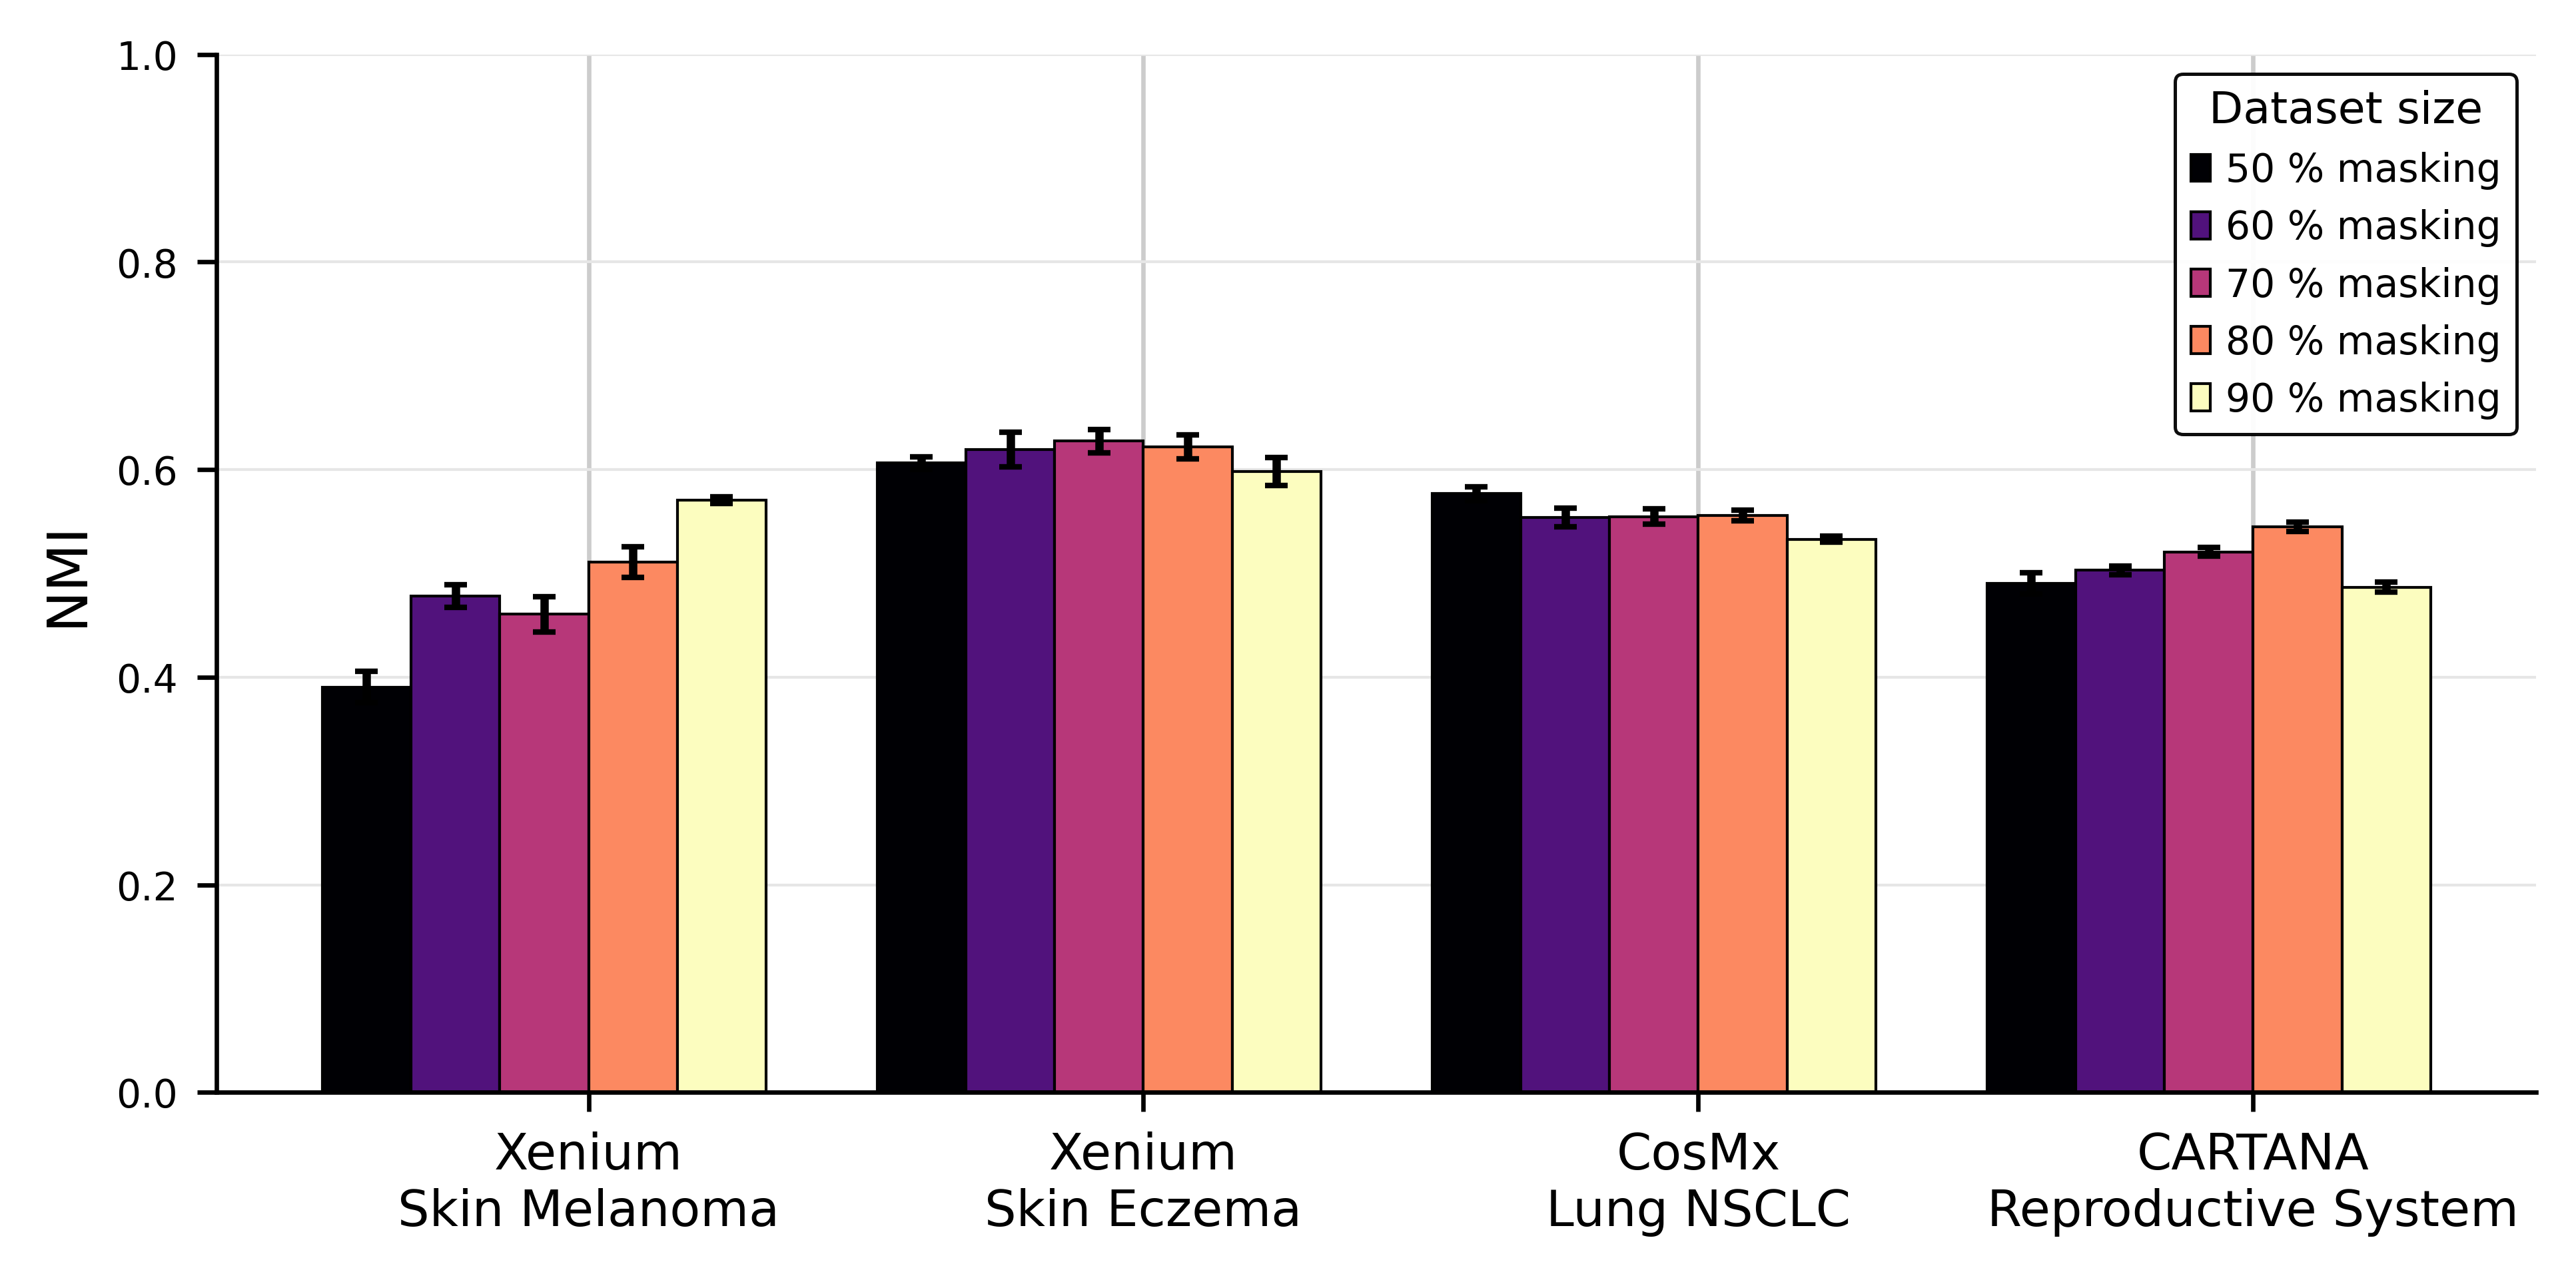

In [379]:
# --- Filter only NMI metric ---
df_nmi = df_neb[df_neb["metric"] == "NMI"]

# --- Compute mean and std per dataset × config ---
stats = (
    df_nmi.groupby(["dataset", "config"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)

# --- Enforce dataset order ---
desired_order = [
    "Xenium Skin Melanoma",
    "Xenium Skin Eczema",
    "CosMx Lung NSCLC",
    "CARTANA Reproductive System",
]
stats["dataset"] = pd.Categorical(stats["dataset"], categories=desired_order, ordered=True)
stats = stats.sort_values("dataset").reset_index(drop=True)

# --- Configurations ---
configs = sorted(stats["config"].unique(), key=lambda x: float(x.split("_")[0]))  # e.g. "1_pct_sample" → 1.0
config_labels = [cfg.replace("_", " ").replace("pct", "%").capitalize() for cfg in configs]

# --- Continuous colormap (light→dark gradient) ---
cmap = cm.get_cmap("magma", len(configs))
colors = [cmap(i) for i in range(len(configs))]

datasets = stats["dataset"].unique()
bar_width = 0.8 / len(configs)  # keep bars compact
x = range(len(datasets))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=300)

# --- Plot bars for each configuration ---
for i, cfg in enumerate(configs):
    subset = stats[stats["config"] == cfg]
    ax.bar(
        [xi + (i - len(configs)/2) * bar_width for xi in x],
        subset["mean"],
        yerr=subset["std"],
        width=bar_width,
        label=config_labels[i],
        color=colors[i],
        edgecolor="black",
        linewidth=0.5,
        capsize=2,
    )

# --- Wrap labels after the first word ---
def wrap_after_first_word(label):
    label = str(label)
    parts = label.split(" ", 1)
    return "\n".join(parts) if len(parts) > 1 else label

wrapped_labels = [wrap_after_first_word(ds) for ds in datasets]
ax.set_xticks(x)
ax.set_xticklabels(wrapped_labels, fontsize=9, ha="center")

# --- Aesthetics ---
ax.set_ylabel("NMI", fontsize=10)
ax.set_ylim(0, 1.0)

# --- Legend with colormap box ---
legend = ax.legend(
    frameon=True,
    fontsize=7,
    loc="upper right",
    framealpha=0.95,
    fancybox=True,
    edgecolor="black",
    title="Dataset size",
    title_fontsize=8,
)
legend.get_frame().set_linewidth(0.6)

# --- Clean spines and grid ---
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="0.9", linestyle="-", linewidth=0.5)
ax.set_axisbelow(True)

# --- Save figure ---
save_path = os.path.join(sc.settings.figdir, "masking_ratio_niche_nmi_comparison.svg")
plt.savefig(save_path, bbox_inches="tight", format="svg")
print(f"✅ Figure saved to: {save_path}")

plt.tight_layout()
plt.show()

/tmp/ipykernel_3221656/1338638353.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("magma", len(configs))


✅ Figure saved to: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/ablation/figures/masking_ratio_niche_ari_comparison.svg


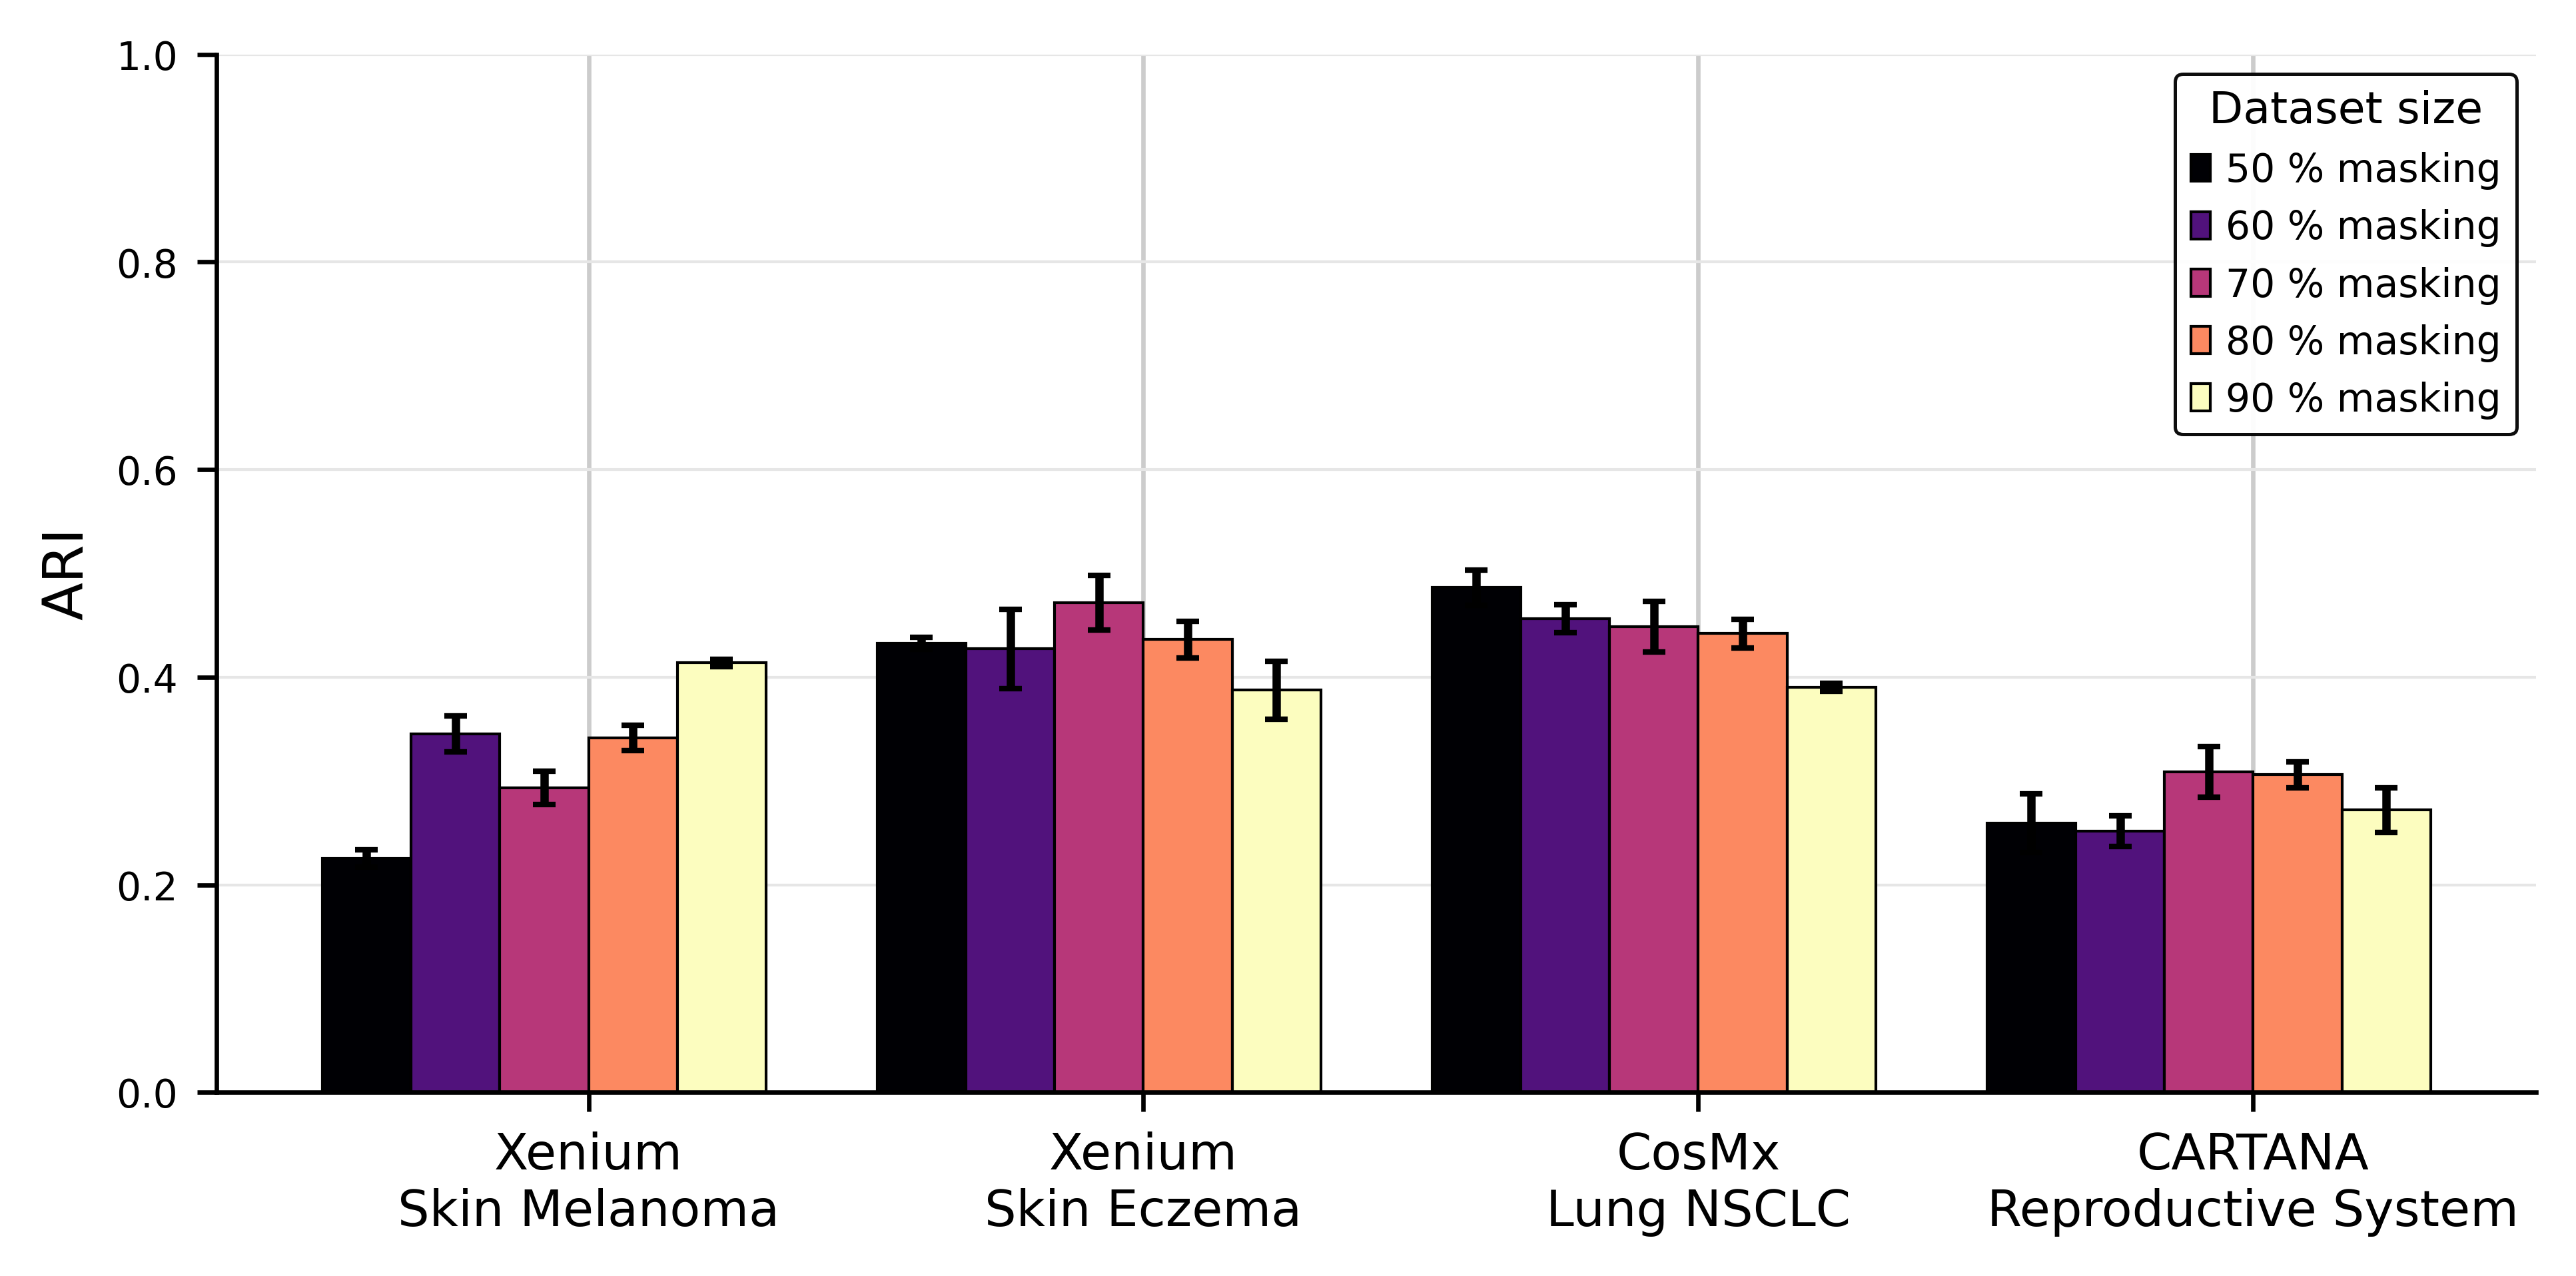

In [380]:
# --- Filter only ARI metric ---
df_ari = df_neb[df_neb["metric"] == "ARI"]

# --- Compute mean and std per dataset × config ---
stats = (
    df_ari.groupby(["dataset", "config"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)

# --- Enforce dataset order ---
desired_order = [
    "Xenium Skin Melanoma",
    "Xenium Skin Eczema",
    "CosMx Lung NSCLC",
    "CARTANA Reproductive System",
]
stats["dataset"] = pd.Categorical(stats["dataset"], categories=desired_order, ordered=True)
stats = stats.sort_values("dataset").reset_index(drop=True)

# --- Configurations ---
configs = sorted(stats["config"].unique(), key=lambda x: float(x.split("_")[0]))  # e.g. "1_pct_sample" → 1.0
config_labels = [cfg.replace("_", " ").replace("pct", "%").capitalize() for cfg in configs]

# --- Continuous colormap (light→dark gradient) ---
cmap = cm.get_cmap("magma", len(configs))
colors = [cmap(i) for i in range(len(configs))]

datasets = stats["dataset"].unique()
bar_width = 0.8 / len(configs)  # keep bars compact
x = range(len(datasets))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=300)

# --- Plot bars for each configuration ---
for i, cfg in enumerate(configs):
    subset = stats[stats["config"] == cfg]
    ax.bar(
        [xi + (i - len(configs)/2) * bar_width for xi in x],
        subset["mean"],
        yerr=subset["std"],
        width=bar_width,
        label=config_labels[i],
        color=colors[i],
        edgecolor="black",
        linewidth=0.5,
        capsize=2,
    )

# --- Wrap labels after the first word ---
def wrap_after_first_word(label):
    label = str(label)
    parts = label.split(" ", 1)
    return "\n".join(parts) if len(parts) > 1 else label

wrapped_labels = [wrap_after_first_word(ds) for ds in datasets]
ax.set_xticks(x)
ax.set_xticklabels(wrapped_labels, fontsize=9, ha="center")

# --- Aesthetics ---
ax.set_ylabel("ARI", fontsize=10)
ax.set_ylim(0, 1.0)

# --- Legend with colormap box ---
legend = ax.legend(
    frameon=True,
    fontsize=7,
    loc="upper right",
    framealpha=0.95,
    fancybox=True,
    edgecolor="black",
    title="Dataset size",
    title_fontsize=8,
)
legend.get_frame().set_linewidth(0.6)

# --- Clean spines and grid ---
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="0.9", linestyle="-", linewidth=0.5)
ax.set_axisbelow(True)

# --- Save figure ---
save_path = os.path.join(sc.settings.figdir, "masking_ratio_niche_ari_comparison.svg")
plt.savefig(save_path, bbox_inches="tight", format="svg")
print(f"✅ Figure saved to: {save_path}")

plt.tight_layout()
plt.show()

/tmp/ipykernel_3221656/1292272593.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("magma", len(configs))


✅ Figure saved to: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/ablation/figures/masking_ratio_cell_type_nmi_comparison.svg


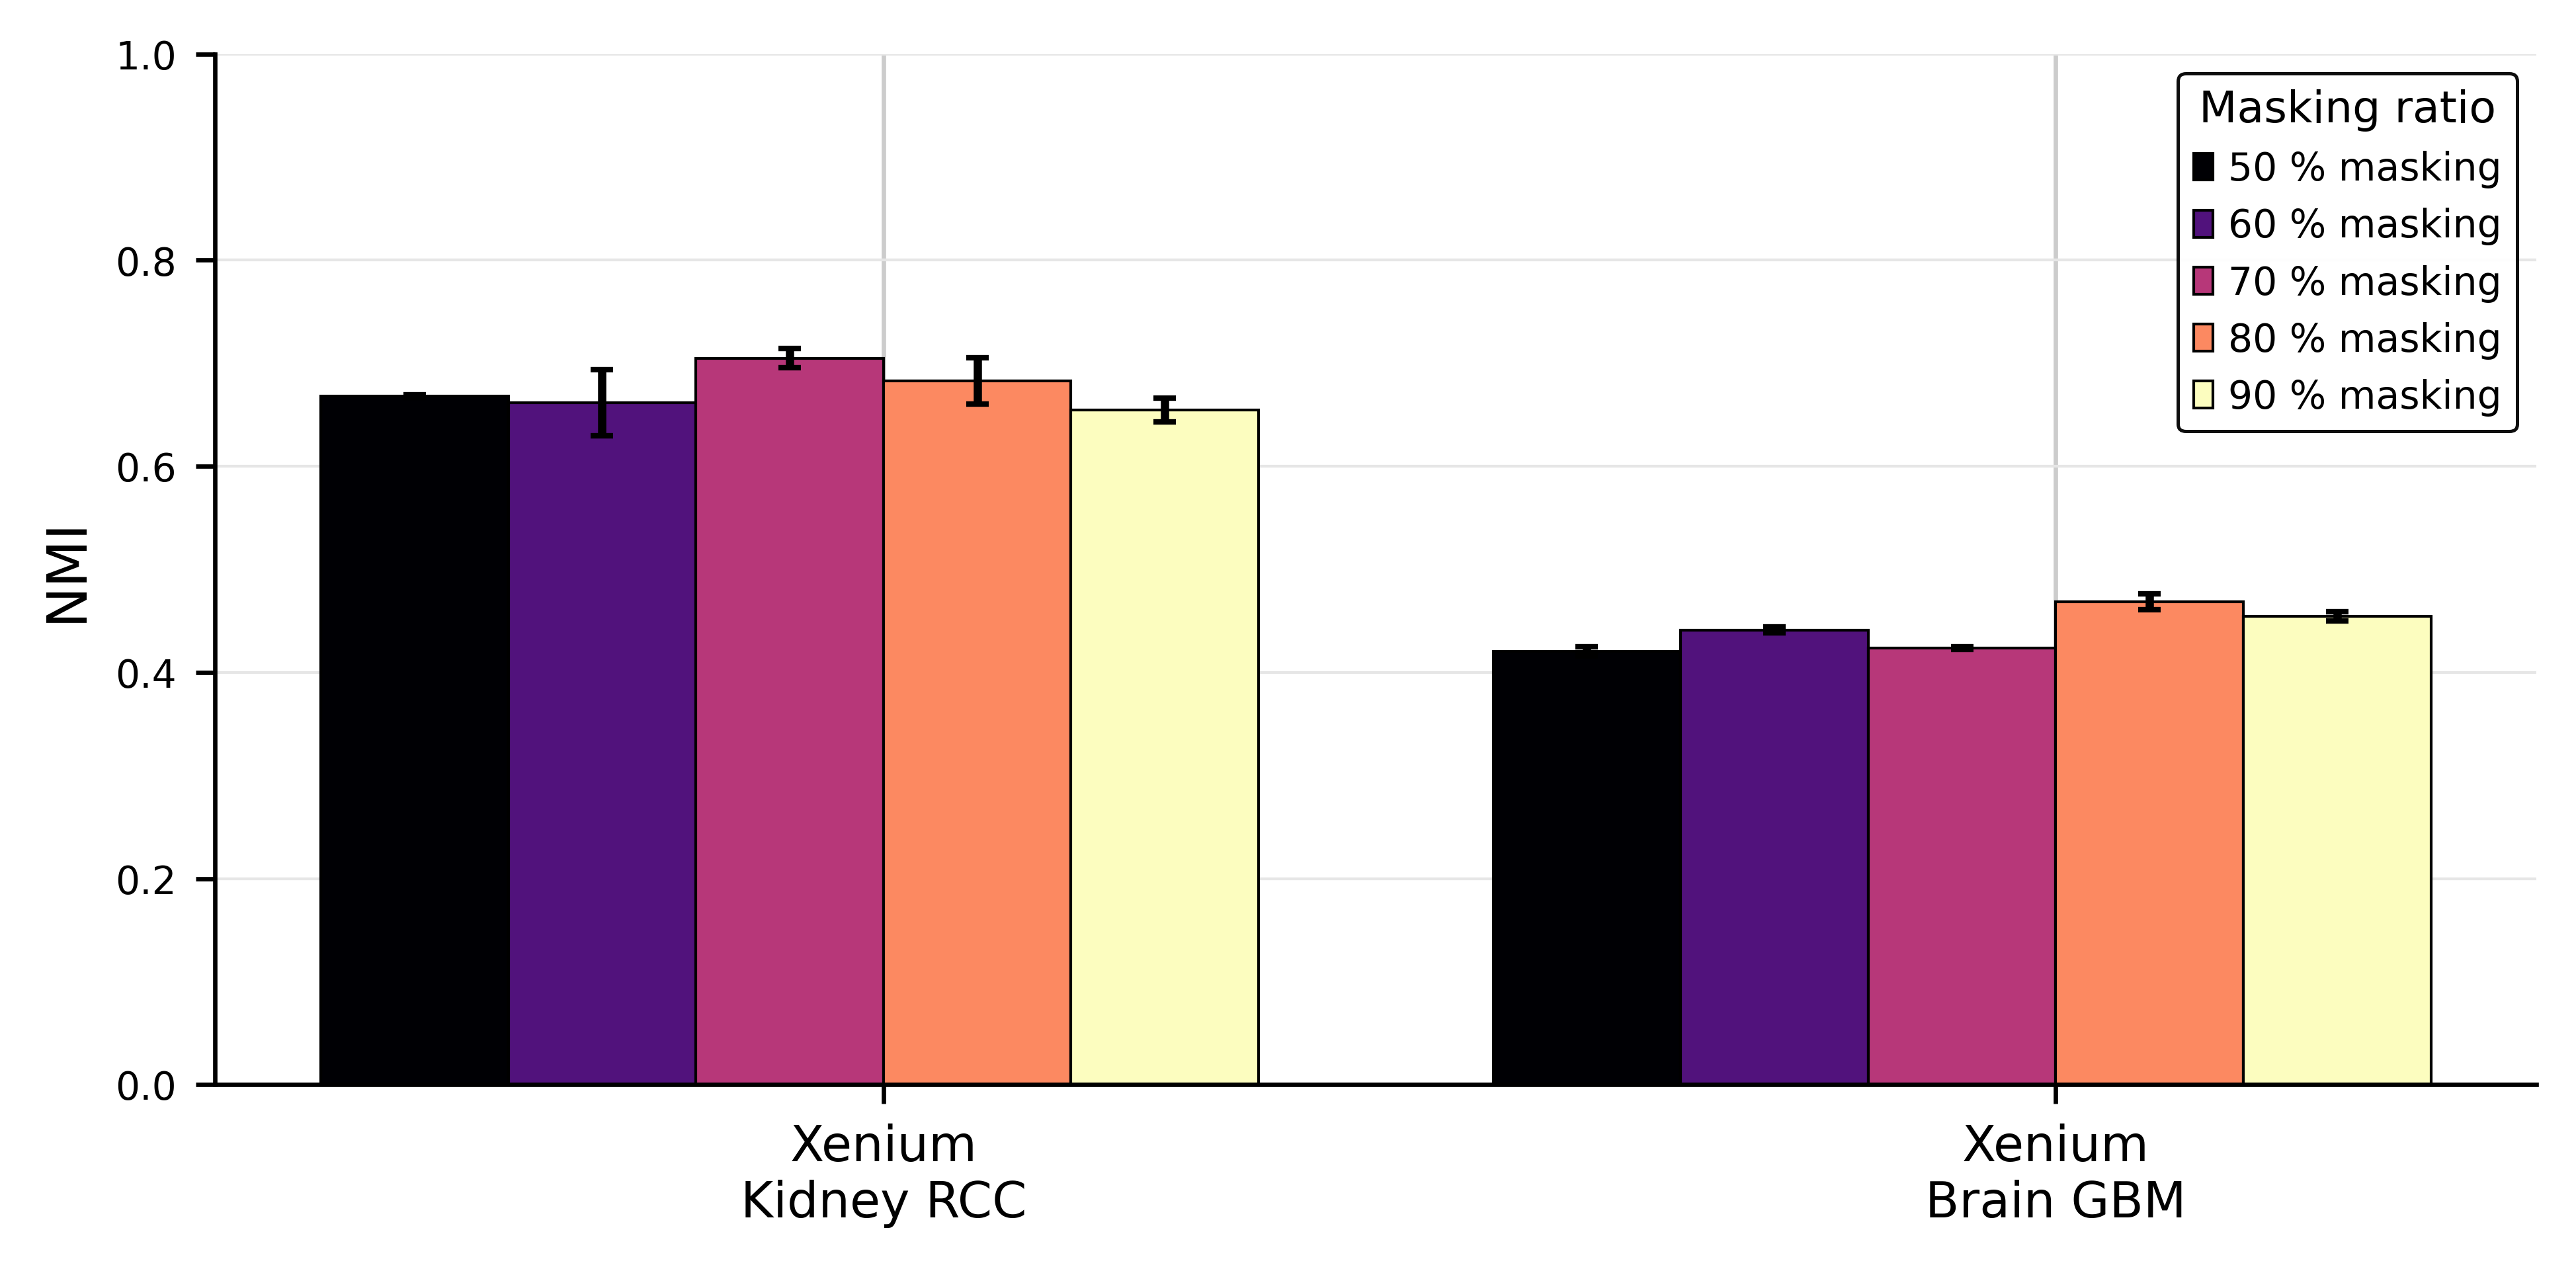

In [381]:
# --- Filter only NMI metric ---
df_nmi = df_cell[df_cell["metric"] == "NMI"]

# --- Compute mean and std per dataset × config ---
stats = (
    df_nmi.groupby(["dataset", "config"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)

# --- Enforce dataset order ---
desired_order = [
    "Xenium Kidney RCC",
    "Xenium Brain GBM"
]
stats["dataset"] = pd.Categorical(stats["dataset"], categories=desired_order, ordered=True)
stats = stats.sort_values("dataset").reset_index(drop=True)

# --- Configurations ---
configs = sorted(stats["config"].unique(), key=lambda x: float(x.split("_")[0]))  # e.g. "1_pct_sample" → 1.0
config_labels = [cfg.replace("_", " ").replace("pct", "%").capitalize() for cfg in configs]

# --- Continuous colormap (light→dark gradient) ---
cmap = cm.get_cmap("magma", len(configs))
colors = [cmap(i) for i in range(len(configs))]

datasets = stats["dataset"].unique()
bar_width = 0.8 / len(configs)  # keep bars compact
x = range(len(datasets))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=300)

# --- Plot bars for each configuration ---
for i, cfg in enumerate(configs):
    subset = stats[stats["config"] == cfg]
    ax.bar(
        [xi + (i - len(configs)/2) * bar_width for xi in x],
        subset["mean"],
        yerr=subset["std"],
        width=bar_width,
        label=config_labels[i],
        color=colors[i],
        edgecolor="black",
        linewidth=0.5,
        capsize=2,
    )

# --- Wrap labels after the first word ---
def wrap_after_first_word(label):
    label = str(label)
    parts = label.split(" ", 1)
    return "\n".join(parts) if len(parts) > 1 else label

wrapped_labels = [wrap_after_first_word(ds) for ds in datasets]
ax.set_xticks(x)
ax.set_xticklabels(wrapped_labels, fontsize=9, ha="center")

# --- Aesthetics ---
ax.set_ylabel("NMI", fontsize=10)
ax.set_ylim(0, 1.0)

# --- Legend with colormap box ---
legend = ax.legend(
    frameon=True,
    fontsize=7,
    loc="upper right",
    framealpha=0.95,
    fancybox=True,
    edgecolor="black",
    title="Masking ratio",
    title_fontsize=8,
)
legend.get_frame().set_linewidth(0.6)

# --- Clean spines and grid ---
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="0.9", linestyle="-", linewidth=0.5)
ax.set_axisbelow(True)

# --- Save figure ---
save_path = os.path.join(sc.settings.figdir, "masking_ratio_cell_type_nmi_comparison.svg")
plt.savefig(save_path, bbox_inches="tight", format="svg")
print(f"✅ Figure saved to: {save_path}")

plt.tight_layout()
plt.show()

/tmp/ipykernel_3221656/2626016401.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("magma", len(configs))


✅ Figure saved to: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/ablation/figures/masking_ratio_cell_type_ari_comparison.svg


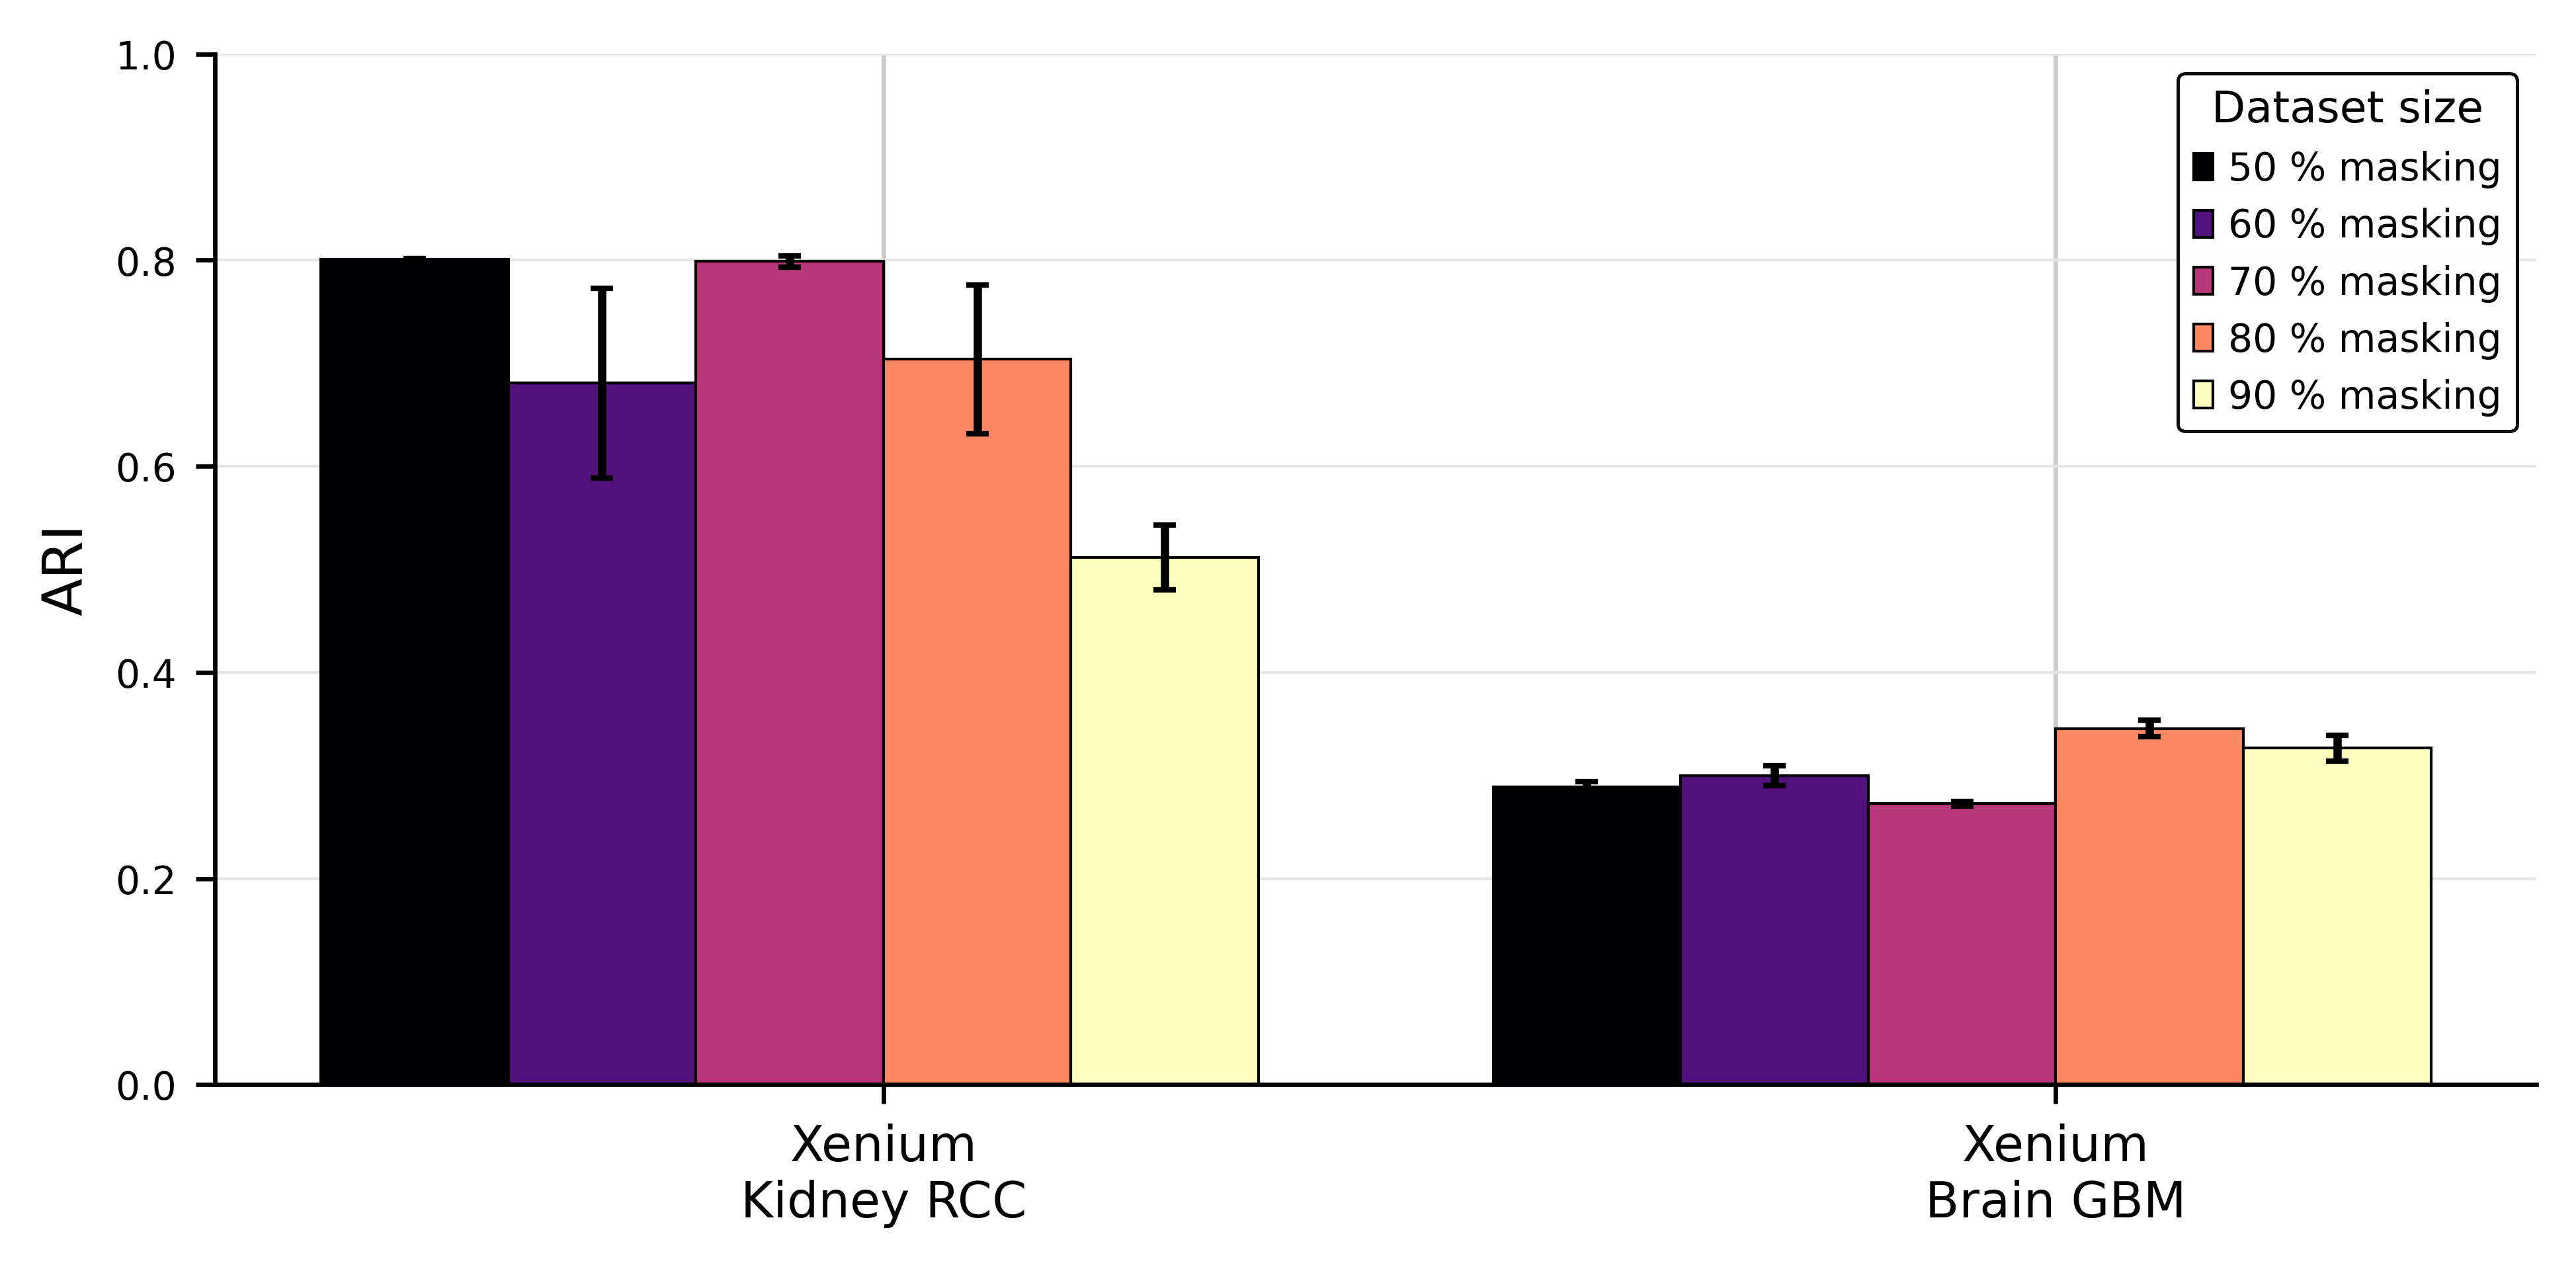

In [382]:
# --- Filter only ARI metric ---
df_ari = df_cell[df_cell["metric"] == "ARI"]

# --- Compute mean and std per dataset × config ---
stats = (
    df_ari.groupby(["dataset", "config"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)

# --- Enforce dataset order ---
desired_order = [
    "Xenium Kidney RCC",
    "Xenium Brain GBM"
]
stats["dataset"] = pd.Categorical(stats["dataset"], categories=desired_order, ordered=True)
stats = stats.sort_values("dataset").reset_index(drop=True)

# --- Configurations ---
configs = sorted(stats["config"].unique(), key=lambda x: float(x.split("_")[0]))  # e.g. "1_pct_sample" → 1.0
config_labels = [cfg.replace("_", " ").replace("pct", "%").capitalize() for cfg in configs]

# --- Continuous colormap (light→dark gradient) ---
cmap = cm.get_cmap("magma", len(configs))
colors = [cmap(i) for i in range(len(configs))]

datasets = stats["dataset"].unique()
bar_width = 0.8 / len(configs)  # keep bars compact
x = range(len(datasets))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=300)

# --- Plot bars for each configuration ---
for i, cfg in enumerate(configs):
    subset = stats[stats["config"] == cfg]
    ax.bar(
        [xi + (i - len(configs)/2) * bar_width for xi in x],
        subset["mean"],
        yerr=subset["std"],
        width=bar_width,
        label=config_labels[i],
        color=colors[i],
        edgecolor="black",
        linewidth=0.5,
        capsize=2,
    )

# --- Wrap labels after the first word ---
def wrap_after_first_word(label):
    label = str(label)
    parts = label.split(" ", 1)
    return "\n".join(parts) if len(parts) > 1 else label

wrapped_labels = [wrap_after_first_word(ds) for ds in datasets]
ax.set_xticks(x)
ax.set_xticklabels(wrapped_labels, fontsize=9, ha="center")

# --- Aesthetics ---
ax.set_ylabel("ARI", fontsize=10)
ax.set_ylim(0, 1.0)

# --- Legend with colormap box ---
legend = ax.legend(
    frameon=True,
    fontsize=7,
    loc="upper right",
    framealpha=0.95,
    fancybox=True,
    edgecolor="black",
    title="Dataset size",
    title_fontsize=8,
)
legend.get_frame().set_linewidth(0.6)

# --- Clean spines and grid ---
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="0.9", linestyle="-", linewidth=0.5)
ax.set_axisbelow(True)

# --- Save figure ---
save_path = os.path.join(sc.settings.figdir, "masking_ratio_cell_type_ari_comparison.svg")
plt.savefig(save_path, bbox_inches="tight", format="svg")
print(f"✅ Figure saved to: {save_path}")

plt.tight_layout()
plt.show()